<a href="https://colab.research.google.com/github/TITINSUGIHARTINI/Capstone_Project/blob/main/Pemodelan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Library**

In [ ]:
import pandas as pd                     # Untuk manipulasi data tabular (DataFrame)
import numpy as np                      # Untuk operasi numerik dan array
from collections import Counter         # Untuk menghitung frekuensi elemen

import matplotlib.pyplot as plt         # Untuk membuat plot dan visualisasi
import seaborn as sns                   # Untuk visualisasi statistik yang lebih menarik
import graphviz                         # Untuk visualisasi pohon keputusan
import itertools                        # Untuk membuat kombinasi/permutasi dalam visualisasi atau logika

import zipfile                          # Untuk ekstrak file zip
import os                               # Untuk operasi terkait sistem file

from scipy.stats import pearsonr        # Untuk menghitung korelasi Pearson

from sklearn.preprocessing import StandardScaler   # Untuk standardisasi fitur
from sklearn.preprocessing import LabelEncoder     # Untuk encoding label kategorikal menjadi angka

from sklearn.model_selection import train_test_split  # Untuk membagi data menjadi train/test
from sklearn.model_selection import KFold             # Untuk K-Fold cross-validation
from sklearn.model_selection import cross_val_score   # Untuk evaluasi model dengan cross-validation

from imblearn.pipeline import Pipeline       # Untuk membangun pipeline modeling dari imbalanced-learn
from imblearn.over_sampling import SMOTE     # Untuk mengatasi imbalance dengan teknik oversampling

from sklearn.ensemble import RandomForestClassifier        # Model Random Forest untuk klasifikasi
from sklearn.ensemble import GradientBoostingClassifier    # Model Gradient Boosting untuk klasifikasi
from sklearn.ensemble import AdaBoostClassifier            # Model AdaBoost untuk klasifikasi
from sklearn.ensemble import StackingClassifier            # Model stacking untuk gabungan beberapa model klasifikasi
from sklearn.tree import DecisionTreeClassifier            # Model Decision Tree untuk klasifikasi
from xgboost import XGBClassifier                          # Model XGBoost untuk klasifikasi

from sklearn.ensemble import RandomForestRegressor         # Random Forest untuk regresi
from sklearn.ensemble import GradientBoostingRegressor     # Gradient Boosting untuk regresi
from sklearn.ensemble import AdaBoostRegressor             # AdaBoost untuk regresi
from xgboost import XGBRegressor                           # XGBoost untuk regresi

from sklearn.metrics import accuracy_score         # Menghitung akurasi klasifikasi
from sklearn.metrics import classification_report  # Menampilkan laporan klasifikasi
from sklearn.metrics import confusion_matrix        # Menampilkan confusion matrix
from sklearn.metrics import mean_squared_error      # Metrik regresi: MSE
from sklearn.metrics import r2_score                # Metrik regresi: R-squared
from sklearn.metrics import mean_absolute_error     # Metrik regresi: MAE
from sklearn.metrics import median_absolute_error   # Metrik regresi: MedAE

from sklearn.tree import export_graphviz            # Ekspor visual pohon keputusan

# **Dataset Awal**

In [ ]:
# Membaca file CSV ke dalam DataFrame
df = pd.read_csv('data_awal.csv')
print("Jumlah Data:", df.shape)
df.head()

Jumlah Data: (1610, 17)


,No,Kode,Nama Perusahaan,Tahun,Pendapatan (Rp),Laba Bersih (Rp),Total Aset (Rp),Utang (Rp),Rasio Profitabilitas (Rp),Skor Sentimen Analisis,Sentimen Analisis (X),Skor Sentimen Analisis (X),Sentimen Analisis (Play Store),Skor Sentimen Analisis (Play Store),Skor ESG (MS),Skor ESG (LSEG),Skor ESG (OCR)
0,1,PGEO,PT Pertamina Geothermal Energy Tbk,2023,6.250.334.592.000,2.516.360.880.000,45.600.345.144.000,15.274.542.840.000,"40,26%",NaN,Positif,"0,076",NaN,NaN,"7,11","49,64","11,13"
1,2,MPMX,PT Mitra Pinasthika Mustika Tbk,2023,13.859.071.000.000,525.638.000.000,8.599.026.000.000,2.487.113.000.000,"3,80%",NaN,Positif,"0,092",NaN,NaN,"10,05",NaN,"16,33"
2,3,JSMR,PT Jasa Marga Tbk,2023,15.566.000.000.000,6.749.000.000.000,129.312.000.000.000,90.401.000.000.000,"43,65%",NaN,Positif,"0,011",NaN,NaN,"10,73","58,7","13,34"
3,4,EMTK,PT Elang Mahkota Teknologi Tbk,2023,9.241.000.000.000,-240.000.000.000,42.891.000.000.000,4.520.000.000.000,"-1,50%",NaN,Negatif,"-0,01",NaN,NaN,"14,17","88,93","11,16"
4,5,ERAA,PT Erajaya Swasembada Tbk,2023,60.139.406.000.000,856.861.000.000,20.447.452.000.000,12.316.678.000.000,"2,60%",NaN,Positif,"0,062",NaN,NaN,"14,66",NaN,"15,50"




---


# **Skenario 1:** Independen Atribut Numerik + Target Numerik

# Data1: Target ESG MS

In [ ]:
# Membaca file CSV ke dalam DataFrame
df = pd.read_csv('data1_ms_preprocessing.csv')
print("Jumlah Data:", df.shape)
df.head()

Jumlah Data: (69, 7)


,Pendapatan (Rp),Laba Bersih (Rp),Total Aset (Rp),Utang (Rp),Rasio Profitabilitas (Rp),Skor Sentimen Analisis (X),Skor ESG (MS)
0,6.250335e+12,2.516361e+12,4.560035e+13,1.527454e+13,0.4026,0.076,7.11
1,1.385907e+13,5.256380e+11,8.599026e+12,2.487113e+12,0.0380,0.092,10.05
2,1.556600e+13,6.749000e+12,1.293120e+14,9.040100e+13,0.4336,0.011,10.73
3,9.241000e+12,-2.400000e+11,4.289100e+13,4.520000e+12,-0.0150,-0.010,14.17
4,6.013941e+13,8.568610e+11,2.044745e+13,1.231668e+13,0.0260,0.062,14.66


## Pemodelan[Awal]

In [ ]:
# Persiapan data untuk pemodelan
# Definisikan X dan y
X = df.drop('Skor ESG (MS)', axis=1)
y = df['Skor ESG (MS)']

In [ ]:
# Fungsi untuk evaluasi model regresi
def evaluate_regression_model(model, X_train, X_test, y_train, y_test, model_name):
    # Latih model
    model.fit(X_train, y_train)

    # Prediksi
    y_pred = model.predict(X_test)

    # Evaluasi
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    medae = median_absolute_error(y_test, y_pred)

    print(f"Metrik Evaluasi {model_name}:")
    print(f"  - Mean Squared Error (MSE): {mse:.4f}")
    print(f"  - Root Mean Squared Error (RMSE): {rmse:.4f}")
    print(f"  - R²: {r2:.4f}")
    print(f"  - Mean Absolute Error (MAE): {mae:.4f}")
    print(f"  - Median Absolute Error (MedAE): {medae:.4f}")

    # Visualisasi prediksi vs aktual
    plt.figure(figsize=(10, 6))
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], 'r--')
    plt.xlabel('Nilai Aktual')
    plt.ylabel('Nilai Prediksi')
    plt.title(f'Prediksi vs Aktual - {model_name}')
    plt.show()

    return model, mse, r2

##testsize 0.2

In [ ]:
# Bagi dataset menjadi set pelatihan dan pengujian
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# # Standarisasi fitur numerik (Normalisasi)
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)

Dataset berhasil disiapkan:
Jumlah fitur: 6
Jumlah sampel: 69
Fitur: Pendapatan (Rp), Laba Bersih (Rp), Total Aset (Rp), Utang (Rp), Rasio Profitabilitas (Rp), Skor Sentimen Analisis (X)

Jumlah data pelatihan: 55
Jumlah data pengujian: 14


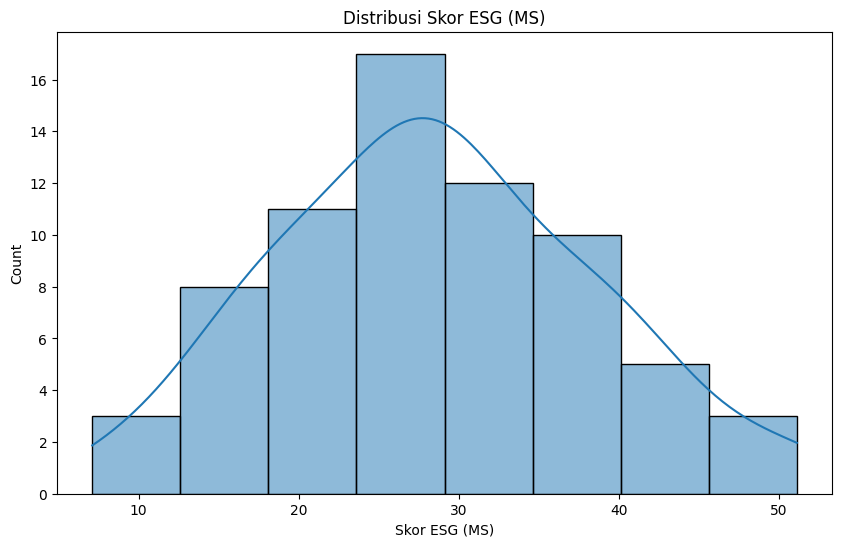

In [ ]:
print("Dataset berhasil disiapkan:")
print(f"Jumlah fitur: {X.shape[1]}")
print(f"Jumlah sampel: {X.shape[0]}")
print(f"Fitur: {', '.join(X.columns)}")
print(f"\nJumlah data pelatihan: {X_train.shape[0]}")
print(f"Jumlah data pengujian: {X_test.shape[0]}")

# Visualisasi distribusi target
plt.figure(figsize=(10, 6))
sns.histplot(y, kde=True)
plt.title('Distribusi Skor ESG (MS)')
plt.xlabel('Skor ESG (MS)')
plt.show()

### Random forest Regresor

Metrik Evaluasi rRandom Forest Regressor:
  - Mean Squared Error (MSE): 114.7804
  - Root Mean Squared Error (RMSE): 10.7136
  - R²: -0.4464
  - Mean Absolute Error (MAE): 8.9215
  - Median Absolute Error (MedAE): 8.0660


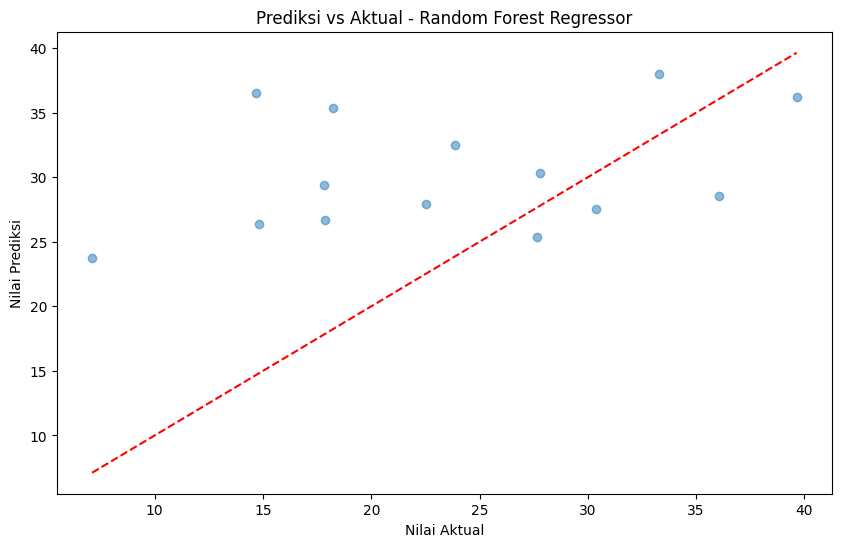

In [ ]:
# 1. Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_results = evaluate_regression_model(rf_model, X_train, X_test, y_train, y_test, "Random Forest Regressor")

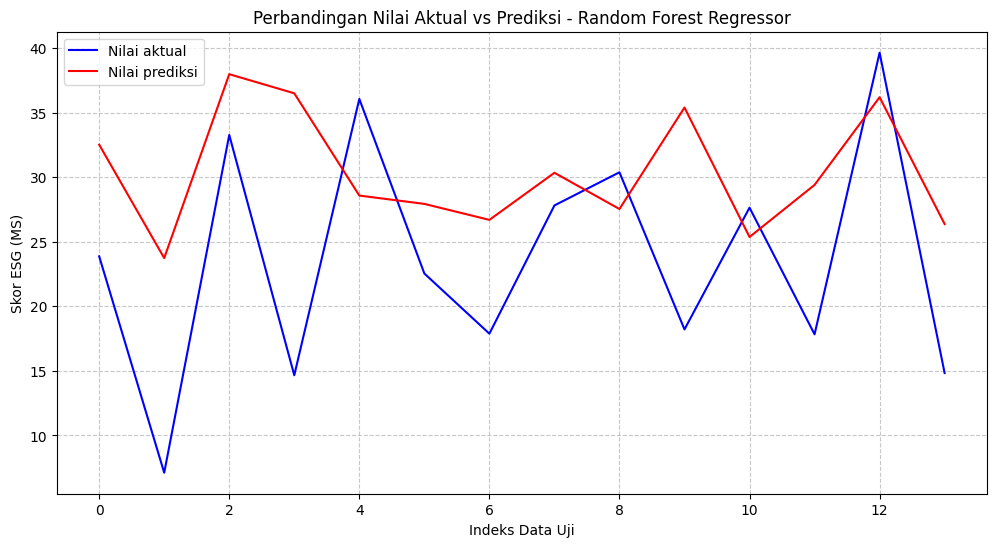

In [ ]:
# Plot perbandingan nilai aktual vs prediksi untuk Random Forest Regressor
y_pred_rf = rf_model.predict(X_test)
x_ax = range(len(y_test))
plt.figure(figsize=(12, 6))
plt.plot(x_ax, y_test, label="Nilai aktual", color="blue")
plt.plot(x_ax, y_pred_rf, label="Nilai prediksi", color="red")
plt.title("Perbandingan Nilai Aktual vs Prediksi - Random Forest Regressor")
plt.xlabel("Indeks Data Uji")
plt.ylabel("Skor ESG (MS)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### XGBoost Regresi

Metrik Evaluasi rXGBoost Regressor:
  - Mean Squared Error (MSE): 158.2618
  - Root Mean Squared Error (RMSE): 12.5802
  - R²: -0.9944
  - Mean Absolute Error (MAE): 10.8741
  - Median Absolute Error (MedAE): 9.6962


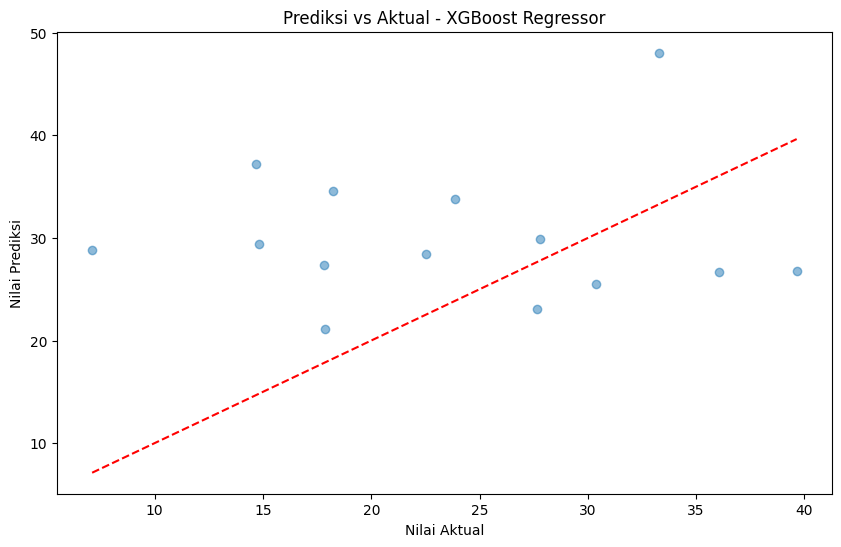

In [ ]:
# 2. XGBoost Regressor
xgb_model = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
xgb_results = evaluate_regression_model(xgb_model, X_train, X_test, y_train, y_test, "XGBoost Regressor")

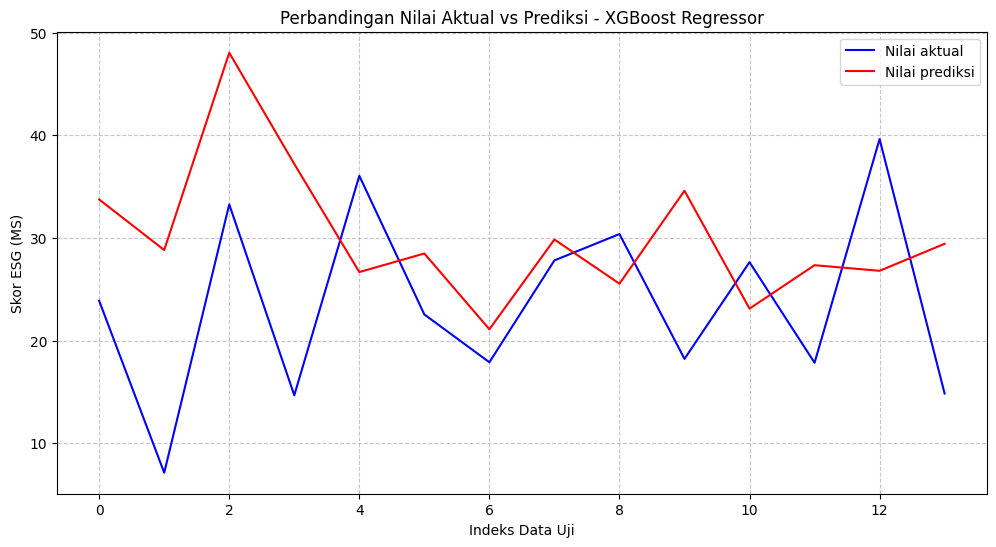

In [ ]:
# Plot perbandingan nilai aktual vs prediksi untuk Random Forest Regressor
y_pred_xgb = xgb_model.predict(X_test)
x_ax = range(len(y_test))
plt.figure(figsize=(12, 6))
plt.plot(x_ax, y_test, label="Nilai aktual", color="blue")
plt.plot(x_ax, y_pred_xgb, label="Nilai prediksi", color="red")
plt.title("Perbandingan Nilai Aktual vs Prediksi - XGBoost Regressor")
plt.xlabel("Indeks Data Uji")
plt.ylabel("Skor ESG (MS)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### ADAboost Regresi

Metrik Evaluasi rAdaBoost Regressor:
  - Mean Squared Error (MSE): 119.0258
  - Root Mean Squared Error (RMSE): 10.9099
  - R²: -0.4999
  - Mean Absolute Error (MAE): 8.6685
  - Median Absolute Error (MedAE): 6.6061


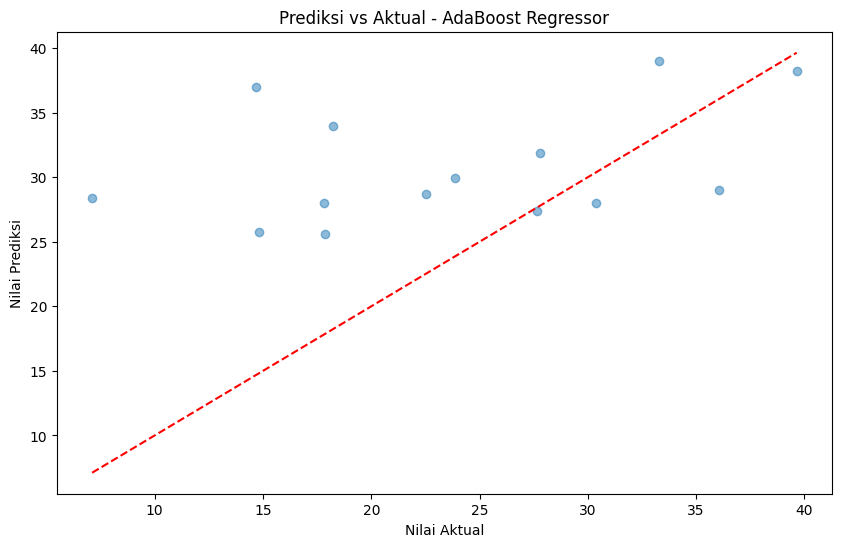

In [ ]:
# 3. AdaBoost Regressor
ada_model = AdaBoostRegressor(n_estimators=100, random_state=42)
ada_results = evaluate_regression_model(ada_model, X_train, X_test, y_train, y_test, "AdaBoost Regressor")

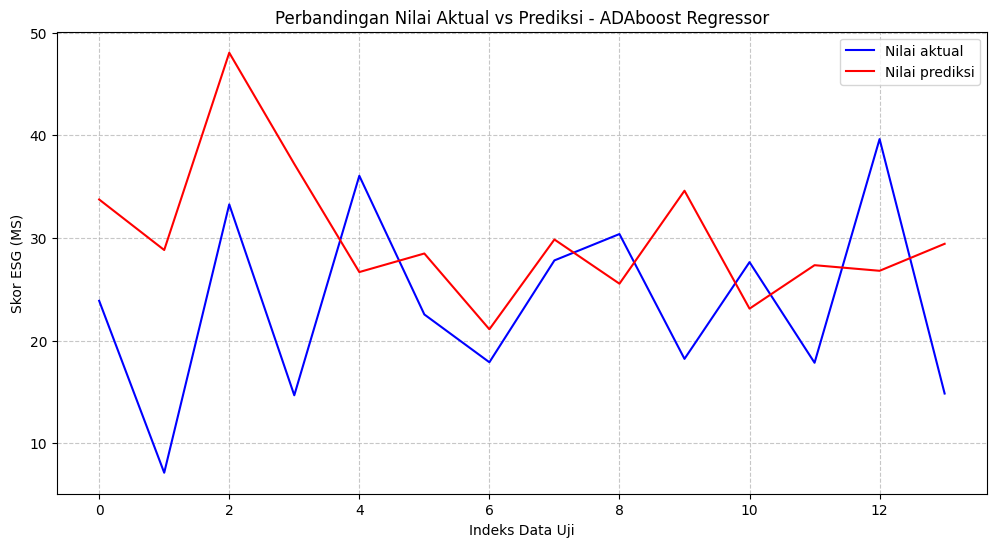

In [ ]:
# Plot perbandingan nilai aktual vs prediksi untuk Random Forest Regressor
y_pred_ada = ada_model.predict(X_test)
x_ax = range(len(y_test))
plt.figure(figsize=(12, 6))
plt.plot(x_ax, y_test, label="Nilai aktual", color="blue")
plt.plot(x_ax, y_pred_xgb, label="Nilai prediksi", color="red")
plt.title("Perbandingan Nilai Aktual vs Prediksi - ADAboost Regressor")
plt.xlabel("Indeks Data Uji")
plt.ylabel("Skor ESG (MS)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

##testsize 0.3

In [ ]:
# Bagi dataset menjadi set pelatihan dan pengujian
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [ ]:
# # Standarisasi fitur numerik (Normalisasi)
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)

Dataset berhasil disiapkan:
Jumlah fitur: 6
Jumlah sampel: 69
Fitur: Pendapatan (Rp), Laba Bersih (Rp), Total Aset (Rp), Utang (Rp), Rasio Profitabilitas (Rp), Skor Sentimen Analisis (X)

Jumlah data pelatihan: 48
Jumlah data pengujian: 21


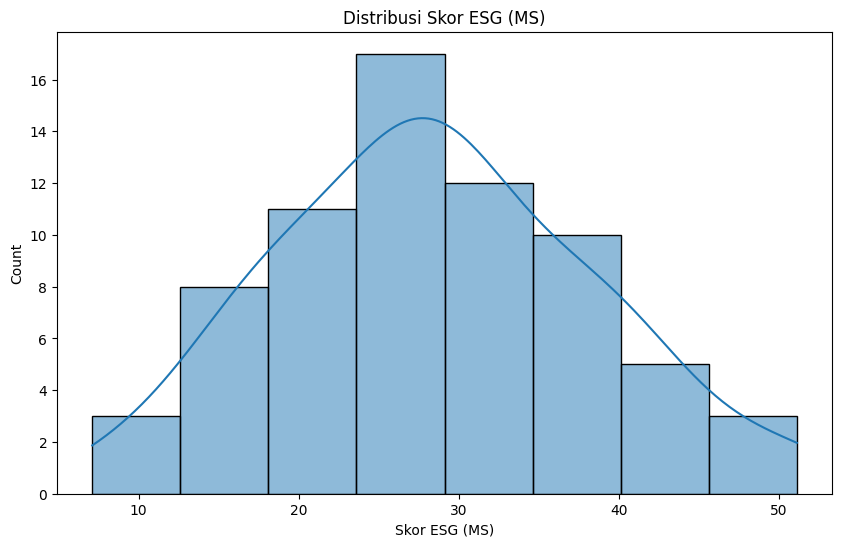

In [ ]:
print("Dataset berhasil disiapkan:")
print(f"Jumlah fitur: {X.shape[1]}")
print(f"Jumlah sampel: {X.shape[0]}")
print(f"Fitur: {', '.join(X.columns)}")
print(f"\nJumlah data pelatihan: {X_train.shape[0]}")
print(f"Jumlah data pengujian: {X_test.shape[0]}")

# Visualisasi distribusi target
plt.figure(figsize=(10, 6))
sns.histplot(y, kde=True)
plt.title('Distribusi Skor ESG (MS)')
plt.xlabel('Skor ESG (MS)')
plt.show()

### Random forest Regresor

Metrik Evaluasi rRandom Forest Regressor:
  - Mean Squared Error (MSE): 109.8497
  - Root Mean Squared Error (RMSE): 10.4809
  - R²: -0.0525
  - Mean Absolute Error (MAE): 8.3758
  - Median Absolute Error (MedAE): 7.2698


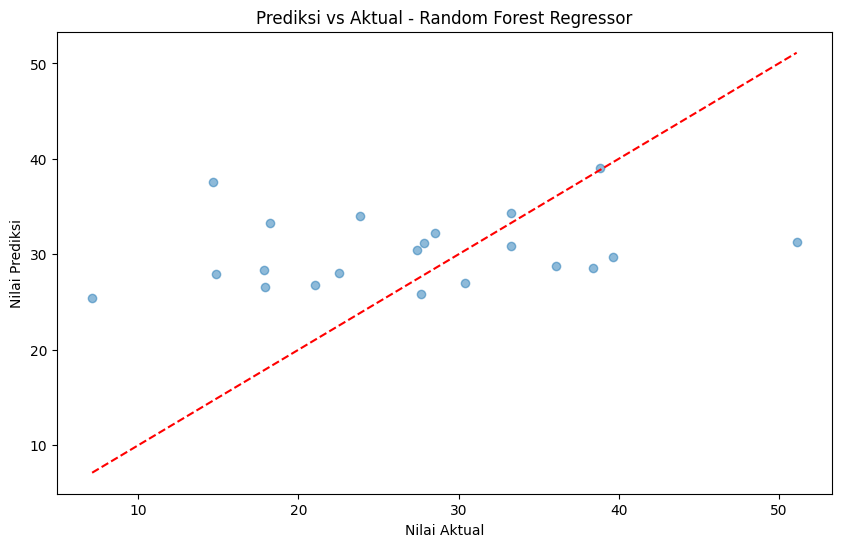

In [ ]:
# 1. Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_results = evaluate_regression_model(rf_model, X_train, X_test, y_train, y_test, "Random Forest Regressor")


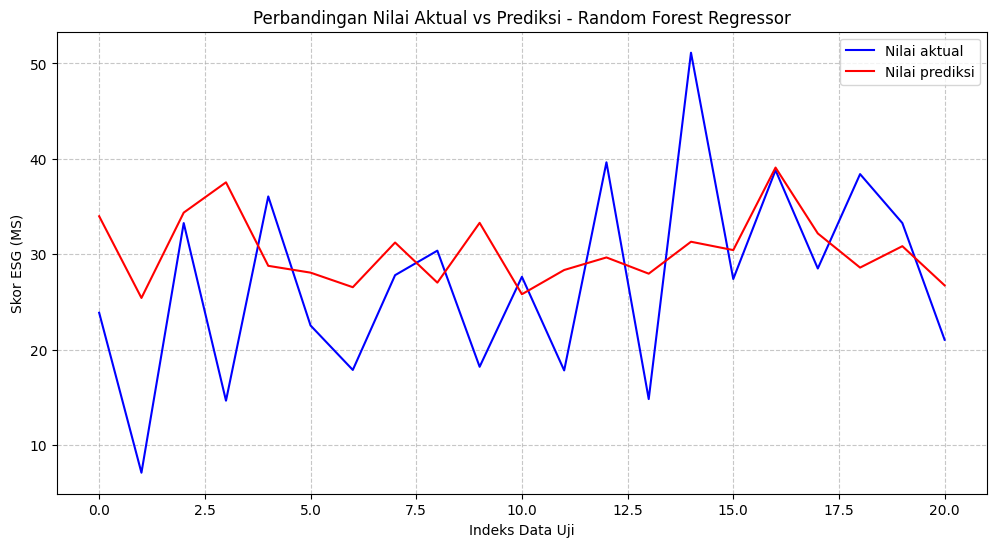

In [ ]:
# Plot perbandingan nilai aktual vs prediksi untuk Random Forest Regressor
y_pred_rf = rf_model.predict(X_test)
x_ax = range(len(y_test))
plt.figure(figsize=(12, 6))
plt.plot(x_ax, y_test, label="Nilai aktual", color="blue")
plt.plot(x_ax, y_pred_rf, label="Nilai prediksi", color="red")
plt.title("Perbandingan Nilai Aktual vs Prediksi - Random Forest Regressor")
plt.xlabel("Indeks Data Uji")
plt.ylabel("Skor ESG (MS)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### XGBoost Regresi

Metrik Evaluasi rXGBoost Regressor:
  - Mean Squared Error (MSE): 138.8938
  - Root Mean Squared Error (RMSE): 11.7853
  - R²: -0.3307
  - Mean Absolute Error (MAE): 9.2257
  - Median Absolute Error (MedAE): 8.3965


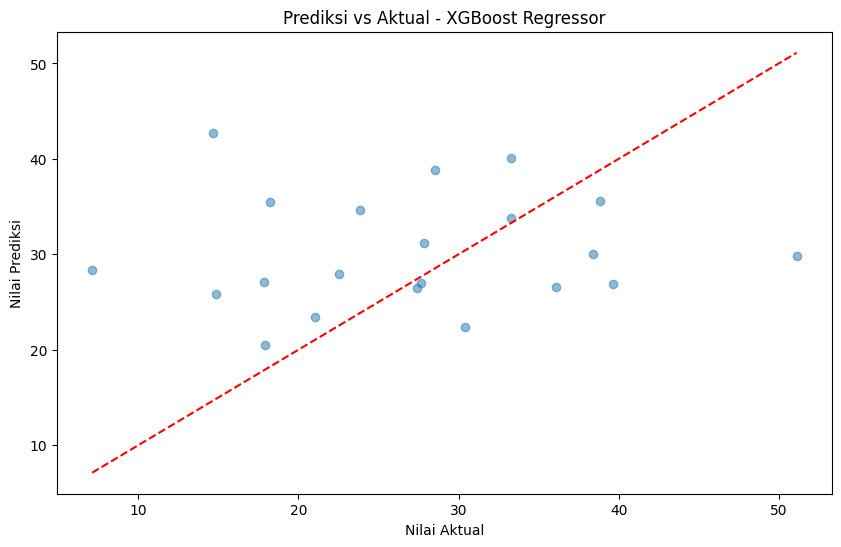

In [ ]:
# 2. XGBoost Regressor
xgb_model = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
xgb_results = evaluate_regression_model(xgb_model, X_train, X_test, y_train, y_test, "XGBoost Regressor")


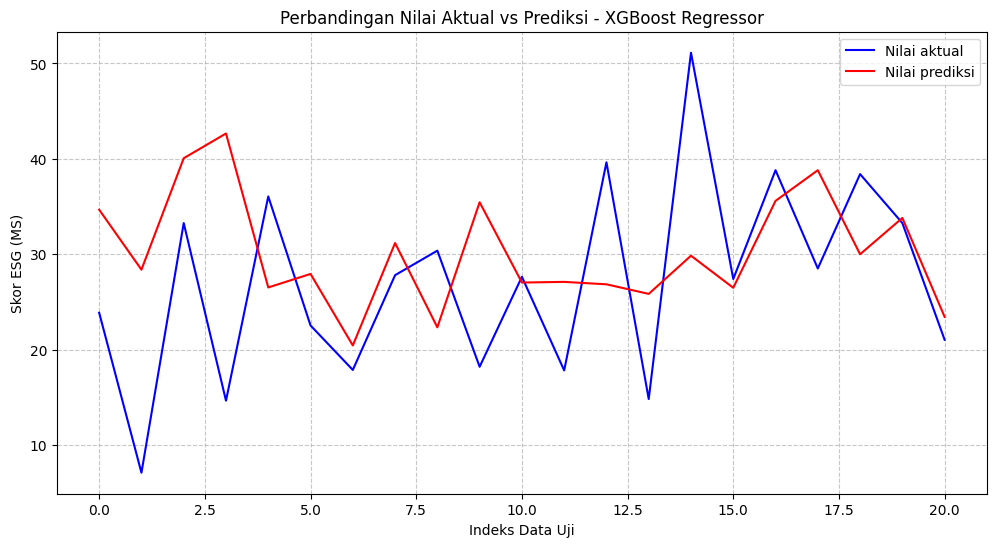

In [ ]:
# Plot perbandingan nilai aktual vs prediksi untuk Random Forest Regressor
y_pred_xgb = xgb_model.predict(X_test)
x_ax = range(len(y_test))
plt.figure(figsize=(12, 6))
plt.plot(x_ax, y_test, label="Nilai aktual", color="blue")
plt.plot(x_ax, y_pred_xgb, label="Nilai prediksi", color="red")
plt.title("Perbandingan Nilai Aktual vs Prediksi - XGBoost Regressor")
plt.xlabel("Indeks Data Uji")
plt.ylabel("Skor ESG (MS)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### ADAboost Regresi

Metrik Evaluasi rAdaBoost Regressor:
  - Mean Squared Error (MSE): 102.4124
  - Root Mean Squared Error (RMSE): 10.1199
  - R²: 0.0188
  - Mean Absolute Error (MAE): 7.7162
  - Median Absolute Error (MedAE): 6.3288


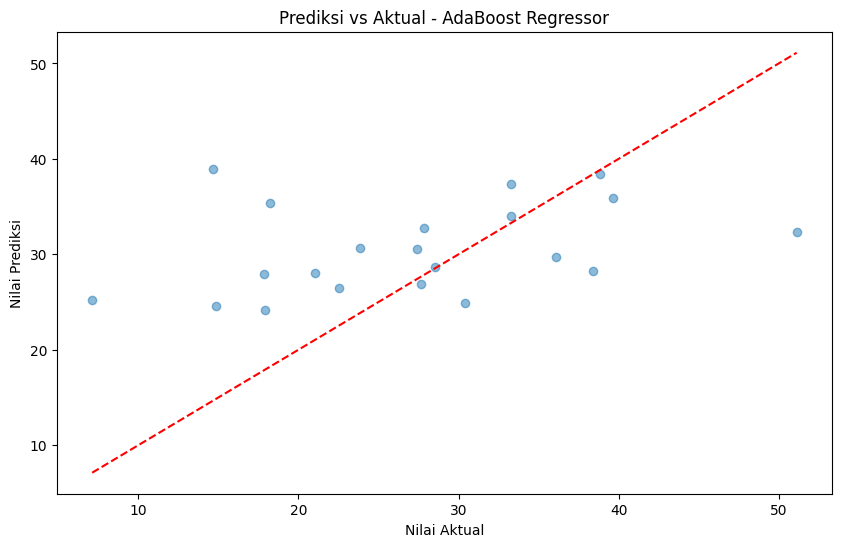

In [ ]:
# 3. AdaBoost Regressor
ada_model = AdaBoostRegressor(n_estimators=100, random_state=42)
ada_results = evaluate_regression_model(ada_model, X_train, X_test, y_train, y_test, "AdaBoost Regressor")


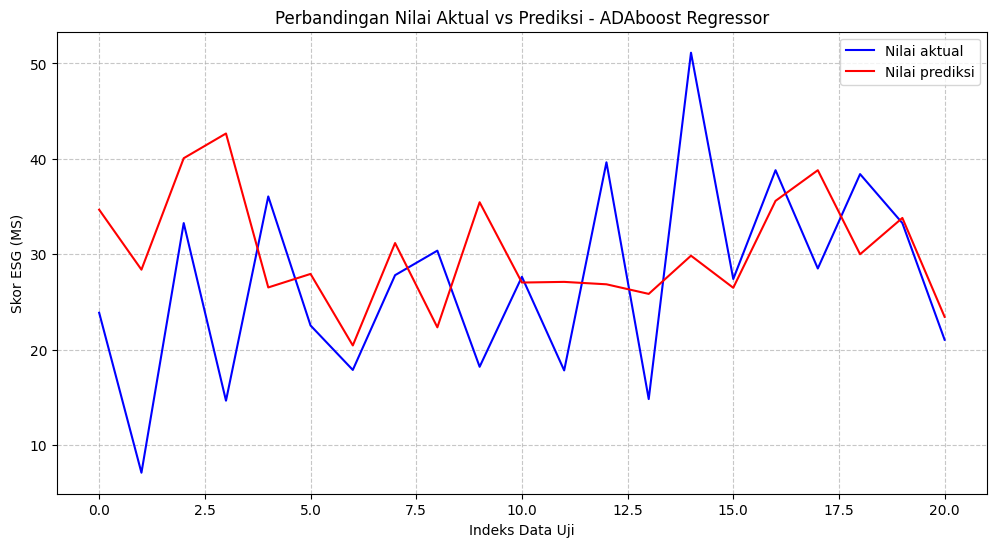

In [ ]:
# Plot perbandingan nilai aktual vs prediksi untuk Random Forest Regressor
y_pred_ada = ada_model.predict(X_test)
x_ax = range(len(y_test))
plt.figure(figsize=(12, 6))
plt.plot(x_ax, y_test, label="Nilai aktual", color="blue")
plt.plot(x_ax, y_pred_xgb, label="Nilai prediksi", color="red")
plt.title("Perbandingan Nilai Aktual vs Prediksi - ADAboost Regressor")
plt.xlabel("Indeks Data Uji")
plt.ylabel("Skor ESG (MS)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

##testsize 0.4

In [ ]:
# Bagi dataset menjadi set pelatihan dan pengujian
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

In [ ]:
# # Standarisasi fitur numerik (Normalisasi)
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)

Dataset berhasil disiapkan:
Jumlah fitur: 6
Jumlah sampel: 69
Fitur: Pendapatan (Rp), Laba Bersih (Rp), Total Aset (Rp), Utang (Rp), Rasio Profitabilitas (Rp), Skor Sentimen Analisis (X)

Jumlah data pelatihan: 41
Jumlah data pengujian: 28


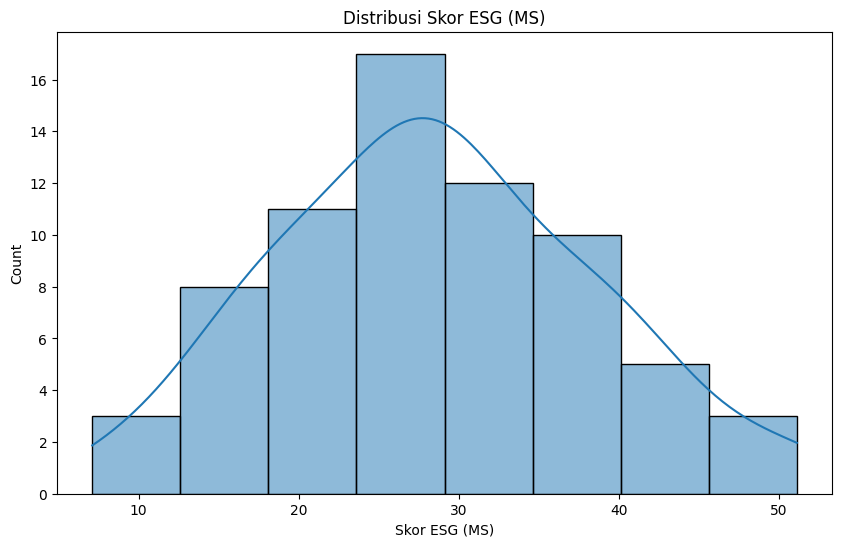

In [ ]:
print("Dataset berhasil disiapkan:")
print(f"Jumlah fitur: {X.shape[1]}")
print(f"Jumlah sampel: {X.shape[0]}")
print(f"Fitur: {', '.join(X.columns)}")
print(f"\nJumlah data pelatihan: {X_train.shape[0]}")
print(f"Jumlah data pengujian: {X_test.shape[0]}")

# Visualisasi distribusi target
plt.figure(figsize=(10, 6))
sns.histplot(y, kde=True)
plt.title('Distribusi Skor ESG (MS)')
plt.xlabel('Skor ESG (MS)')
plt.show()

### Random forest Regresor

Metrik Evaluasi rRandom Forest Regressor:
  - Mean Squared Error (MSE): 89.9920
  - Root Mean Squared Error (RMSE): 9.4864
  - R²: 0.0207
  - Mean Absolute Error (MAE): 7.1831
  - Median Absolute Error (MedAE): 5.2424


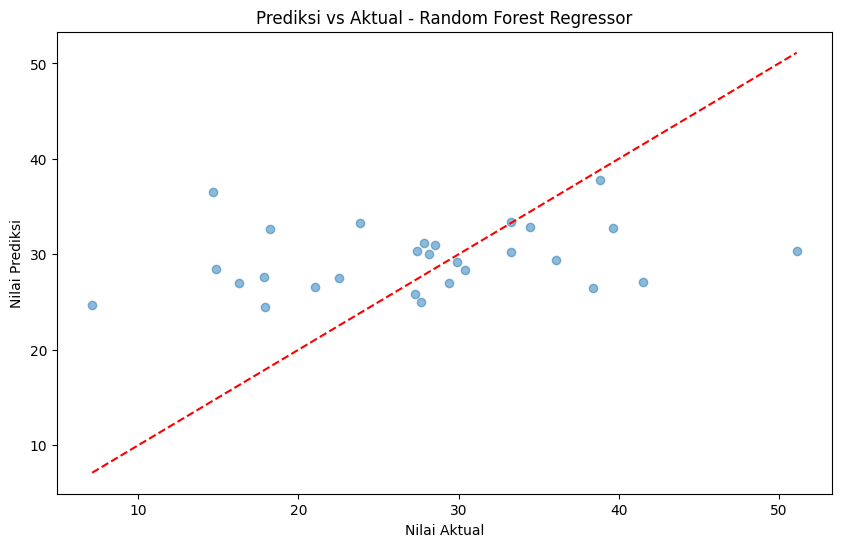

In [ ]:
# 1. Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_results = evaluate_regression_model(rf_model, X_train, X_test, y_train, y_test, "Random Forest Regressor")


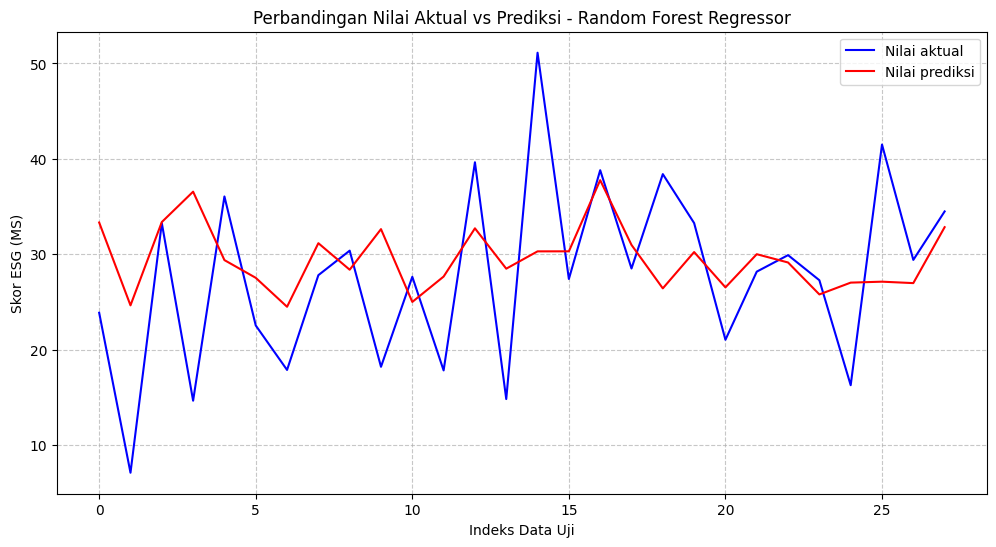

In [ ]:
# Plot perbandingan nilai aktual vs prediksi untuk Random Forest Regressor
y_pred_rf = rf_model.predict(X_test)
x_ax = range(len(y_test))
plt.figure(figsize=(12, 6))
plt.plot(x_ax, y_test, label="Nilai aktual", color="blue")
plt.plot(x_ax, y_pred_rf, label="Nilai prediksi", color="red")
plt.title("Perbandingan Nilai Aktual vs Prediksi - Random Forest Regressor")
plt.xlabel("Indeks Data Uji")
plt.ylabel("Skor ESG (MS)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### XGBoost Regresi

Metrik Evaluasi rXGBoost Regressor:
  - Mean Squared Error (MSE): 110.9111
  - Root Mean Squared Error (RMSE): 10.5314
  - R²: -0.2069
  - Mean Absolute Error (MAE): 8.1812
  - Median Absolute Error (MedAE): 7.0396


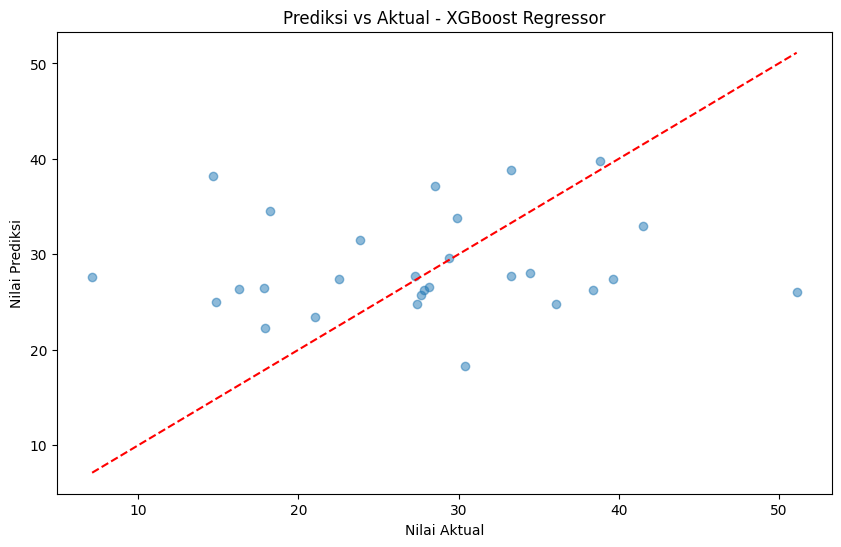

In [ ]:
# 2. XGBoost Regressor
xgb_model = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
xgb_results = evaluate_regression_model(xgb_model, X_train, X_test, y_train, y_test, "XGBoost Regressor")


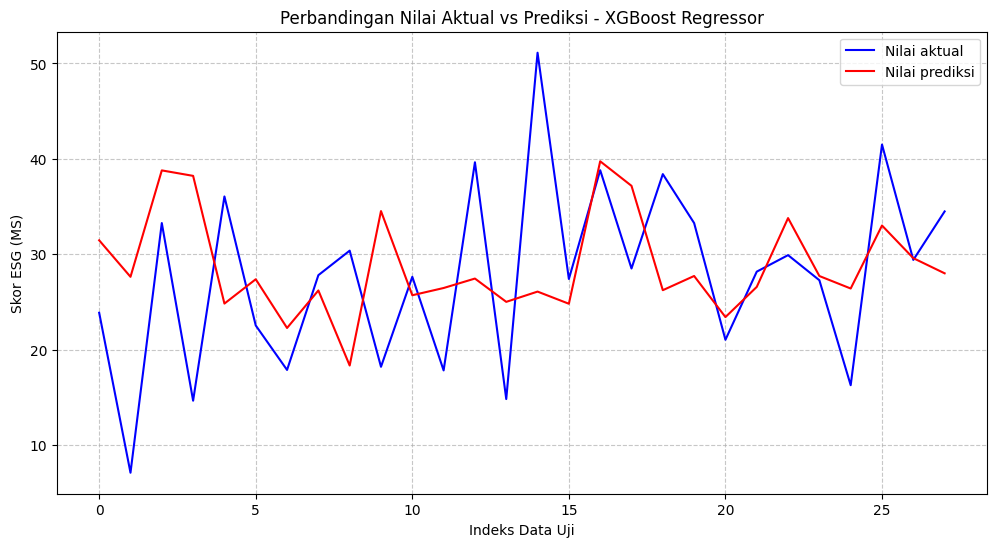

In [ ]:
# Plot perbandingan nilai aktual vs prediksi untuk Random Forest Regressor
y_pred_xgb = xgb_model.predict(X_test)
x_ax = range(len(y_test))
plt.figure(figsize=(12, 6))
plt.plot(x_ax, y_test, label="Nilai aktual", color="blue")
plt.plot(x_ax, y_pred_xgb, label="Nilai prediksi", color="red")
plt.title("Perbandingan Nilai Aktual vs Prediksi - XGBoost Regressor")
plt.xlabel("Indeks Data Uji")
plt.ylabel("Skor ESG (MS)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### ADAboost Regresi

Metrik Evaluasi rAdaBoost Regressor:
  - Mean Squared Error (MSE): 94.0051
  - Root Mean Squared Error (RMSE): 9.6956
  - R²: -0.0229
  - Mean Absolute Error (MAE): 7.7452
  - Median Absolute Error (MedAE): 5.7291


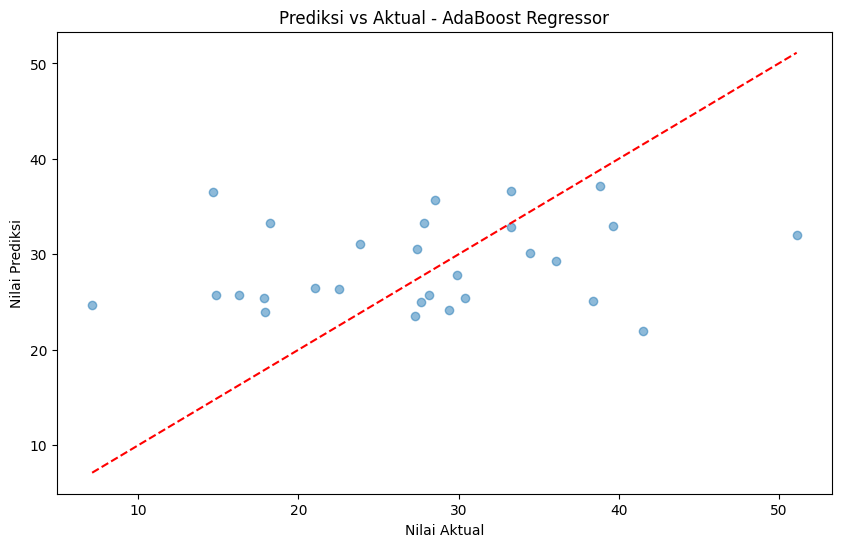

In [ ]:
# 3. AdaBoost Regressor
ada_model = AdaBoostRegressor(n_estimators=100, random_state=42)
ada_results = evaluate_regression_model(ada_model, X_train, X_test, y_train, y_test, "AdaBoost Regressor")


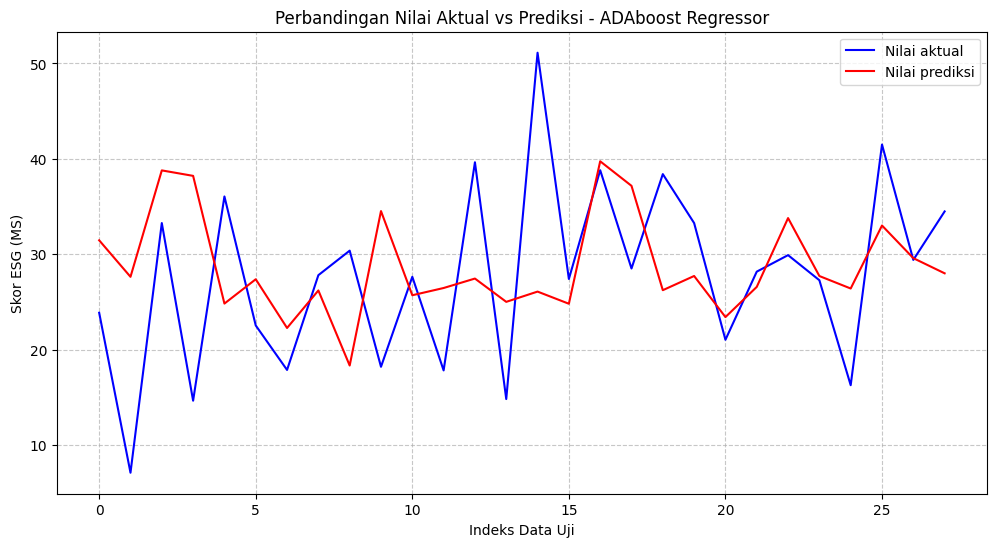

In [ ]:
# Plot perbandingan nilai aktual vs prediksi untuk Random Forest Regressor
y_pred_ada = ada_model.predict(X_test)
x_ax = range(len(y_test))
plt.figure(figsize=(12, 6))
plt.plot(x_ax, y_test, label="Nilai aktual", color="blue")
plt.plot(x_ax, y_pred_xgb, label="Nilai prediksi", color="red")
plt.title("Perbandingan Nilai Aktual vs Prediksi - ADAboost Regressor")
plt.xlabel("Indeks Data Uji")
plt.ylabel("Skor ESG (MS)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

##K-fold

In [ ]:
def evaluate_model_with_kfold(X, y, model, model_name, n_splits=10):
    # Inisialisasi K-Fold
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

    # List untuk menyimpan hasil metrik per fold
    mse_scores = []
    rmse_scores = []
    r2_scores = []

    # List untuk menampung aktual dan prediksi (visualisasi)
    all_y_test = []
    all_y_pred = []

    # Iterasi melalui setiap fold
    fold = 1
    for train_index, test_index in kf.split(X):
        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]

        # Training model
        model.fit(X_train, y_train)

        # Prediksi
        y_pred = model.predict(X_test)

        # Simpan untuk visualisasi nanti
        all_y_test.extend(y_test)
        all_y_pred.extend(y_pred)

        # Hitung metrik
        mse = mean_squared_error(y_test, y_pred)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_test, y_pred)

        # Simpan metrik
        mse_scores.append(mse)
        rmse_scores.append(rmse)
        r2_scores.append(r2)

        print(f"Fold {fold} - MSE: {mse:.4f}, RMSE: {rmse:.4f}, R²: {r2:.4f}")
        fold += 1

    # Hitung rata-rata metrik
    avg_mse = np.mean(mse_scores)
    avg_rmse = np.mean(rmse_scores)
    avg_r2 = np.mean(r2_scores)

    print(f"\n{model_name} - Hasil K-Fold Cross Validation ({n_splits} folds):")
    print(f"  - Rata-rata MSE: {avg_mse:.4f}")
    print(f"  - Rata-rata RMSE: {avg_rmse:.4f}")
    print(f"  - Rata-rata R²: {avg_r2:.4f}")

In [ ]:
n_splits = 10  # Jumlah lipatan pada Kfold

### Random forest Regresor

In [ ]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_results = evaluate_model_with_kfold(X, y, rf_model, "Random Forest Regressor", n_splits)

Fold 1 - MSE: 162.4130, RMSE: 12.7441, R²: -0.8314
Fold 2 - MSE: 67.0314, RMSE: 8.1873, R²: -0.0227
Fold 3 - MSE: 61.0741, RMSE: 7.8150, R²: 0.2598
Fold 4 - MSE: 55.0032, RMSE: 7.4164, R²: -0.0986
Fold 5 - MSE: 37.6050, RMSE: 6.1323, R²: -0.0893
Fold 6 - MSE: 134.5673, RMSE: 11.6003, R²: -0.8310
Fold 7 - MSE: 152.5442, RMSE: 12.3509, R²: -0.5775
Fold 8 - MSE: 162.2051, RMSE: 12.7360, R²: -0.4137
Fold 9 - MSE: 94.5135, RMSE: 9.7218, R²: -0.0288
Fold 10 - MSE: 53.9215, RMSE: 7.3431, R²: 0.4163

Random Forest Regressor - Hasil K-Fold Cross Validation (10 folds):
  - Rata-rata MSE: 98.0878
  - Rata-rata RMSE: 9.6047
  - Rata-rata R²: -0.2217


### XGBoost Regresi

In [ ]:
xgb_model = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
xgb_results = evaluate_model_with_kfold(X, y, xgb_model, "XGBoost Regressor", n_splits)

Fold 1 - MSE: 167.4652, RMSE: 12.9408, R²: -0.8884
Fold 2 - MSE: 88.1026, RMSE: 9.3863, R²: -0.3441
Fold 3 - MSE: 48.9435, RMSE: 6.9960, R²: 0.4069
Fold 4 - MSE: 84.6547, RMSE: 9.2008, R²: -0.6908
Fold 5 - MSE: 62.2059, RMSE: 7.8871, R²: -0.8019
Fold 6 - MSE: 184.9753, RMSE: 13.6006, R²: -1.5169
Fold 7 - MSE: 201.5187, RMSE: 14.1957, R²: -1.0840
Fold 8 - MSE: 149.7059, RMSE: 12.2354, R²: -0.3048
Fold 9 - MSE: 114.6772, RMSE: 10.7087, R²: -0.2483
Fold 10 - MSE: 75.6772, RMSE: 8.6993, R²: 0.1808

XGBoost Regressor - Hasil K-Fold Cross Validation (10 folds):
  - Rata-rata MSE: 117.7926
  - Rata-rata RMSE: 10.5851
  - Rata-rata R²: -0.5292


### ADAboost Regresi

In [ ]:
ada_model = AdaBoostRegressor(n_estimators=100, random_state=42)
ada_results = evaluate_model_with_kfold(X, y, ada_model, "AdaBoost Regressor", n_splits)

Fold 1 - MSE: 149.1684, RMSE: 12.2135, R²: -0.6821
Fold 2 - MSE: 72.4823, RMSE: 8.5137, R²: -0.1058
Fold 3 - MSE: 75.6191, RMSE: 8.6959, R²: 0.0836
Fold 4 - MSE: 74.1110, RMSE: 8.6088, R²: -0.4802
Fold 5 - MSE: 64.1589, RMSE: 8.0099, R²: -0.8585
Fold 6 - MSE: 149.3551, RMSE: 12.2211, R²: -1.0322
Fold 7 - MSE: 162.9701, RMSE: 12.7660, R²: -0.6854
Fold 8 - MSE: 174.3392, RMSE: 13.2038, R²: -0.5195
Fold 9 - MSE: 83.0686, RMSE: 9.1142, R²: 0.0957
Fold 10 - MSE: 59.7646, RMSE: 7.7308, R²: 0.3530

AdaBoost Regressor - Hasil K-Fold Cross Validation (10 folds):
  - Rata-rata MSE: 106.5037
  - Rata-rata RMSE: 10.1078
  - Rata-rata R²: -0.3831


# Data1: Target ESG LSEG

In [ ]:
# Membaca file CSV ke dalam DataFrame
df = pd.read_csv('data1_lseg_preprocessing.csv')
print("Jumlah Data:", df.shape)
df.head()

Jumlah Data: (531, 7)


,Pendapatan (Rp),Laba Bersih (Rp),Total Aset (Rp),Utang (Rp),Rasio Profitabilitas (Rp),Skor Sentimen Analisis (X),Skor ESG (LSEG)
0,6.250335e+12,2.516361e+12,4.560035e+13,1.527454e+13,0.4026,0.076,49.64
1,1.556600e+13,6.749000e+12,1.293120e+14,9.040100e+13,0.4336,0.011,58.70
2,9.241000e+12,-2.400000e+11,4.289100e+13,4.520000e+12,-0.0150,-0.010,88.93
3,1.153914e+13,2.259457e+12,6.682765e+13,2.562606e+13,0.1686,0.091,52.25
4,6.513200e+12,1.558700e+11,1.105251e+13,2.569930e+12,0.0239,0.116,53.61


## Pemodelan[Awal]

In [ ]:
# Persiapan data untuk pemodelan
# Definisikan X dan y
X = df.drop('Skor ESG (LSEG)', axis=1)
y = df['Skor ESG (LSEG)']

In [ ]:
# Fungsi untuk evaluasi model regresi
def evaluate_regression_model(model, X_train, X_test, y_train, y_test, model_name):
    # Latih model
    model.fit(X_train, y_train)

    # Prediksi
    y_pred = model.predict(X_test)

    # Evaluasi
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    medae = median_absolute_error(y_test, y_pred)

    print(f"Metrik Evaluasi r{model_name}:")
    print(f"  - Mean Squared Error (MSE): {mse:.4f}")
    print(f"  - Root Mean Squared Error (RMSE): {rmse:.4f}")
    print(f"  - R²: {r2:.4f}")
    print(f"  - Mean Absolute Error (MAE): {mae:.4f}")
    print(f"  - Median Absolute Error (MedAE): {medae:.4f}")

    # Visualisasi prediksi vs aktual
    plt.figure(figsize=(10, 6))
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], 'r--')
    plt.xlabel('Nilai Aktual')
    plt.ylabel('Nilai Prediksi')
    plt.title(f'Prediksi vs Aktual - {model_name}')
    plt.show()

    return model, mse, r2

##testsize 0.2

In [ ]:
# Bagi dataset menjadi set pelatihan dan pengujian
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# # Standarisasi fitur numerik (Normalisasi)
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)

Dataset berhasil disiapkan:
Jumlah fitur: 6
Jumlah sampel: 531
Fitur: Pendapatan (Rp), Laba Bersih (Rp), Total Aset (Rp), Utang (Rp), Rasio Profitabilitas (Rp), Skor Sentimen Analisis (X)

Jumlah data pelatihan: 424
Jumlah data pengujian: 107


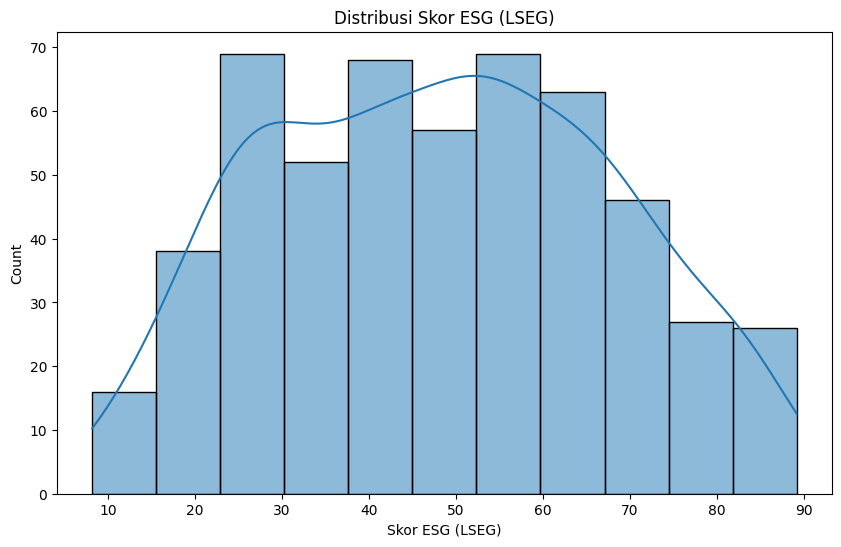

In [ ]:
print("Dataset berhasil disiapkan:")
print(f"Jumlah fitur: {X.shape[1]}")
print(f"Jumlah sampel: {X.shape[0]}")
print(f"Fitur: {', '.join(X.columns)}")
print(f"\nJumlah data pelatihan: {X_train.shape[0]}")
print(f"Jumlah data pengujian: {X_test.shape[0]}")

# Visualisasi distribusi target
plt.figure(figsize=(10, 6))
sns.histplot(y, kde=True)
plt.title('Distribusi Skor ESG (LSEG)')
plt.xlabel('Skor ESG (LSEG)')
plt.show()

### Random forest Regresor

Metrik Evaluasi rRandom Forest Regressor:
  - Mean Squared Error (MSE): 255.9364
  - Root Mean Squared Error (RMSE): 15.9980
  - R²: 0.3676
  - Mean Absolute Error (MAE): 12.0345
  - Median Absolute Error (MedAE): 9.0153


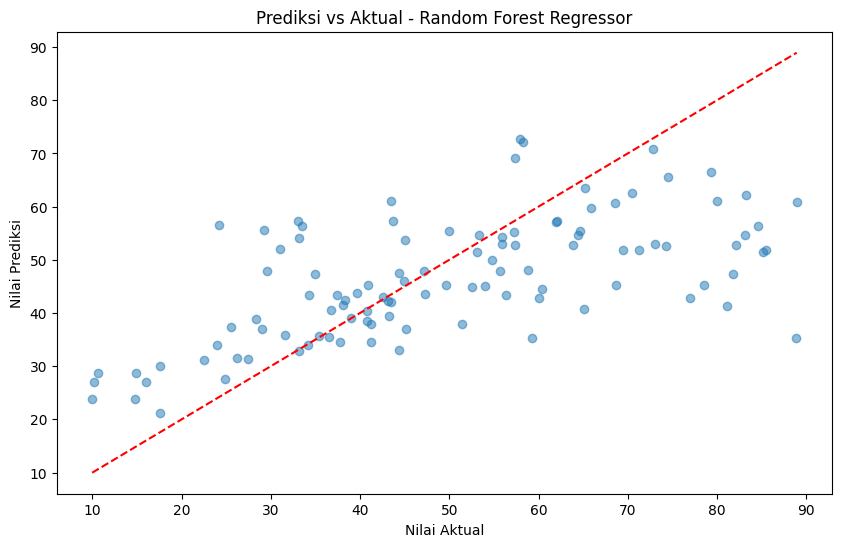

In [ ]:
# 1. Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_results = evaluate_regression_model(rf_model, X_train, X_test, y_train, y_test, "Random Forest Regressor")

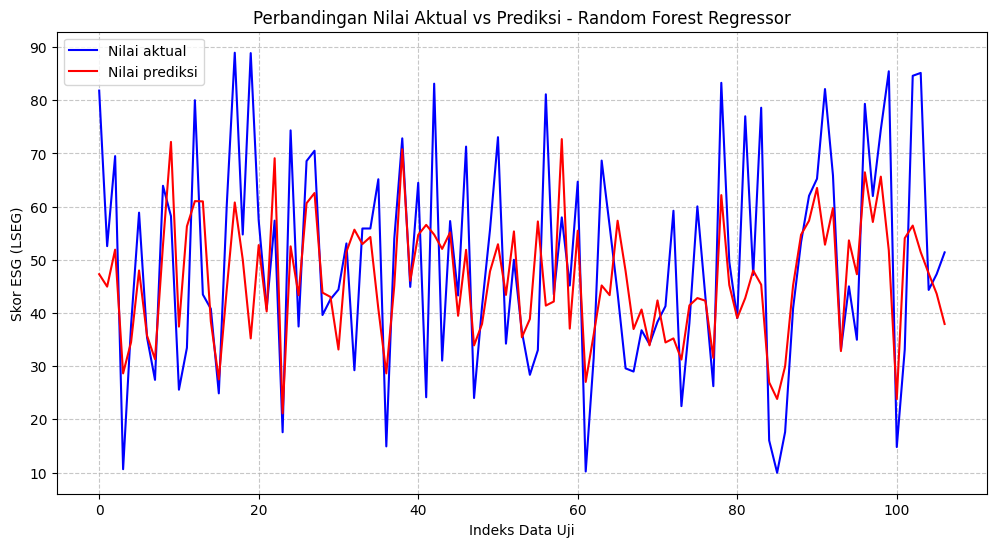

In [ ]:
# Plot perbandingan nilai aktual vs prediksi untuk Random Forest Regressor
y_pred_rf = rf_model.predict(X_test)
x_ax = range(len(y_test))
plt.figure(figsize=(12, 6))
plt.plot(x_ax, y_test, label="Nilai aktual", color="blue")
plt.plot(x_ax, y_pred_rf, label="Nilai prediksi", color="red")
plt.title("Perbandingan Nilai Aktual vs Prediksi - Random Forest Regressor")
plt.xlabel("Indeks Data Uji")
plt.ylabel("Skor ESG (LSEG)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### XGBoost Regresi

Metrik Evaluasi rXGBoost Regressor:
  - Mean Squared Error (MSE): 250.2678
  - Root Mean Squared Error (RMSE): 15.8199
  - R²: 0.3816
  - Mean Absolute Error (MAE): 11.9503
  - Median Absolute Error (MedAE): 7.9310


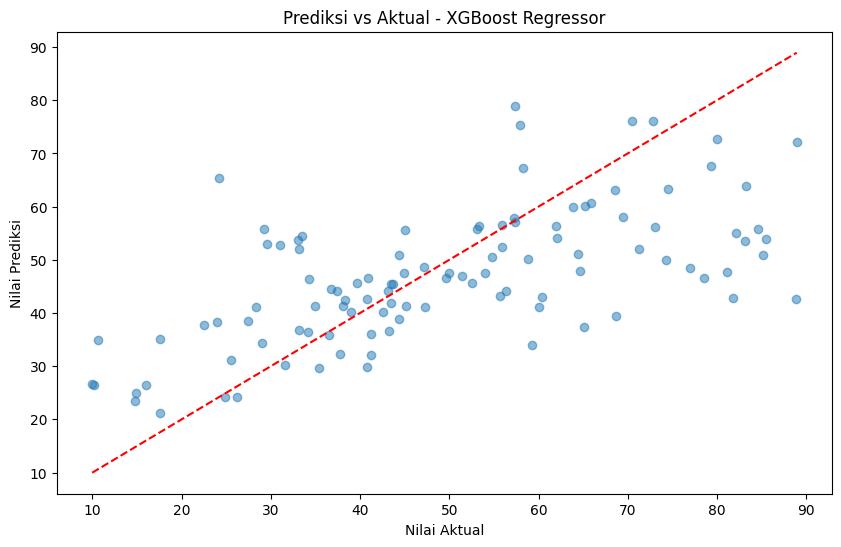

In [ ]:
# 2. XGBoost Regressor
xgb_model = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
xgb_results = evaluate_regression_model(xgb_model, X_train, X_test, y_train, y_test, "XGBoost Regressor")

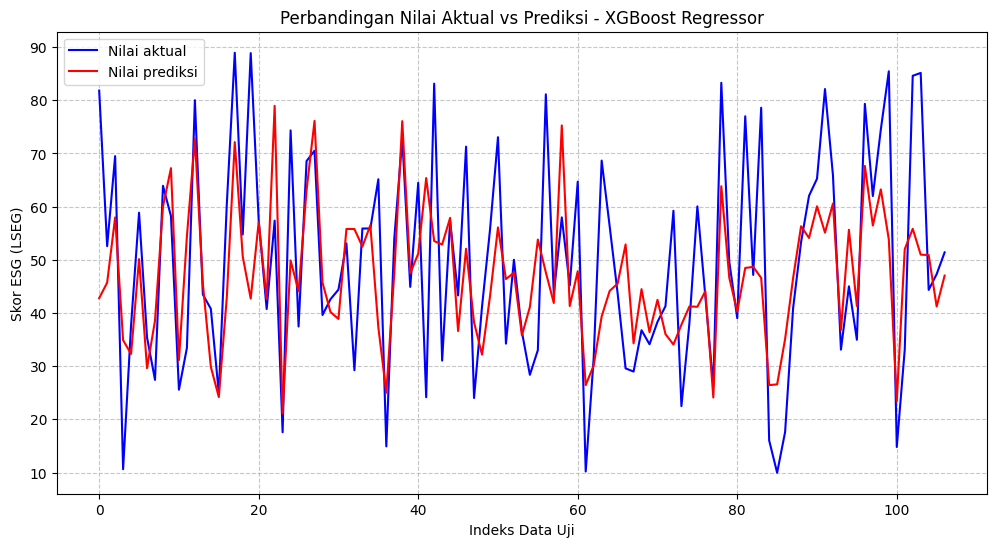

In [ ]:
# Plot perbandingan nilai aktual vs prediksi untuk Random Forest Regressor
y_pred_xgb = xgb_model.predict(X_test)
x_ax = range(len(y_test))
plt.figure(figsize=(12, 6))
plt.plot(x_ax, y_test, label="Nilai aktual", color="blue")
plt.plot(x_ax, y_pred_xgb, label="Nilai prediksi", color="red")
plt.title("Perbandingan Nilai Aktual vs Prediksi - XGBoost Regressor")
plt.xlabel("Indeks Data Uji")
plt.ylabel("Skor ESG (LSEG)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### ADAboost Regresi

Metrik Evaluasi rAdaBoost Regressor:
  - Mean Squared Error (MSE): 346.1057
  - Root Mean Squared Error (RMSE): 18.6039
  - R²: 0.1448
  - Mean Absolute Error (MAE): 14.7400
  - Median Absolute Error (MedAE): 12.3619


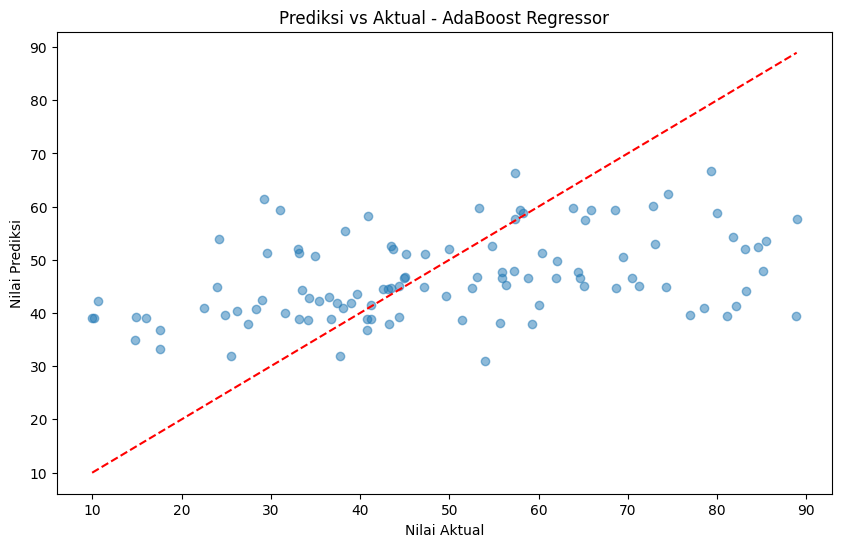

In [ ]:
# 3. AdaBoost Regressor
ada_model = AdaBoostRegressor(n_estimators=100, random_state=42)
ada_results = evaluate_regression_model(ada_model, X_train, X_test, y_train, y_test, "AdaBoost Regressor")

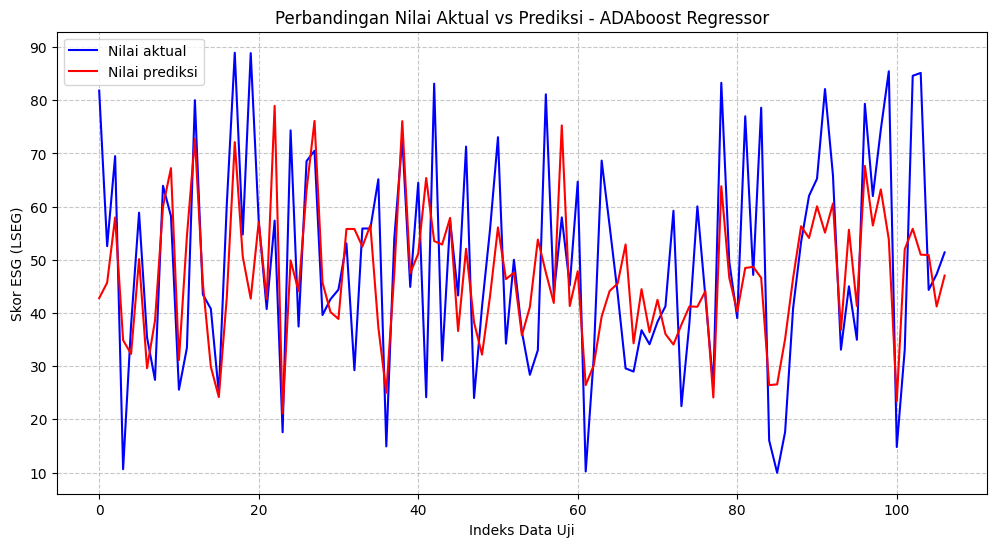

In [ ]:
# Plot perbandingan nilai aktual vs prediksi untuk Random Forest Regressor
y_pred_ada = ada_model.predict(X_test)
x_ax = range(len(y_test))
plt.figure(figsize=(12, 6))
plt.plot(x_ax, y_test, label="Nilai aktual", color="blue")
plt.plot(x_ax, y_pred_xgb, label="Nilai prediksi", color="red")
plt.title("Perbandingan Nilai Aktual vs Prediksi - ADAboost Regressor")
plt.xlabel("Indeks Data Uji")
plt.ylabel("Skor ESG (LSEG)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

##testsize 0.3

In [ ]:
# Bagi dataset menjadi set pelatihan dan pengujian
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [ ]:
# # Standarisasi fitur numerik (Normalisasi)
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)

Dataset berhasil disiapkan:
Jumlah fitur: 6
Jumlah sampel: 531
Fitur: Pendapatan (Rp), Laba Bersih (Rp), Total Aset (Rp), Utang (Rp), Rasio Profitabilitas (Rp), Skor Sentimen Analisis (X)

Jumlah data pelatihan: 371
Jumlah data pengujian: 160


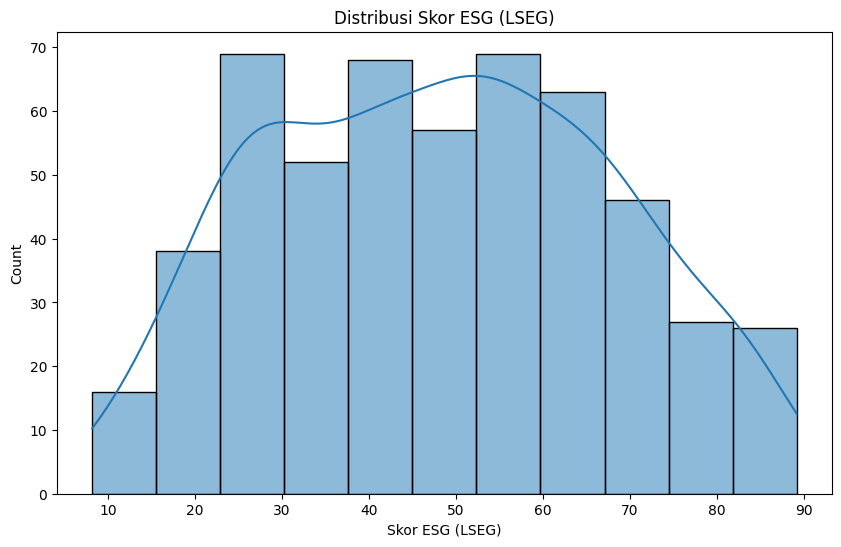

In [ ]:
print("Dataset berhasil disiapkan:")
print(f"Jumlah fitur: {X.shape[1]}")
print(f"Jumlah sampel: {X.shape[0]}")
print(f"Fitur: {', '.join(X.columns)}")
print(f"\nJumlah data pelatihan: {X_train.shape[0]}")
print(f"Jumlah data pengujian: {X_test.shape[0]}")

# Visualisasi distribusi target
plt.figure(figsize=(10, 6))
sns.histplot(y, kde=True)
plt.title('Distribusi Skor ESG (LSEG)')
plt.xlabel('Skor ESG (LSEG)')
plt.show()

### Random forest Regresor

Metrik Evaluasi rRandom Forest Regressor:
  - Mean Squared Error (MSE): 226.3315
  - Root Mean Squared Error (RMSE): 15.0443
  - R²: 0.4030
  - Mean Absolute Error (MAE): 11.3913
  - Median Absolute Error (MedAE): 9.2199


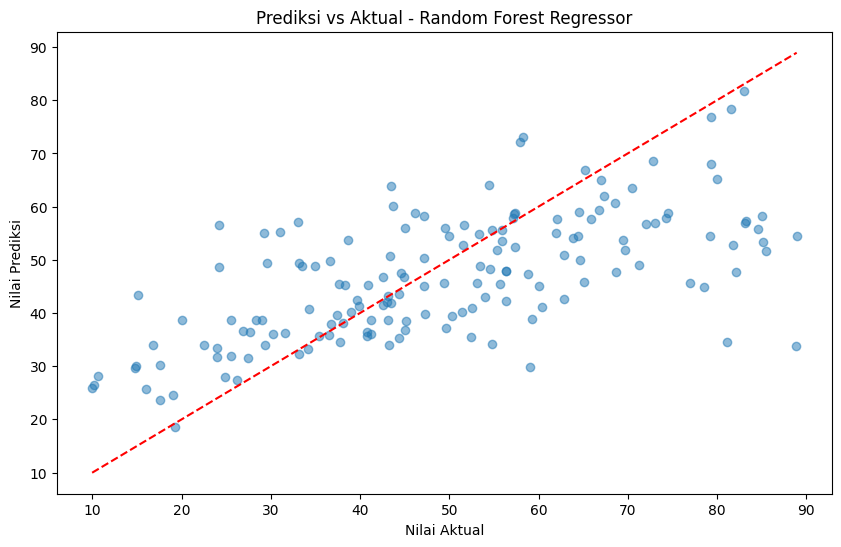

In [ ]:
# 1. Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_results = evaluate_regression_model(rf_model, X_train, X_test, y_train, y_test, "Random Forest Regressor")


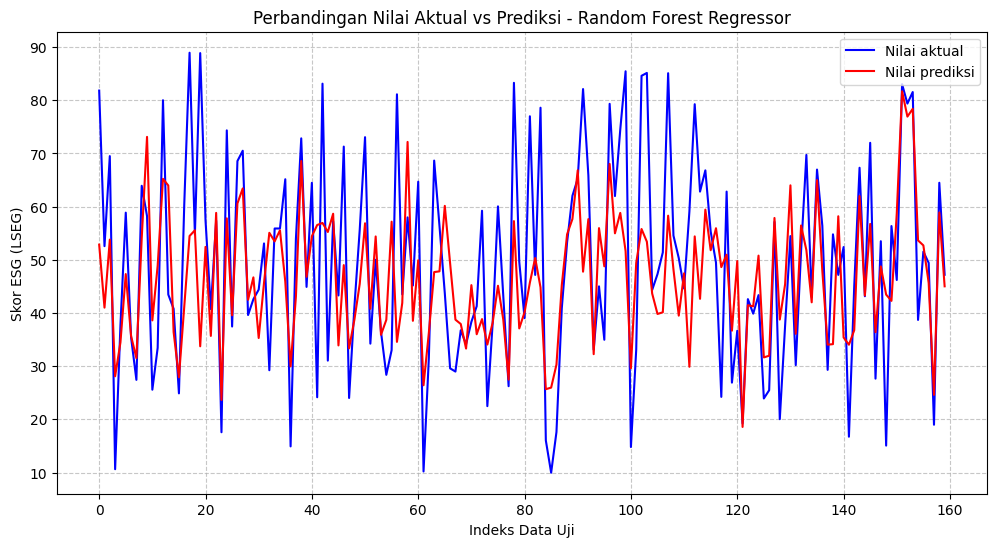

In [ ]:
# Plot perbandingan nilai aktual vs prediksi untuk Random Forest Regressor
y_pred_rf = rf_model.predict(X_test)
x_ax = range(len(y_test))
plt.figure(figsize=(12, 6))
plt.plot(x_ax, y_test, label="Nilai aktual", color="blue")
plt.plot(x_ax, y_pred_rf, label="Nilai prediksi", color="red")
plt.title("Perbandingan Nilai Aktual vs Prediksi - Random Forest Regressor")
plt.xlabel("Indeks Data Uji")
plt.ylabel("Skor ESG (LSEG)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### XGBoost Regresi

Metrik Evaluasi rXGBoost Regressor:
  - Mean Squared Error (MSE): 212.0681
  - Root Mean Squared Error (RMSE): 14.5626
  - R²: 0.4407
  - Mean Absolute Error (MAE): 10.9219
  - Median Absolute Error (MedAE): 7.8451


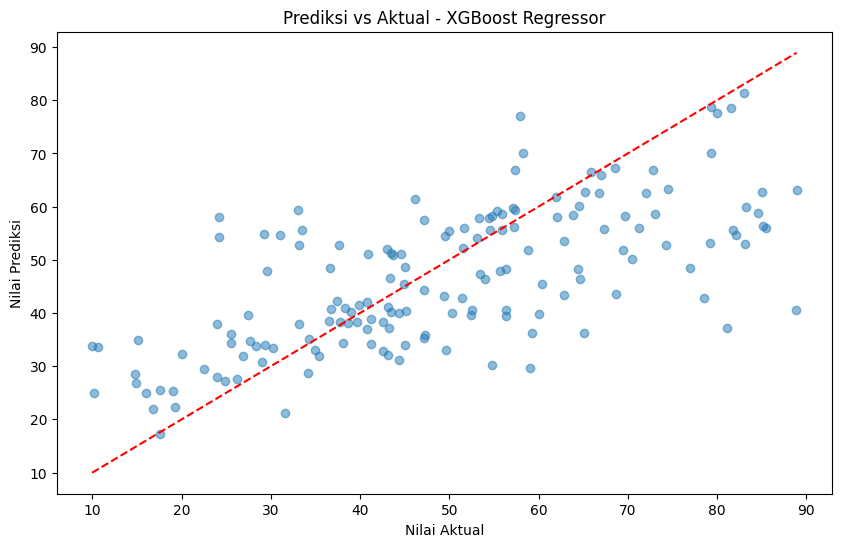

In [ ]:
# 2. XGBoost Regressor
xgb_model = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
xgb_results = evaluate_regression_model(xgb_model, X_train, X_test, y_train, y_test, "XGBoost Regressor")


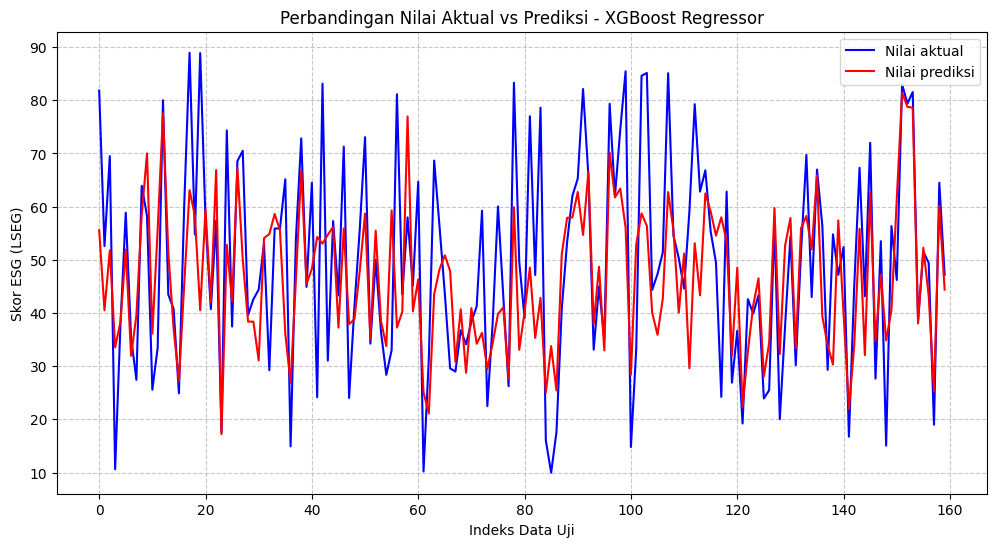

In [ ]:
# Plot perbandingan nilai aktual vs prediksi untuk Random Forest Regressor
y_pred_xgb = xgb_model.predict(X_test)
x_ax = range(len(y_test))
plt.figure(figsize=(12, 6))
plt.plot(x_ax, y_test, label="Nilai aktual", color="blue")
plt.plot(x_ax, y_pred_xgb, label="Nilai prediksi", color="red")
plt.title("Perbandingan Nilai Aktual vs Prediksi - XGBoost Regressor")
plt.xlabel("Indeks Data Uji")
plt.ylabel("Skor ESG (LSEG)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### ADAboost Regresi

Metrik Evaluasi rAdaBoost Regressor:
  - Mean Squared Error (MSE): 286.7448
  - Root Mean Squared Error (RMSE): 16.9335
  - R²: 0.2437
  - Mean Absolute Error (MAE): 13.3115
  - Median Absolute Error (MedAE): 11.0841


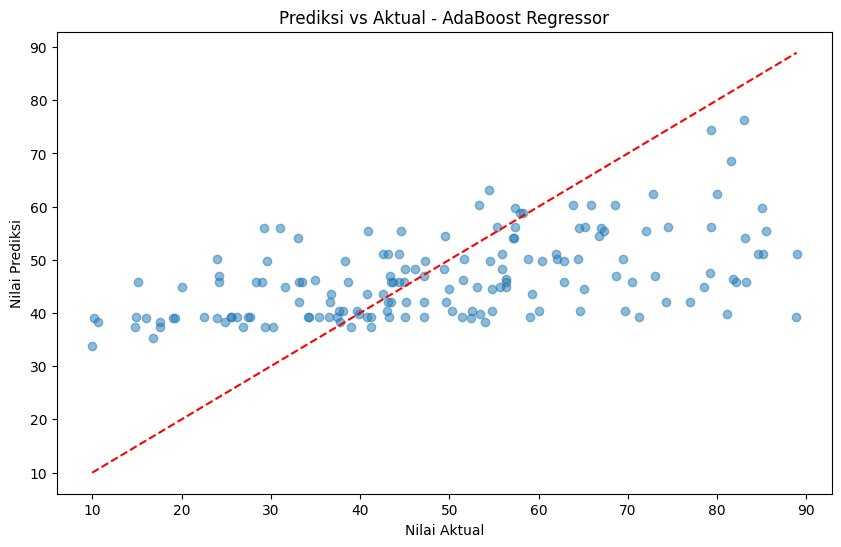

In [ ]:
# 3. AdaBoost Regressor
ada_model = AdaBoostRegressor(n_estimators=100, random_state=42)
ada_results = evaluate_regression_model(ada_model, X_train, X_test, y_train, y_test, "AdaBoost Regressor")


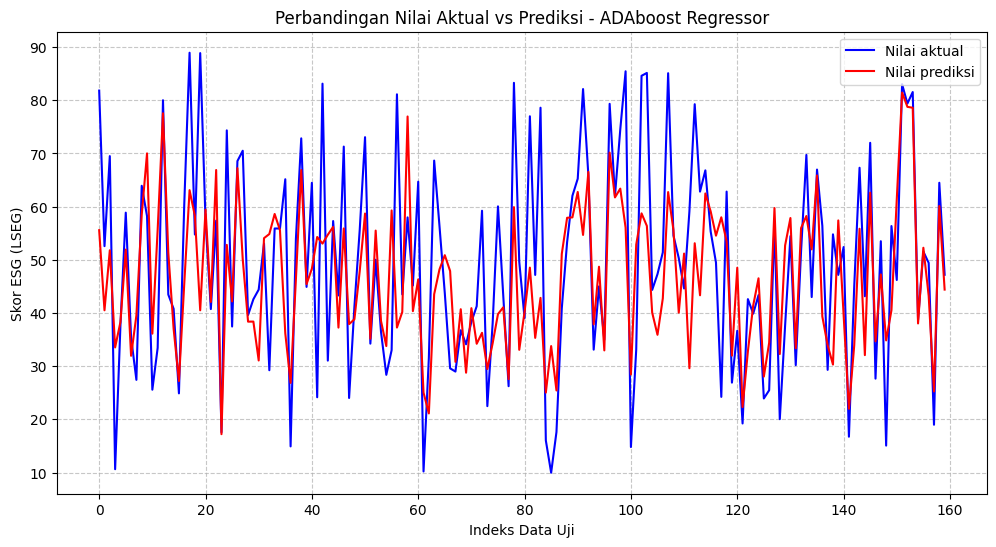

In [ ]:
# Plot perbandingan nilai aktual vs prediksi untuk Random Forest Regressor
y_pred_ada = ada_model.predict(X_test)
x_ax = range(len(y_test))
plt.figure(figsize=(12, 6))
plt.plot(x_ax, y_test, label="Nilai aktual", color="blue")
plt.plot(x_ax, y_pred_xgb, label="Nilai prediksi", color="red")
plt.title("Perbandingan Nilai Aktual vs Prediksi - ADAboost Regressor")
plt.xlabel("Indeks Data Uji")
plt.ylabel("Skor ESG (LSEG)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

##testsize 0.4

In [ ]:
# Bagi dataset menjadi set pelatihan dan pengujian
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

In [ ]:
# # Standarisasi fitur numerik (Normalisasi)
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)

Dataset berhasil disiapkan:
Jumlah fitur: 6
Jumlah sampel: 531
Fitur: Pendapatan (Rp), Laba Bersih (Rp), Total Aset (Rp), Utang (Rp), Rasio Profitabilitas (Rp), Skor Sentimen Analisis (X)

Jumlah data pelatihan: 318
Jumlah data pengujian: 213


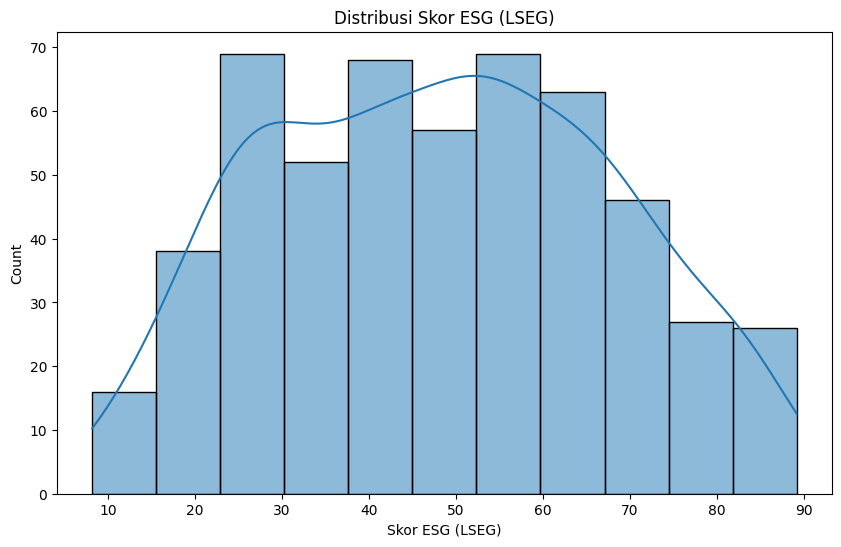

In [ ]:
print("Dataset berhasil disiapkan:")
print(f"Jumlah fitur: {X.shape[1]}")
print(f"Jumlah sampel: {X.shape[0]}")
print(f"Fitur: {', '.join(X.columns)}")
print(f"\nJumlah data pelatihan: {X_train.shape[0]}")
print(f"Jumlah data pengujian: {X_test.shape[0]}")

# Visualisasi distribusi target
plt.figure(figsize=(10, 6))
sns.histplot(y, kde=True)
plt.title('Distribusi Skor ESG (LSEG)')
plt.xlabel('Skor ESG (LSEG)')
plt.show()

### Random forest Regresor

Metrik Evaluasi rRandom Forest Regressor:
  - Mean Squared Error (MSE): 243.6510
  - Root Mean Squared Error (RMSE): 15.6093
  - R²: 0.3642
  - Mean Absolute Error (MAE): 11.9824
  - Median Absolute Error (MedAE): 8.5293


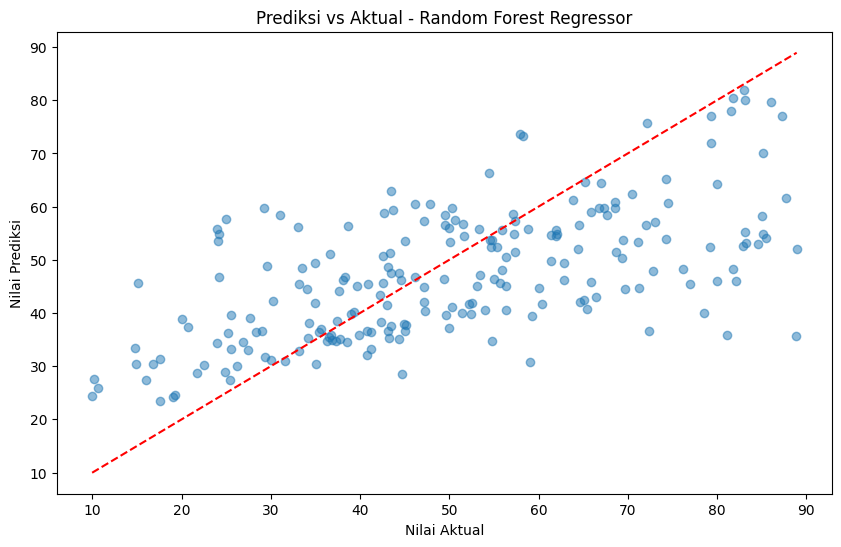

In [ ]:
# 1. Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_results = evaluate_regression_model(rf_model, X_train, X_test, y_train, y_test, "Random Forest Regressor")


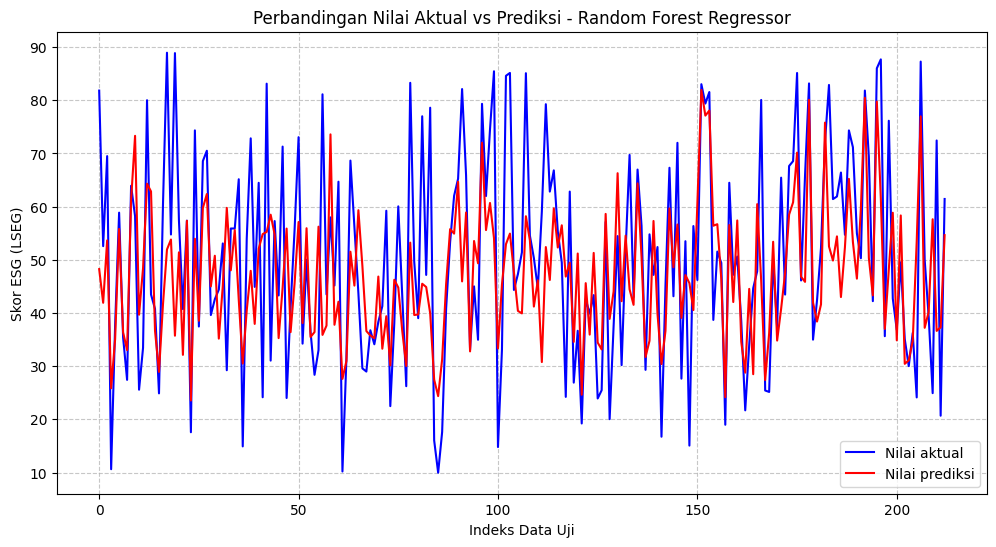

In [ ]:
# Plot perbandingan nilai aktual vs prediksi untuk Random Forest Regressor
y_pred_rf = rf_model.predict(X_test)
x_ax = range(len(y_test))
plt.figure(figsize=(12, 6))
plt.plot(x_ax, y_test, label="Nilai aktual", color="blue")
plt.plot(x_ax, y_pred_rf, label="Nilai prediksi", color="red")
plt.title("Perbandingan Nilai Aktual vs Prediksi - Random Forest Regressor")
plt.xlabel("Indeks Data Uji")
plt.ylabel("Skor ESG (LSEG)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### XGBoost Regresi

Metrik Evaluasi rXGBoost Regressor:
  - Mean Squared Error (MSE): 242.4465
  - Root Mean Squared Error (RMSE): 15.5707
  - R²: 0.3673
  - Mean Absolute Error (MAE): 11.7509
  - Median Absolute Error (MedAE): 8.6528


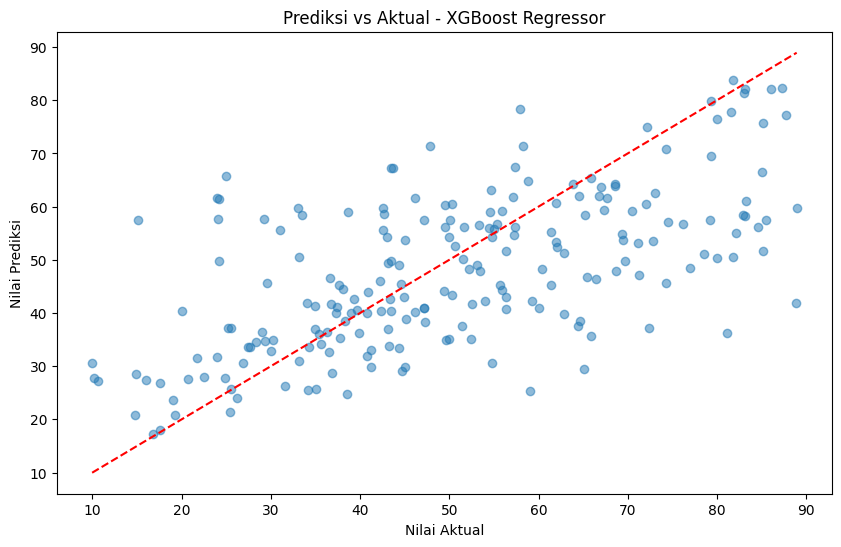

In [ ]:
# 2. XGBoost Regressor
xgb_model = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
xgb_results = evaluate_regression_model(xgb_model, X_train, X_test, y_train, y_test, "XGBoost Regressor")


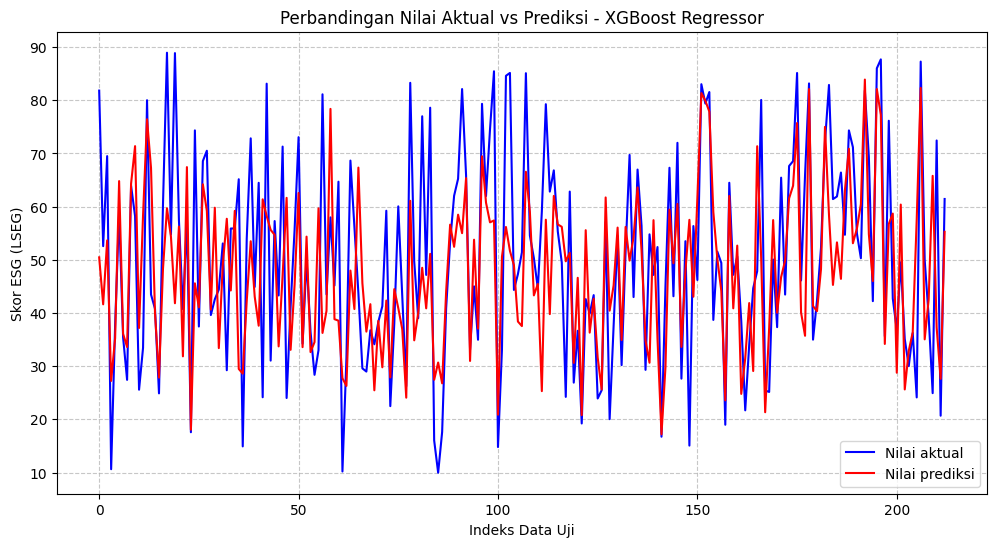

In [ ]:
# Plot perbandingan nilai aktual vs prediksi untuk Random Forest Regressor
y_pred_xgb = xgb_model.predict(X_test)
x_ax = range(len(y_test))
plt.figure(figsize=(12, 6))
plt.plot(x_ax, y_test, label="Nilai aktual", color="blue")
plt.plot(x_ax, y_pred_xgb, label="Nilai prediksi", color="red")
plt.title("Perbandingan Nilai Aktual vs Prediksi - XGBoost Regressor")
plt.xlabel("Indeks Data Uji")
plt.ylabel("Skor ESG (LSEG)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### ADAboost Regresi

Metrik Evaluasi rAdaBoost Regressor:
  - Mean Squared Error (MSE): 302.5123
  - Root Mean Squared Error (RMSE): 17.3929
  - R²: 0.2106
  - Mean Absolute Error (MAE): 13.9514
  - Median Absolute Error (MedAE): 11.7560


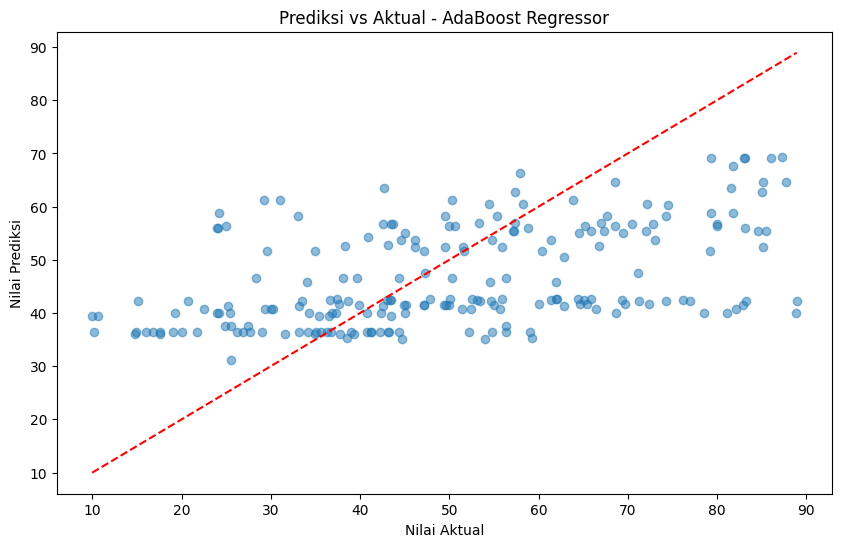

In [ ]:
# 3. AdaBoost Regressor
ada_model = AdaBoostRegressor(n_estimators=100, random_state=42)
ada_results = evaluate_regression_model(ada_model, X_train, X_test, y_train, y_test, "AdaBoost Regressor")


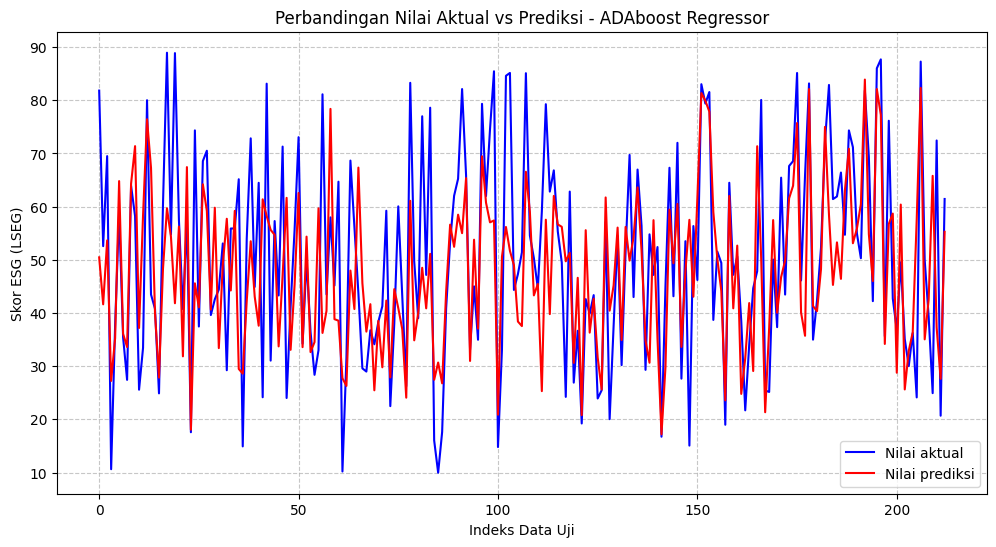

In [ ]:
# Plot perbandingan nilai aktual vs prediksi untuk Random Forest Regressor
y_pred_ada = ada_model.predict(X_test)
x_ax = range(len(y_test))
plt.figure(figsize=(12, 6))
plt.plot(x_ax, y_test, label="Nilai aktual", color="blue")
plt.plot(x_ax, y_pred_xgb, label="Nilai prediksi", color="red")
plt.title("Perbandingan Nilai Aktual vs Prediksi - ADAboost Regressor")
plt.xlabel("Indeks Data Uji")
plt.ylabel("Skor ESG (LSEG)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

##K-fold

In [ ]:
def evaluate_model_with_kfold(X, y, model, model_name, n_splits=10):
    # Inisialisasi K-Fold
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

    # List untuk menyimpan hasil metrik per fold
    mse_scores = []
    rmse_scores = []
    r2_scores = []

    # List untuk menampung aktual dan prediksi (visualisasi)
    all_y_test = []
    all_y_pred = []

    # Iterasi melalui setiap fold
    fold = 1
    for train_index, test_index in kf.split(X):
        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]

        # Training model
        model.fit(X_train, y_train)

        # Prediksi
        y_pred = model.predict(X_test)

        # Simpan untuk visualisasi nanti
        all_y_test.extend(y_test)
        all_y_pred.extend(y_pred)

        # Hitung metrik
        mse = mean_squared_error(y_test, y_pred)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_test, y_pred)

        # Simpan metrik
        mse_scores.append(mse)
        rmse_scores.append(rmse)
        r2_scores.append(r2)

        print(f"Fold {fold} - MSE: {mse:.4f}, RMSE: {rmse:.4f}, R²: {r2:.4f}")
        fold += 1

    # Hitung rata-rata metrik
    avg_mse = np.mean(mse_scores)
    avg_rmse = np.mean(rmse_scores)
    avg_r2 = np.mean(r2_scores)

    print(f"\n{model_name} - Hasil K-Fold Cross Validation ({n_splits} folds):")
    print(f"  - Rata-rata MSE: {avg_mse:.4f}")
    print(f"  - Rata-rata RMSE: {avg_rmse:.4f}")
    print(f"  - Rata-rata R²: {avg_r2:.4f}")

In [ ]:
# Definisikan X dan y
n_splits = 10  # Jumlah lipatan pada Kfold

### Random forest Regresor

In [ ]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_results = evaluate_model_with_kfold(X, y, rf_model, "Random Forest Regressor", n_splits)

Fold 1 - MSE: 213.0783, RMSE: 14.5972, R²: 0.4235
Fold 2 - MSE: 244.1851, RMSE: 15.6264, R²: 0.4439
Fold 3 - MSE: 151.4950, RMSE: 12.3083, R²: 0.5366
Fold 4 - MSE: 131.9092, RMSE: 11.4852, R²: 0.6533
Fold 5 - MSE: 212.5330, RMSE: 14.5785, R²: 0.3268
Fold 6 - MSE: 163.7327, RMSE: 12.7958, R²: 0.5455
Fold 7 - MSE: 184.2876, RMSE: 13.5753, R²: 0.5643
Fold 8 - MSE: 167.8653, RMSE: 12.9563, R²: 0.4857
Fold 9 - MSE: 152.4925, RMSE: 12.3488, R²: 0.6039
Fold 10 - MSE: 166.3010, RMSE: 12.8958, R²: 0.5994

Random Forest Regressor - Hasil K-Fold Cross Validation (10 folds):
  - Rata-rata MSE: 178.7880
  - Rata-rata RMSE: 13.3168
  - Rata-rata R²: 0.5183


### XGBoost Regresi

In [ ]:
xgb_model = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
xgb_results = evaluate_model_with_kfold(X, y, xgb_model, "XGBoost Regressor", n_splits)

Fold 1 - MSE: 204.2194, RMSE: 14.2905, R²: 0.4475
Fold 2 - MSE: 219.2574, RMSE: 14.8073, R²: 0.5007
Fold 3 - MSE: 152.9935, RMSE: 12.3691, R²: 0.5320
Fold 4 - MSE: 118.1479, RMSE: 10.8696, R²: 0.6895
Fold 5 - MSE: 195.4475, RMSE: 13.9803, R²: 0.3809
Fold 6 - MSE: 177.3216, RMSE: 13.3162, R²: 0.5077
Fold 7 - MSE: 183.7460, RMSE: 13.5553, R²: 0.5656
Fold 8 - MSE: 159.3129, RMSE: 12.6219, R²: 0.5119
Fold 9 - MSE: 161.3280, RMSE: 12.7015, R²: 0.5810
Fold 10 - MSE: 163.8102, RMSE: 12.7988, R²: 0.6054

XGBoost Regressor - Hasil K-Fold Cross Validation (10 folds):
  - Rata-rata MSE: 173.5584
  - Rata-rata RMSE: 13.1311
  - Rata-rata R²: 0.5322


### ADAboost Regresi

In [ ]:
ada_model = AdaBoostRegressor(n_estimators=100, random_state=42)
ada_results = evaluate_model_with_kfold(X, y, ada_model, "AdaBoost Regressor", n_splits)

Fold 1 - MSE: 297.6128, RMSE: 17.2515, R²: 0.1948
Fold 2 - MSE: 370.5907, RMSE: 19.2507, R²: 0.1560
Fold 3 - MSE: 181.9459, RMSE: 13.4887, R²: 0.4435
Fold 4 - MSE: 251.8446, RMSE: 15.8696, R²: 0.3380
Fold 5 - MSE: 301.3989, RMSE: 17.3608, R²: 0.0453
Fold 6 - MSE: 237.9569, RMSE: 15.4259, R²: 0.3394
Fold 7 - MSE: 276.3534, RMSE: 16.6239, R²: 0.3467
Fold 8 - MSE: 243.9108, RMSE: 15.6176, R²: 0.2527
Fold 9 - MSE: 216.6623, RMSE: 14.7195, R²: 0.4372
Fold 10 - MSE: 258.1065, RMSE: 16.0657, R²: 0.3783

AdaBoost Regressor - Hasil K-Fold Cross Validation (10 folds):
  - Rata-rata MSE: 263.6383
  - Rata-rata RMSE: 16.1674
  - Rata-rata R²: 0.2932




---


# **Skenario 2:** Independen Atribut Numerik + Target Kategorikal

# Data2: Target ESG LSEG [2 Kelas]

In [ ]:
# Membaca file CSV ke dalam DataFrame
df = pd.read_csv('data2_lseg_2kelas_preprocessing.csv')
print("Jumlah Data:", df.shape)
df.head()

Jumlah Data: (444, 7)


,Pendapatan (Rp),Laba Bersih (Rp),Total Aset (Rp),Utang (Rp),Rasio Profitabilitas (Rp),Skor Sentimen Analisis (X),Skor ESG (LSEG)
0,6.250335e+12,2.516361e+12,4.560035e+13,1.527454e+13,0.4026,0.076,0
1,1.556600e+13,6.749000e+12,1.293120e+14,9.040100e+13,0.4336,0.011,1
2,9.241000e+12,-2.400000e+11,4.289100e+13,4.520000e+12,-0.0150,-0.010,1
3,1.153914e+13,2.259457e+12,6.682765e+13,2.562606e+13,0.1686,0.091,1
4,6.513200e+12,1.558700e+11,1.105251e+13,2.569930e+12,0.0239,0.116,1


## **4. Pemodelan [Awal]**

In [ ]:
# Definisikan X dan y
X = df.drop('Skor ESG (LSEG)', axis=1)
y = df['Skor ESG (LSEG)']

# Label kelasnya
class_labels = ['Jelek', 'Bagus']

Jumlah total sampel awal: 444
Jumlah sampel awal: Counter({0: 247, 1: 197})


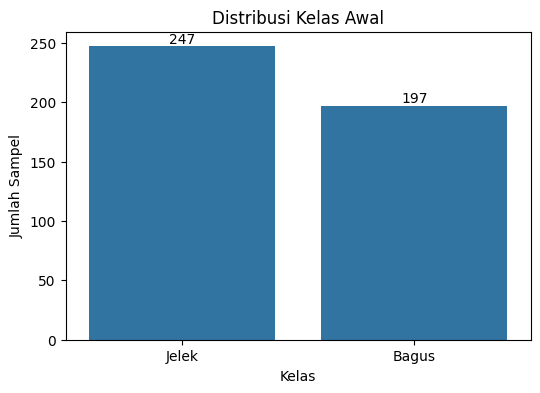

In [ ]:
# Menampilkan jumlah sampel awal
print("Jumlah total sampel awal:", len(y))
print("Jumlah sampel awal:", Counter(y))

# Membuat bar chart distribusi kelas awal
plt.figure(figsize=(6, 4))
sns.countplot(x=y)
plt.title('Distribusi Kelas Awal')
plt.xlabel('Kelas')
plt.xticks(range(len(class_labels)), class_labels)
plt.ylabel('Jumlah Sampel')

# Menambahkan label jumlah data di atas setiap bar
for p in plt.gca().patches:
    plt.gca().annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                       ha='center', va='center', fontsize=10, color='black', xytext=(0, 5),
                       textcoords='offset points')

plt.show()

In [ ]:
# # Melakukan SMOTE untuk mengatasi ketidakseimbangan kelas
# smote = SMOTE(random_state=42)
# X, y = smote.fit_resample(X, y)

# # Menampilkan jumlah sampel setelah SMOTE
# print("Jumlah total sampel setelah SMOTE:", len(y))
# print("Jumlah sampel setelah SMOTE:", Counter(y))

# # Membuat bar chart distribusi kelas setelah SMOTE
# plt.figure(figsize=(6, 4))
# sns.countplot(x=y)
# plt.title('Distribusi Kelas Setelah SMOTE')
# plt.xlabel('Kelas')
# plt.xticks(range(len(class_labels)), class_labels)
# plt.ylabel('Jumlah Sampel')

# # Menambahkan label jumlah data di atas setiap bar
# for p in plt.gca().patches:
#     plt.gca().annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
#                        ha='center', va='center', fontsize=10, color='black', xytext=(0, 5),
#                        textcoords='offset points')

# plt.show()

In [ ]:
# Fungsi untuk evaluasi model klasifikasi (target kategorikal)
def evaluate_classification_model(model, X_train, X_test, y_train, y_test, model_name, classes=class_labels):
    # Latih model
    model.fit(X_train, y_train)

    # Prediksi
    y_pred = model.predict(X_test)

    # Evaluasi
    acc = accuracy_score(y_test, y_pred)

    print(f"{model_name}:")
    print(f"  - Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred, target_names=class_labels))

    # Visualisasi Confusion Matrix
    plt.figure(figsize=(6, 4))
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_labels,
                yticklabels=class_labels
                )
    plt.xlabel('Prediksi')
    plt.ylabel('Aktual')
    plt.title(f'Confusion Matrix - {model_name}')
    plt.show()

    return model, acc

## 4.1. Test size 0.2

In [ ]:
# Bagi dataset menjadi set pelatihan dan pengujian
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Random forest Classifier

Random forest Classifier:
  - Accuracy: 0.7865
              precision    recall  f1-score   support

       Jelek       0.78      0.83      0.80        47
       Bagus       0.79      0.74      0.77        42

    accuracy                           0.79        89
   macro avg       0.79      0.78      0.78        89
weighted avg       0.79      0.79      0.79        89



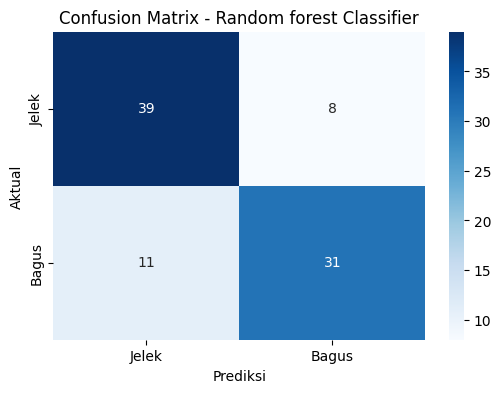

In [ ]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_result = evaluate_classification_model(rf_classifier, X_train, X_test, y_train, y_test, "Random forest Classifier")

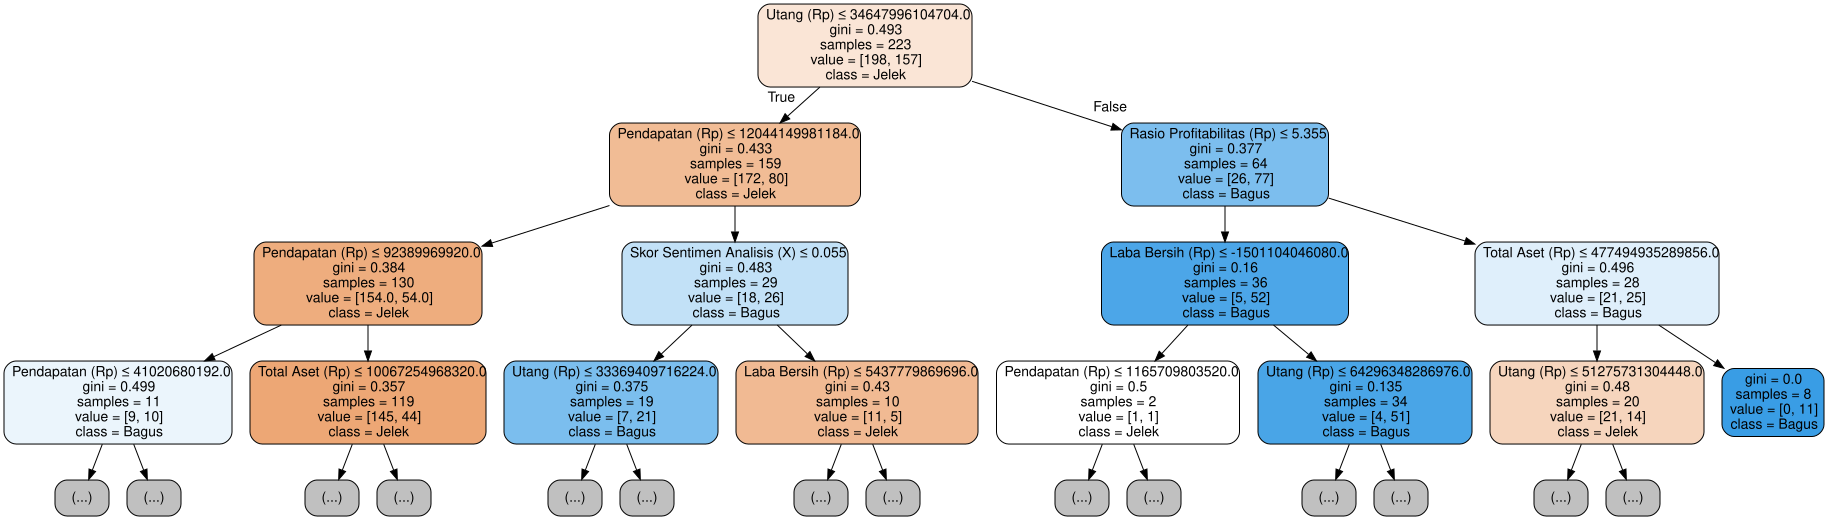

In [ ]:
# Pilih satu pohon dari Random Forest untuk ditampilkan
estimator = rf_classifier.estimators_[0]

# Export pohon ke format DOT
dot_data = export_graphviz(estimator, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat grafik dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan grafik
graph

### Decison Tree

Decision Tree:
  - Accuracy: 0.7191
              precision    recall  f1-score   support

       Jelek       0.76      0.68      0.72        47
       Bagus       0.68      0.76      0.72        42

    accuracy                           0.72        89
   macro avg       0.72      0.72      0.72        89
weighted avg       0.72      0.72      0.72        89



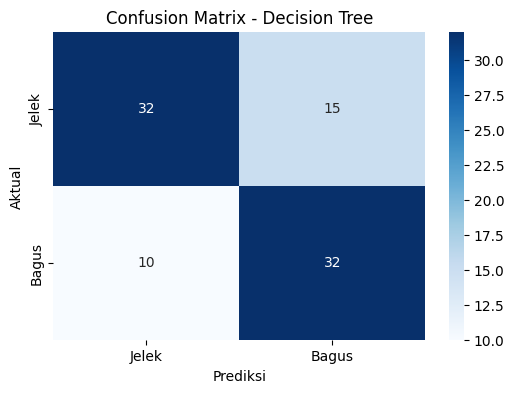

In [ ]:
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_result = evaluate_classification_model(dt_classifier, X_train, X_test, y_train, y_test, "Decision Tree")

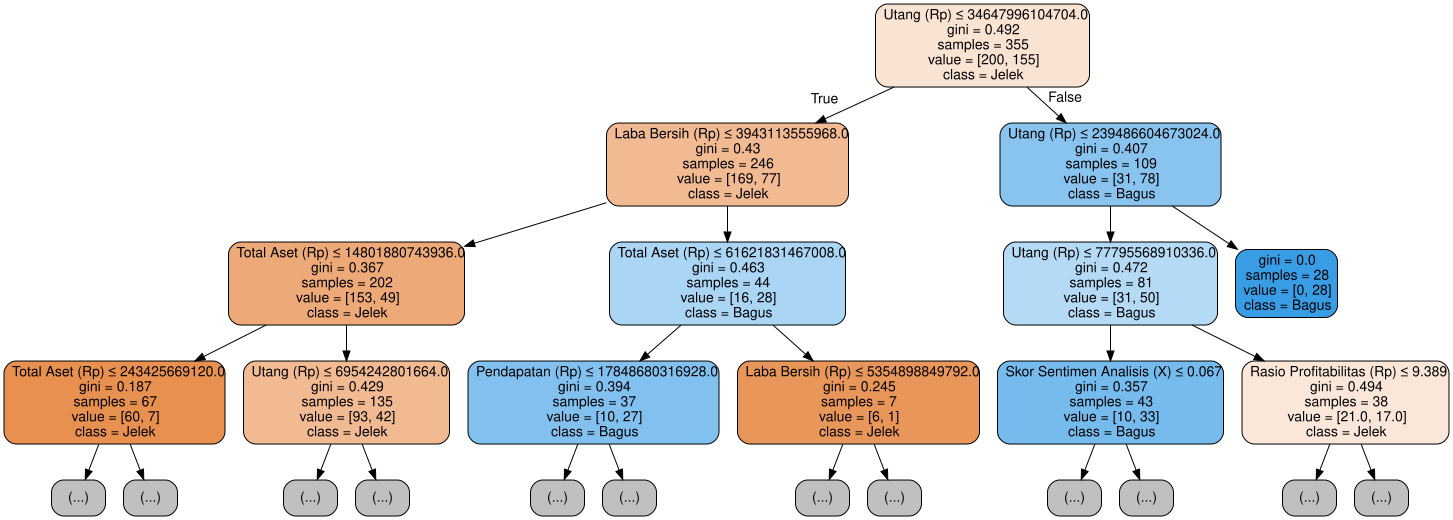

In [ ]:
# Ekspor Decision Tree ke format DOT
dot_data = export_graphviz(dt_classifier, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat objek graphviz dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan tree
graph

### Stacking Classifier

Stacking Classifier:
  - Accuracy: 0.7753
              precision    recall  f1-score   support

       Jelek       0.81      0.74      0.78        47
       Bagus       0.74      0.81      0.77        42

    accuracy                           0.78        89
   macro avg       0.78      0.78      0.78        89
weighted avg       0.78      0.78      0.78        89



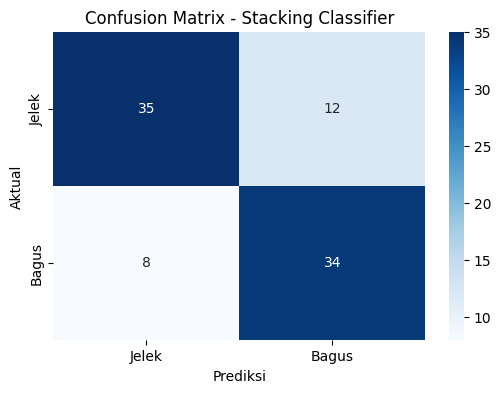

In [ ]:
try:
    # Base models untuk stacking
    estimators = [
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
        ('xgb', XGBClassifier(n_estimators=100, random_state=42)),
        ('gb', GradientBoostingClassifier(n_estimators=100, random_state=42))
    ]

    # Buat dan evaluasi stacking model
    stacking_classifier = StackingClassifier(
        estimators=estimators,
        final_estimator=RandomForestClassifier(n_estimators=100, random_state=42)
    )

    stack_result = evaluate_classification_model(stacking_classifier, X_train, X_test, y_train, y_test, "Stacking Classifier")

except Exception as e:
    print(f"Terjadi kesalahan saat menjalankan model Stacking: {e}")

## 4.2. Test size 0.3

In [ ]:
# Bagi dataset menjadi set pelatihan dan pengujian (Tanpa SMOTE)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

### Random forest Classifier

Random forest Classifier:
  - Accuracy: 0.7612
              precision    recall  f1-score   support

       Jelek       0.81      0.74      0.77        74
       Bagus       0.71      0.78      0.75        60

    accuracy                           0.76       134
   macro avg       0.76      0.76      0.76       134
weighted avg       0.77      0.76      0.76       134



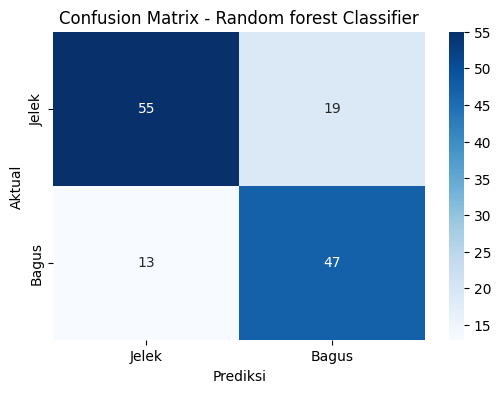

In [ ]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_result = evaluate_classification_model(rf_classifier, X_train, X_test, y_train, y_test, "Random forest Classifier")

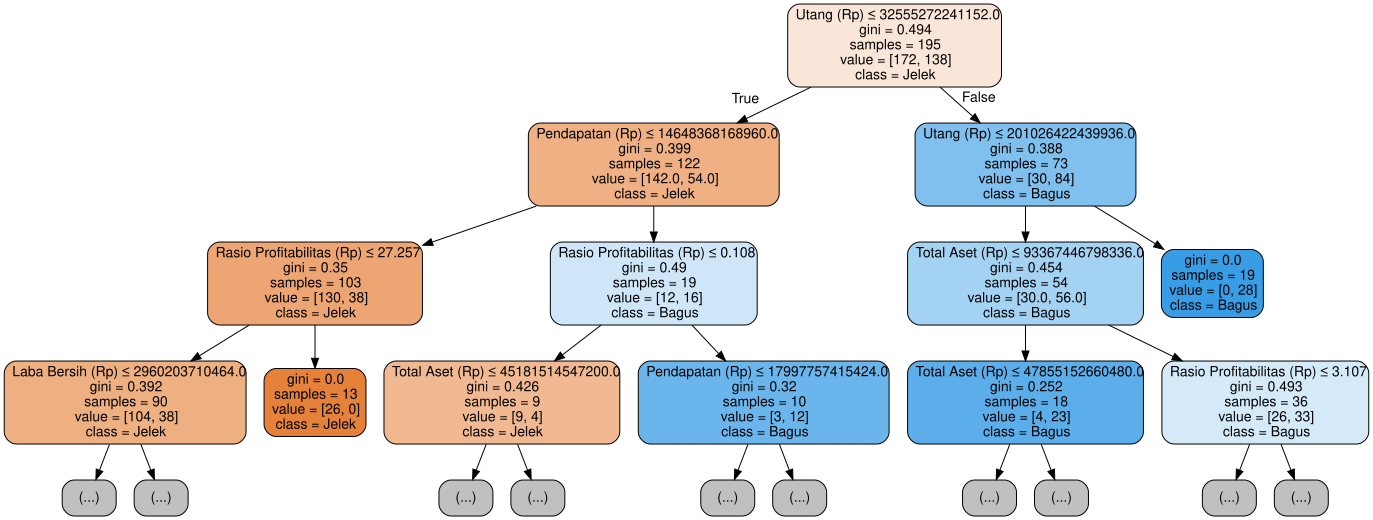

In [ ]:
# Pilih satu pohon dari Random Forest untuk ditampilkan
estimator = rf_classifier.estimators_[0]

# Export pohon ke format DOT
dot_data = export_graphviz(estimator, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat grafik dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan grafik
graph

### Decison Tree

Decision Tree:
  - Accuracy: 0.7015
              precision    recall  f1-score   support

       Jelek       0.76      0.68      0.71        74
       Bagus       0.65      0.73      0.69        60

    accuracy                           0.70       134
   macro avg       0.70      0.70      0.70       134
weighted avg       0.71      0.70      0.70       134



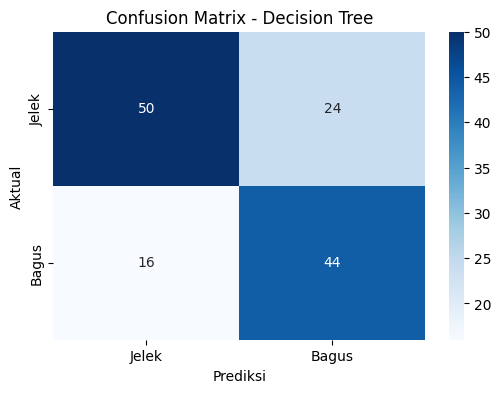

In [ ]:
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_result = evaluate_classification_model(dt_classifier, X_train, X_test, y_train, y_test, "Decision Tree")

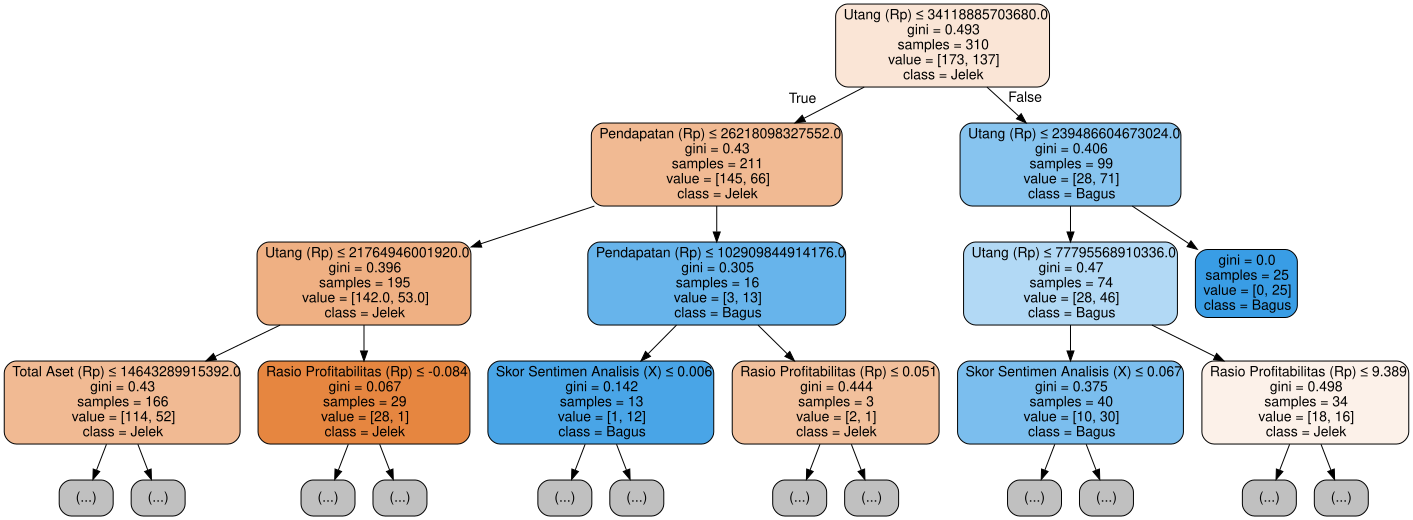

In [ ]:
# Ekspor Decision Tree ke format DOT
dot_data = export_graphviz(dt_classifier, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat objek graphviz dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan tree
graph

### Stacking Classifier

Stacking Classifier:
  - Accuracy: 0.6791
              precision    recall  f1-score   support

       Jelek       0.72      0.68      0.70        74
       Bagus       0.63      0.68      0.66        60

    accuracy                           0.68       134
   macro avg       0.68      0.68      0.68       134
weighted avg       0.68      0.68      0.68       134



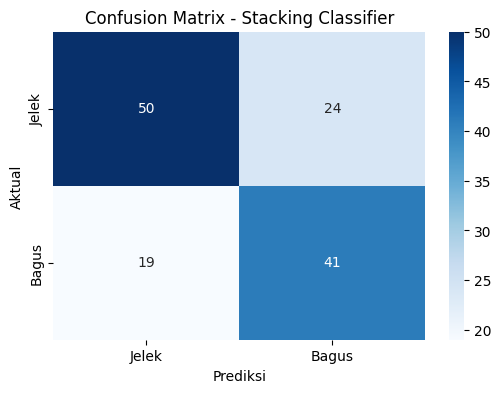

In [ ]:
try:
    # Base models untuk stacking
    estimators = [
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
        ('xgb', XGBClassifier(n_estimators=100, random_state=42)),
        ('gb', GradientBoostingClassifier(n_estimators=100, random_state=42))
    ]

    # Buat dan evaluasi stacking model
    stacking_classifier = StackingClassifier(
        estimators=estimators,
        final_estimator=RandomForestClassifier(n_estimators=100, random_state=42)
    )
    stack_result = evaluate_classification_model(stacking_classifier, X_train, X_test, y_train, y_test, "Stacking Classifier")

except Exception as e:
    print(f"Terjadi kesalahan saat menjalankan model Stacking: {e}")

## 4.3. Test size 0.4

In [ ]:
# Bagi dataset menjadi set pelatihan dan pengujian (Tanpa SMOTE)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

### Random forest Classifier

Random forest Classifier:
  - Accuracy: 0.7360
              precision    recall  f1-score   support

       Jelek       0.75      0.76      0.75        95
       Bagus       0.72      0.71      0.72        83

    accuracy                           0.74       178
   macro avg       0.73      0.73      0.73       178
weighted avg       0.74      0.74      0.74       178



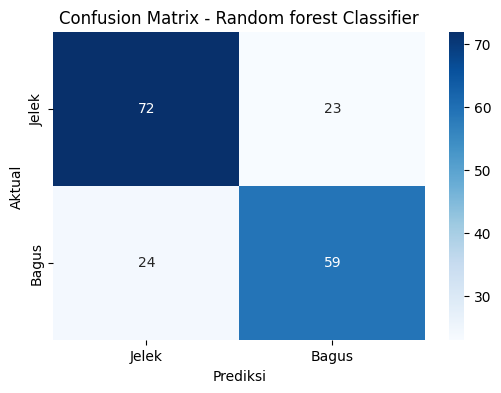

In [ ]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_result = evaluate_classification_model(rf_classifier, X_train, X_test, y_train, y_test, "Random forest Classifier")

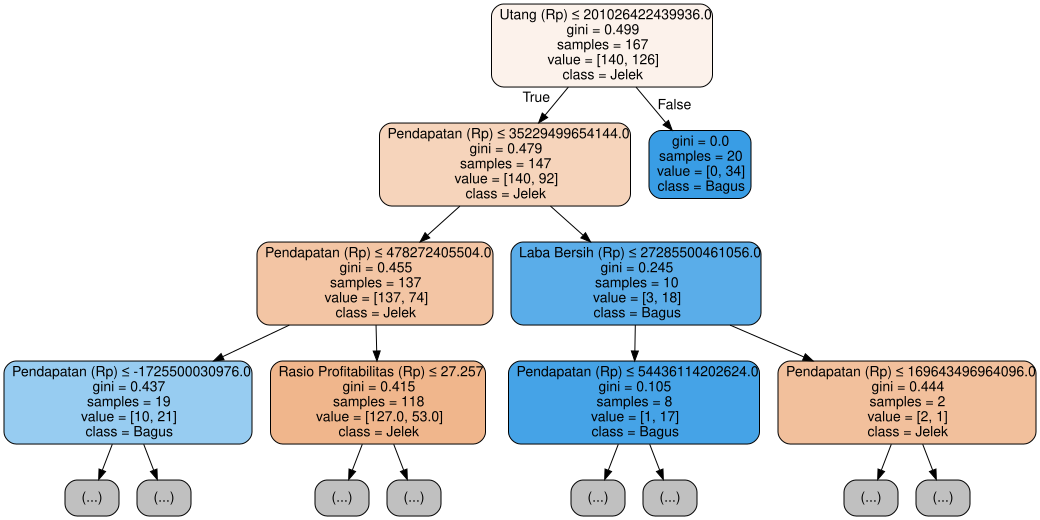

In [ ]:
# Pilih satu pohon dari Random Forest untuk ditampilkan
estimator = rf_classifier.estimators_[0]

# Export pohon ke format DOT
dot_data = export_graphviz(estimator, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat grafik dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan grafik
graph

### Decison Tree

Decision Tree:
  - Accuracy: 0.6798
              precision    recall  f1-score   support

       Jelek       0.68      0.77      0.72        95
       Bagus       0.69      0.58      0.63        83

    accuracy                           0.68       178
   macro avg       0.68      0.67      0.67       178
weighted avg       0.68      0.68      0.68       178



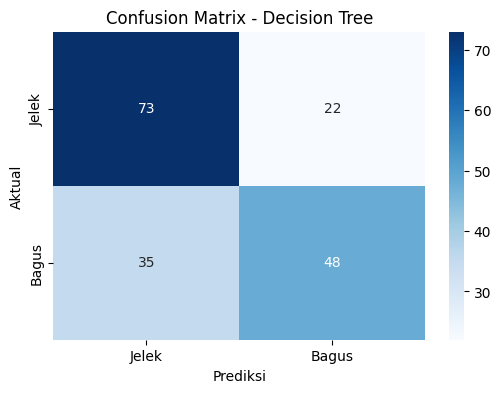

In [ ]:
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_result = evaluate_classification_model(dt_classifier, X_train, X_test, y_train, y_test, "Decision Tree")

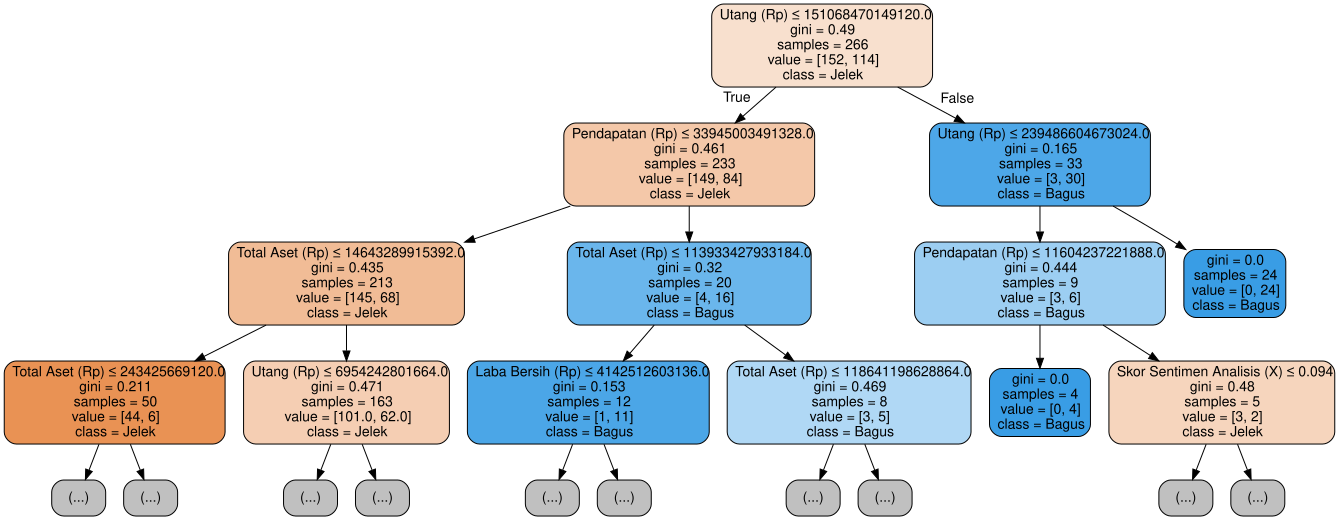

In [ ]:
# Ekspor Decision Tree ke format DOT
dot_data = export_graphviz(dt_classifier, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat objek graphviz dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan tree
graph

### Stacking Classifier

Stacking Classifier:
  - Accuracy: 0.6742
              precision    recall  f1-score   support

       Jelek       0.72      0.64      0.68        95
       Bagus       0.63      0.71      0.67        83

    accuracy                           0.67       178
   macro avg       0.68      0.68      0.67       178
weighted avg       0.68      0.67      0.67       178



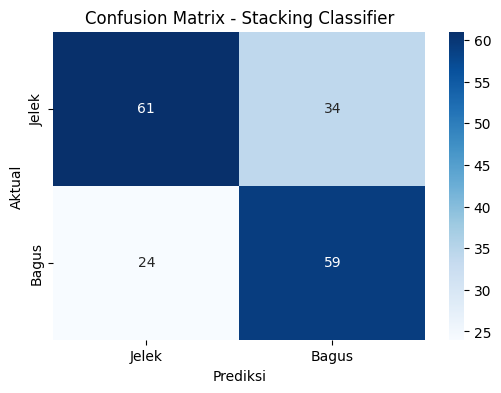

In [ ]:
try:
    # Base models untuk stacking
    estimators = [
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
        ('xgb', XGBClassifier(n_estimators=100, random_state=42)),
        ('gb', GradientBoostingClassifier(n_estimators=100, random_state=42))
    ]
    # Buat dan evaluasi stacking model
    stacking_classifier = StackingClassifier(
        estimators=estimators,
        final_estimator=RandomForestClassifier(n_estimators=100, random_state=42)
    )
    stack_result = evaluate_classification_model(stacking_classifier, X_train, X_test, y_train, y_test, "Stacking Classifier")

except Exception as e:
    print(f"Terjadi kesalahan saat menjalankan model Stacking: {e}")

## 4.4. Kfold 10 lipatan

In [ ]:
def evaluate_classification_model_cv(model, X, y, model_name, classes=class_labels, n_splits=10):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

    fold_accuracies = []

    all_y_true = []
    all_y_pred = []

    fold = 1
    for train_index, test_index in kf.split(X):
        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]

        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        acc = accuracy_score(y_test, y_pred)
        fold_accuracies.append(acc)

        # Simpan semua hasil prediksi dan aktual
        all_y_true.extend(y_test)
        all_y_pred.extend(y_pred)

        fold += 1

    # Hitung akurasi rata-rata
    avg_accuracy = np.mean(fold_accuracies)

    # Evaluasi keseluruhan
    print(f"{model_name} ({n_splits}-Fold CV)")
    print(f"  - Rata-rata Akurasi: {avg_accuracy:.4f}")
    print(classification_report(all_y_true, all_y_pred, target_names=class_labels))

    # Confusion matrix keseluruhan
    plt.figure(figsize=(6, 4))
    cm = confusion_matrix(all_y_true, all_y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_labels,
                yticklabels=class_labels)
    plt.xlabel('Prediksi')
    plt.ylabel('Aktual')
    plt.title(f'Confusion Matrix - {model_name} ({n_splits}-Fold CV)')
    plt.show()

    return model, avg_accuracy

### Random Forest Classifier

Random forest Classifier (10-Fold CV)
  - Rata-rata Akurasi: 0.7635
              precision    recall  f1-score   support

       Jelek       0.77      0.83      0.80       247
       Bagus       0.76      0.69      0.72       197

    accuracy                           0.76       444
   macro avg       0.76      0.76      0.76       444
weighted avg       0.76      0.76      0.76       444



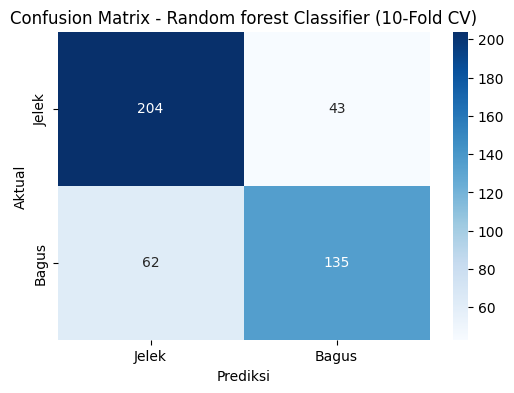

In [ ]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_result = evaluate_classification_model_cv(rf_classifier, X, y, "Random forest Classifier")

### Decision Tree

Decision Tree (10-Fold CV)
  - Rata-rata Akurasi: 0.7027
              precision    recall  f1-score   support

       Jelek       0.73      0.74      0.73       247
       Bagus       0.67      0.65      0.66       197

    accuracy                           0.70       444
   macro avg       0.70      0.70      0.70       444
weighted avg       0.70      0.70      0.70       444



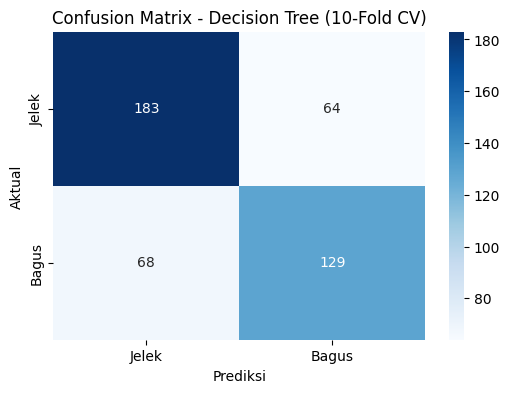

In [ ]:
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_result = evaluate_classification_model_cv(dt_classifier, X, y, "Decision Tree")

### Stacking Classifier

Stacking Classifier (10-Fold CV)
  - Rata-rata Akurasi: 0.7366
              precision    recall  f1-score   support

       Jelek       0.76      0.78      0.77       247
       Bagus       0.71      0.69      0.70       197

    accuracy                           0.74       444
   macro avg       0.73      0.73      0.73       444
weighted avg       0.74      0.74      0.74       444



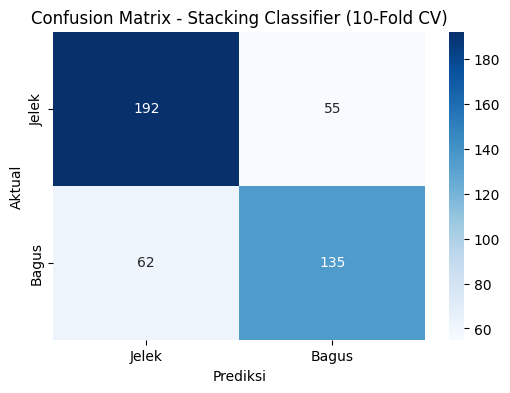

In [ ]:
try:
    # Base models untuk stacking
    estimators = [
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
        ('xgb', XGBClassifier(n_estimators=100, random_state=42)),
        ('gb', GradientBoostingClassifier(n_estimators=100, random_state=42))
    ]
    # Buat dan evaluasi stacking model
    stacking_classifier = StackingClassifier(
        estimators=estimators,
        final_estimator=RandomForestClassifier(n_estimators=100, random_state=42)
    )
    stack_result = evaluate_classification_model_cv(stacking_classifier, X, y, "Stacking Classifier")

except Exception as e:
    print(f"Terjadi kesalahan saat menjalankan model Stacking: {e}")

# Data2: Target ESG LSEG [3 Kelas]

In [ ]:
# Membaca file CSV ke dalam DataFrame
df = pd.read_csv('data2_lseg_3kelas_preprocessing.csv')
print("Jumlah Data:", df.shape)
df.head()

Jumlah Data: (444, 7)


,Pendapatan (Rp),Laba Bersih (Rp),Total Aset (Rp),Utang (Rp),Rasio Profitabilitas (Rp),Skor Sentimen Analisis (X),Skor ESG (LSEG)
0,6.250335e+12,2.516361e+12,4.560035e+13,1.527454e+13,0.4026,0.076,1
1,1.556600e+13,6.749000e+12,1.293120e+14,9.040100e+13,0.4336,0.011,1
2,9.241000e+12,-2.400000e+11,4.289100e+13,4.520000e+12,-0.0150,-0.010,2
3,1.153914e+13,2.259457e+12,6.682765e+13,2.562606e+13,0.1686,0.091,1
4,6.513200e+12,1.558700e+11,1.105251e+13,2.569930e+12,0.0239,0.116,1


## **4. Pemodelan [Awal]**

In [ ]:
# Definisikan X dan y
X = df.drop('Skor ESG (LSEG)', axis=1)
y = df['Skor ESG (LSEG)']

# Label kelasnya
class_labels = ['Jelek', 'Sedang', 'Sangat Bagus']

Jumlah total sampel awal: 444
Jumlah sampel awal: Counter({1: 334, 0: 66, 2: 44})


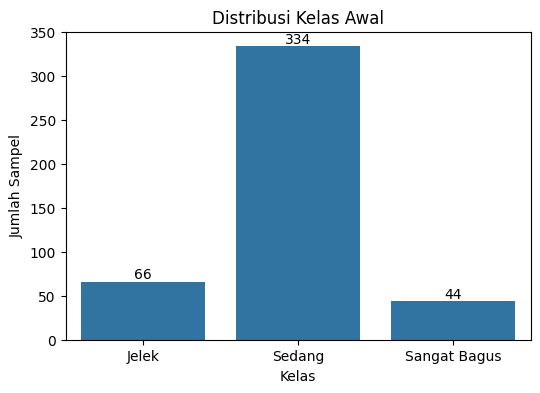

In [ ]:
# Menampilkan jumlah sampel awal
print("Jumlah total sampel awal:", len(y))
print("Jumlah sampel awal:", Counter(y))

# Membuat bar chart distribusi kelas awal
plt.figure(figsize=(6, 4))
sns.countplot(x=y)
plt.title('Distribusi Kelas Awal')
plt.xlabel('Kelas')
plt.xticks(range(len(class_labels)), class_labels)
plt.ylabel('Jumlah Sampel')

# Menambahkan label jumlah data di atas setiap bar
for p in plt.gca().patches:
    plt.gca().annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                       ha='center', va='center', fontsize=10, color='black', xytext=(0, 5),
                       textcoords='offset points')

plt.show()

In [ ]:
# # Melakukan SMOTE untuk mengatasi ketidakseimbangan kelas
# smote = SMOTE(random_state=42)
# X, y = smote.fit_resample(X, y)

# # Menampilkan jumlah sampel setelah SMOTE
# print("Jumlah total sampel setelah SMOTE:", len(y))
# print("Jumlah sampel setelah SMOTE:", Counter(y))

# # Membuat bar chart distribusi kelas setelah SMOTE
# plt.figure(figsize=(6, 4))
# sns.countplot(x=y)
# plt.title('Distribusi Kelas Setelah SMOTE')
# plt.xlabel('Kelas')
# plt.xticks(range(len(class_labels)), class_labels)
# plt.ylabel('Jumlah Sampel')

# # Menambahkan label jumlah data di atas setiap bar
# for p in plt.gca().patches:
#     plt.gca().annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
#                        ha='center', va='center', fontsize=10, color='black', xytext=(0, 5),
#                        textcoords='offset points')

# plt.show()

In [ ]:
# Fungsi untuk evaluasi model klasifikasi (target kategorikal)
def evaluate_classification_model(model, X_train, X_test, y_train, y_test, model_name, classes=class_labels):
    # Latih model
    model.fit(X_train, y_train)

    # Prediksi
    y_pred = model.predict(X_test)

    # Evaluasi
    acc = accuracy_score(y_test, y_pred)

    print(f"{model_name}:")
    print(f"  - Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred, target_names=class_labels))

    # Visualisasi Confusion Matrix
    plt.figure(figsize=(6, 4))
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_labels,
                yticklabels=class_labels
                )
    plt.xlabel('Prediksi')
    plt.ylabel('Aktual')
    plt.title(f'Confusion Matrix - {model_name}')
    plt.show()

    return model, acc

## 4.1. Test size 0.2

In [ ]:
# Bagi dataset menjadi set pelatihan dan pengujian
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Random forest Classifier

Random forest Classifier:
  - Accuracy: 0.8539
              precision    recall  f1-score   support

       Jelek       0.75      0.46      0.57        13
      Sedang       0.87      0.97      0.92        70
Sangat Bagus       0.67      0.33      0.44         6

    accuracy                           0.85        89
   macro avg       0.76      0.59      0.64        89
weighted avg       0.84      0.85      0.84        89



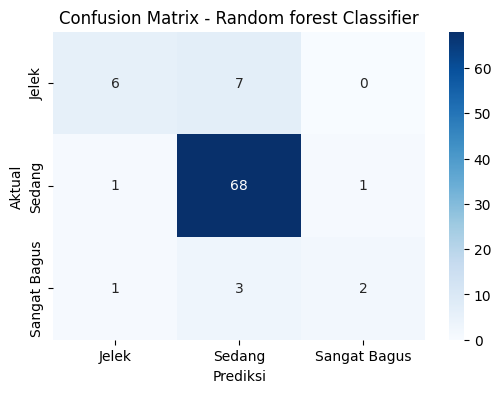

In [ ]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_result = evaluate_classification_model(rf_classifier, X_train, X_test, y_train, y_test, "Random forest Classifier")

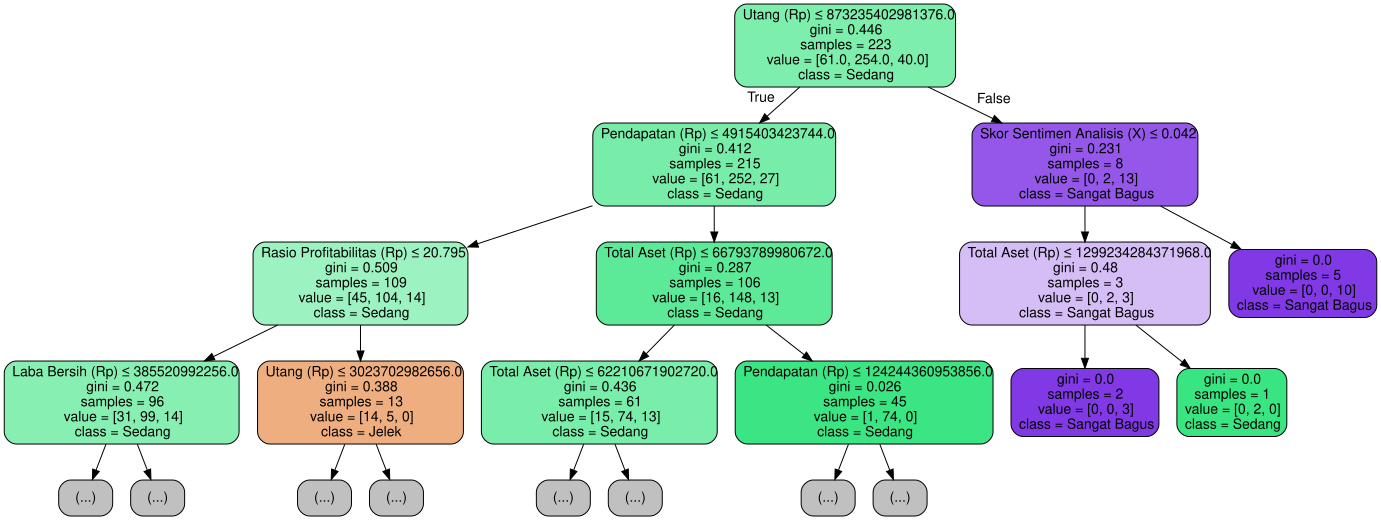

In [ ]:
# Pilih satu pohon dari Random Forest untuk ditampilkan
estimator = rf_classifier.estimators_[0]

# Export pohon ke format DOT
dot_data = export_graphviz(estimator, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat grafik dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan grafik
graph

### Decison Tree

Decision Tree:
  - Accuracy: 0.8539
              precision    recall  f1-score   support

       Jelek       0.64      0.69      0.67        13
      Sedang       0.94      0.90      0.92        70
Sangat Bagus       0.50      0.67      0.57         6

    accuracy                           0.85        89
   macro avg       0.69      0.75      0.72        89
weighted avg       0.87      0.85      0.86        89



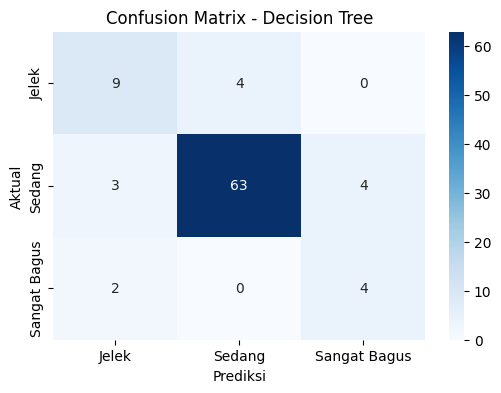

In [ ]:
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_result = evaluate_classification_model(dt_classifier, X_train, X_test, y_train, y_test, "Decision Tree")

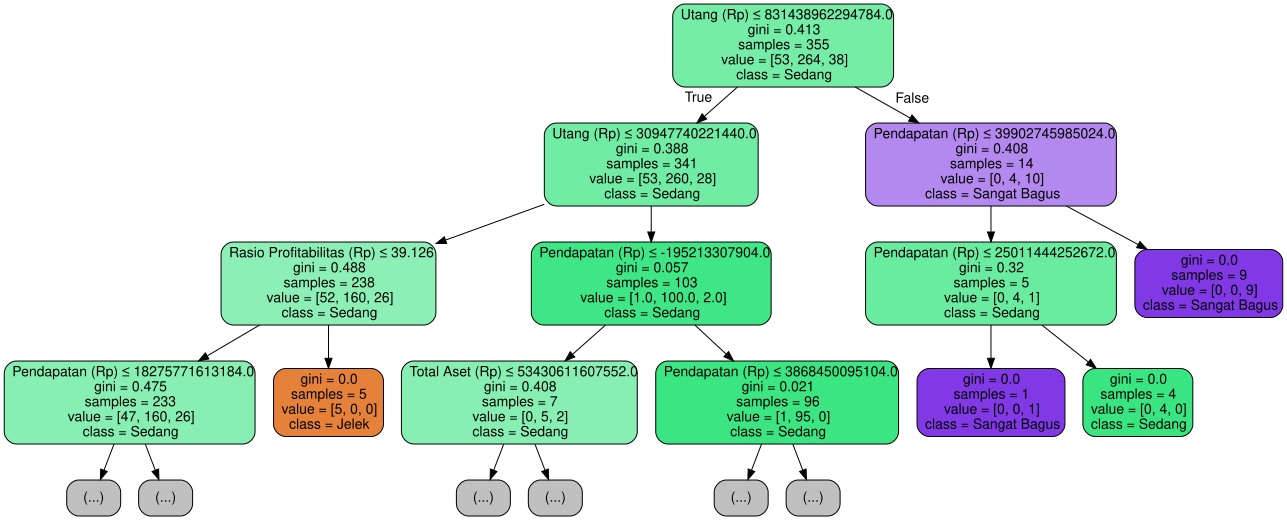

In [ ]:
# Ekspor Decision Tree ke format DOT
dot_data = export_graphviz(dt_classifier, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat objek graphviz dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan tree
graph

### Stacking Classifier

Stacking Classifier:
  - Accuracy: 0.8315
              precision    recall  f1-score   support

       Jelek       0.70      0.54      0.61        13
      Sedang       0.87      0.94      0.90        70
Sangat Bagus       0.33      0.17      0.22         6

    accuracy                           0.83        89
   macro avg       0.63      0.55      0.58        89
weighted avg       0.81      0.83      0.81        89



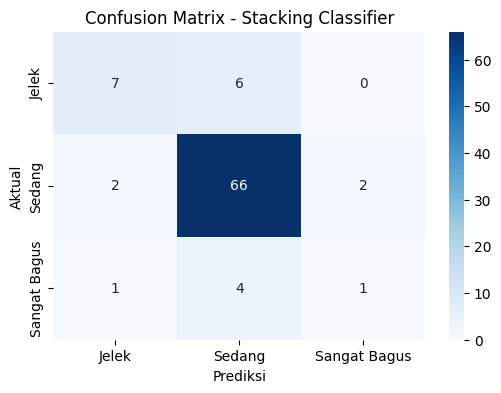

In [ ]:
try:
    # Base models untuk stacking
    estimators = [
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
        ('xgb', XGBClassifier(n_estimators=100, random_state=42)),
        ('gb', GradientBoostingClassifier(n_estimators=100, random_state=42))
    ]

    # Buat dan evaluasi stacking model
    stacking_classifier = StackingClassifier(
        estimators=estimators,
        final_estimator=RandomForestClassifier(n_estimators=100, random_state=42)
    )

    stack_result = evaluate_classification_model(stacking_classifier, X_train, X_test, y_train, y_test, "Stacking Classifier")

except Exception as e:
    print(f"Terjadi kesalahan saat menjalankan model Stacking: {e}")

## 4.2. Test size 0.3

In [ ]:
# Bagi dataset menjadi set pelatihan dan pengujian (Tanpa SMOTE)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

### Random forest Classifier

Random forest Classifier:
  - Accuracy: 0.8358
              precision    recall  f1-score   support

       Jelek       0.88      0.35      0.50        20
      Sedang       0.84      0.96      0.90       101
Sangat Bagus       0.73      0.62      0.67        13

    accuracy                           0.84       134
   macro avg       0.82      0.64      0.69       134
weighted avg       0.84      0.84      0.82       134



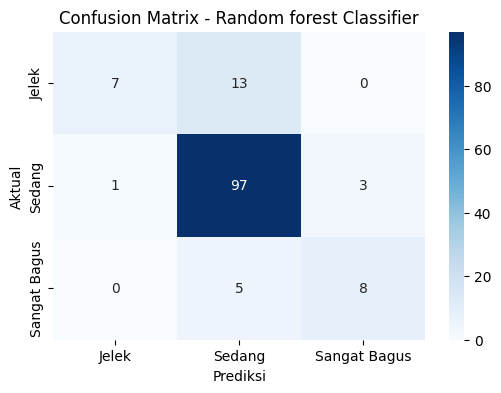

In [ ]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_result = evaluate_classification_model(rf_classifier, X_train, X_test, y_train, y_test, "Random forest Classifier")

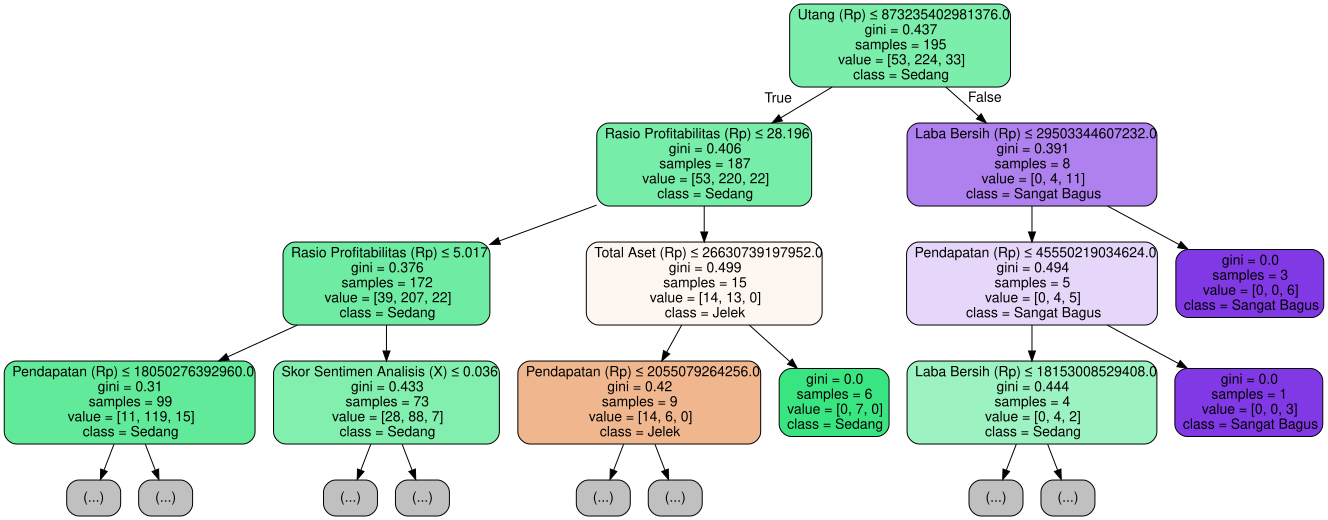

In [ ]:
# Pilih satu pohon dari Random Forest untuk ditampilkan
estimator = rf_classifier.estimators_[0]

# Export pohon ke format DOT
dot_data = export_graphviz(estimator, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat grafik dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan grafik
graph

### Decison Tree

Decision Tree:
  - Accuracy: 0.7761
              precision    recall  f1-score   support

       Jelek       0.53      0.50      0.51        20
      Sedang       0.85      0.85      0.85       101
Sangat Bagus       0.57      0.62      0.59        13

    accuracy                           0.78       134
   macro avg       0.65      0.66      0.65       134
weighted avg       0.78      0.78      0.78       134



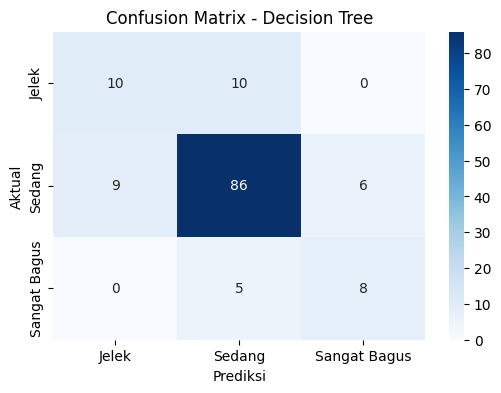

In [ ]:
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_result = evaluate_classification_model(dt_classifier, X_train, X_test, y_train, y_test, "Decision Tree")

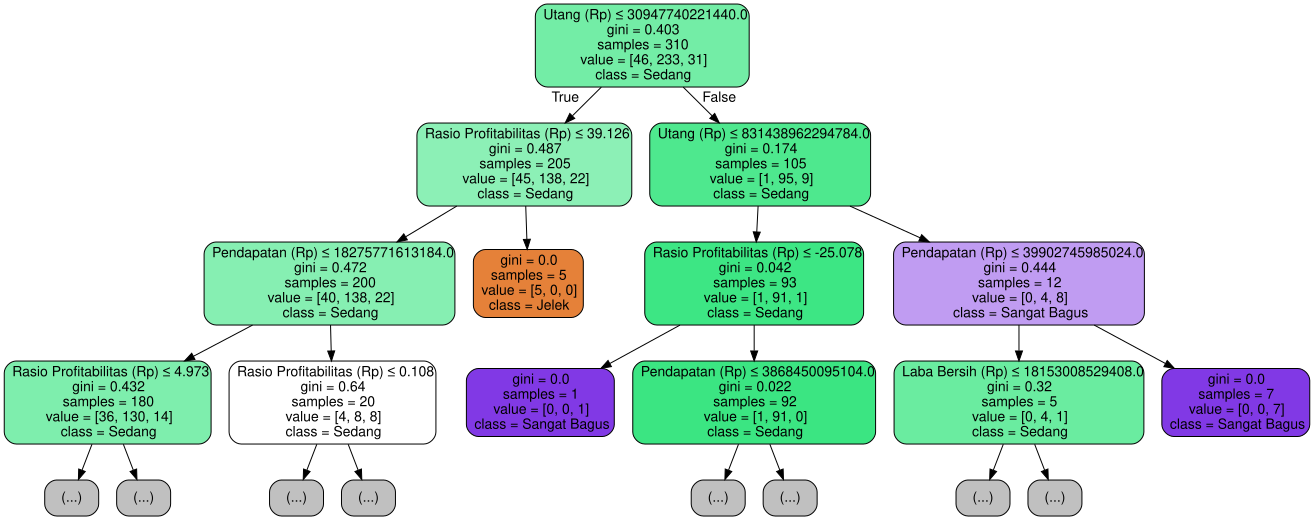

In [ ]:
# Ekspor Decision Tree ke format DOT
dot_data = export_graphviz(dt_classifier, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat objek graphviz dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan tree
graph

### Stacking Classifier

Stacking Classifier:
  - Accuracy: 0.7687
              precision    recall  f1-score   support

       Jelek       0.58      0.35      0.44        20
      Sedang       0.82      0.88      0.85       101
Sangat Bagus       0.50      0.54      0.52        13

    accuracy                           0.77       134
   macro avg       0.64      0.59      0.60       134
weighted avg       0.76      0.77      0.76       134



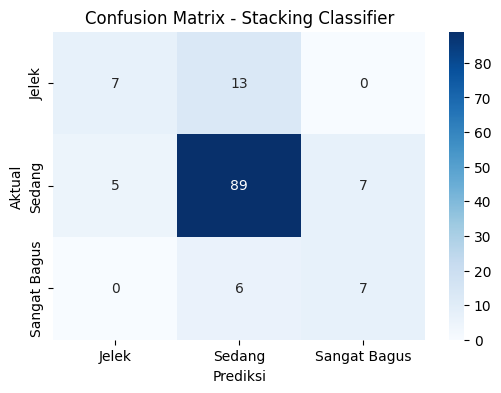

In [ ]:
try:
    # Base models untuk stacking
    estimators = [
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
        ('xgb', XGBClassifier(n_estimators=100, random_state=42)),
        ('gb', GradientBoostingClassifier(n_estimators=100, random_state=42))
    ]

    # Buat dan evaluasi stacking model
    stacking_classifier = StackingClassifier(
        estimators=estimators,
        final_estimator=RandomForestClassifier(n_estimators=100, random_state=42)
    )
    stack_result = evaluate_classification_model(stacking_classifier, X_train, X_test, y_train, y_test, "Stacking Classifier")

except Exception as e:
    print(f"Terjadi kesalahan saat menjalankan model Stacking: {e}")

## 4.3. Test size 0.4

In [ ]:
# Bagi dataset menjadi set pelatihan dan pengujian (Tanpa SMOTE)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

### Random forest Classifier

Random forest Classifier:
  - Accuracy: 0.8146
              precision    recall  f1-score   support

       Jelek       0.80      0.30      0.43        27
      Sedang       0.82      0.96      0.89       135
Sangat Bagus       0.70      0.44      0.54        16

    accuracy                           0.81       178
   macro avg       0.77      0.57      0.62       178
weighted avg       0.81      0.81      0.79       178



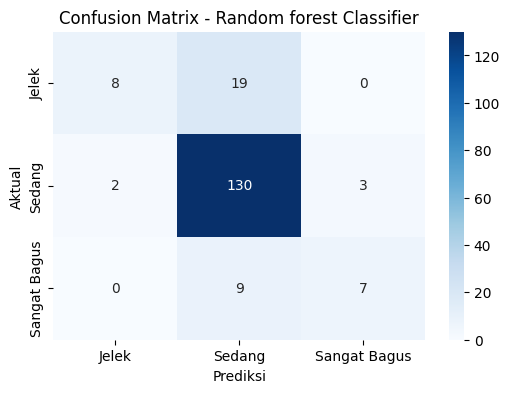

In [ ]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_result = evaluate_classification_model(rf_classifier, X_train, X_test, y_train, y_test, "Random forest Classifier")

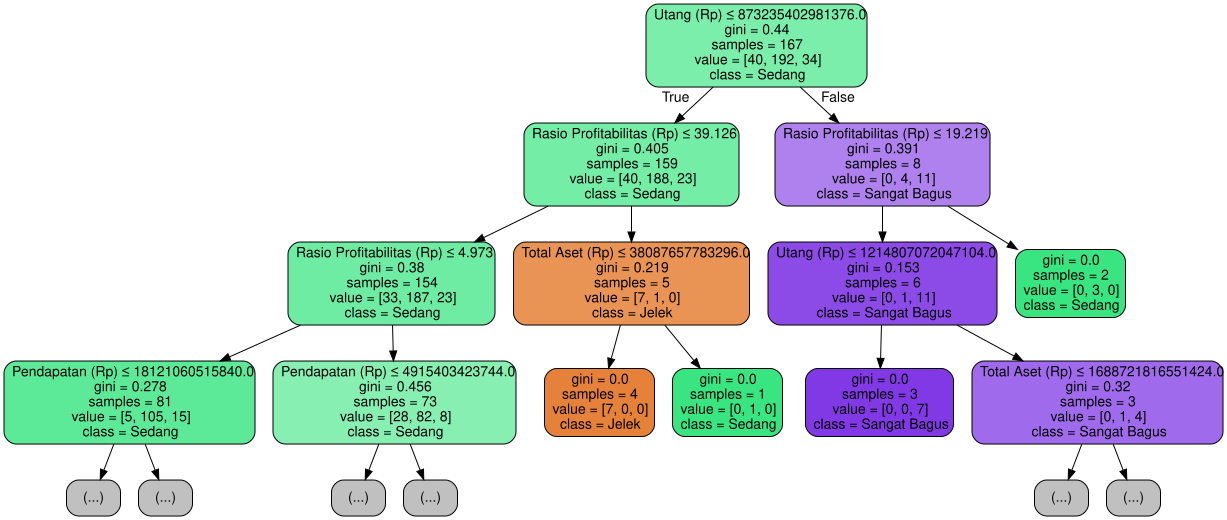

In [ ]:
# Pilih satu pohon dari Random Forest untuk ditampilkan
estimator = rf_classifier.estimators_[0]

# Export pohon ke format DOT
dot_data = export_graphviz(estimator, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat grafik dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan grafik
graph

### Decison Tree

Decision Tree:
  - Accuracy: 0.7640
              precision    recall  f1-score   support

       Jelek       0.59      0.48      0.53        27
      Sedang       0.86      0.85      0.86       135
Sangat Bagus       0.36      0.50      0.42        16

    accuracy                           0.76       178
   macro avg       0.60      0.61      0.60       178
weighted avg       0.77      0.76      0.77       178



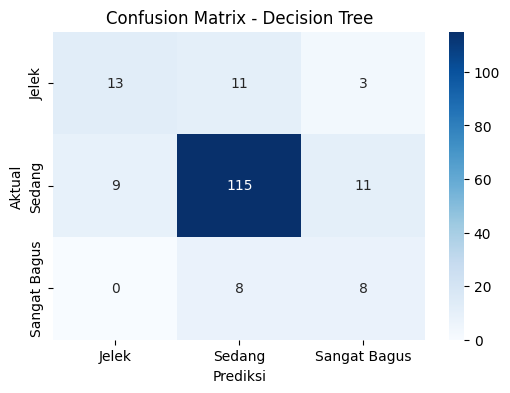

In [ ]:
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_result = evaluate_classification_model(dt_classifier, X_train, X_test, y_train, y_test, "Decision Tree")

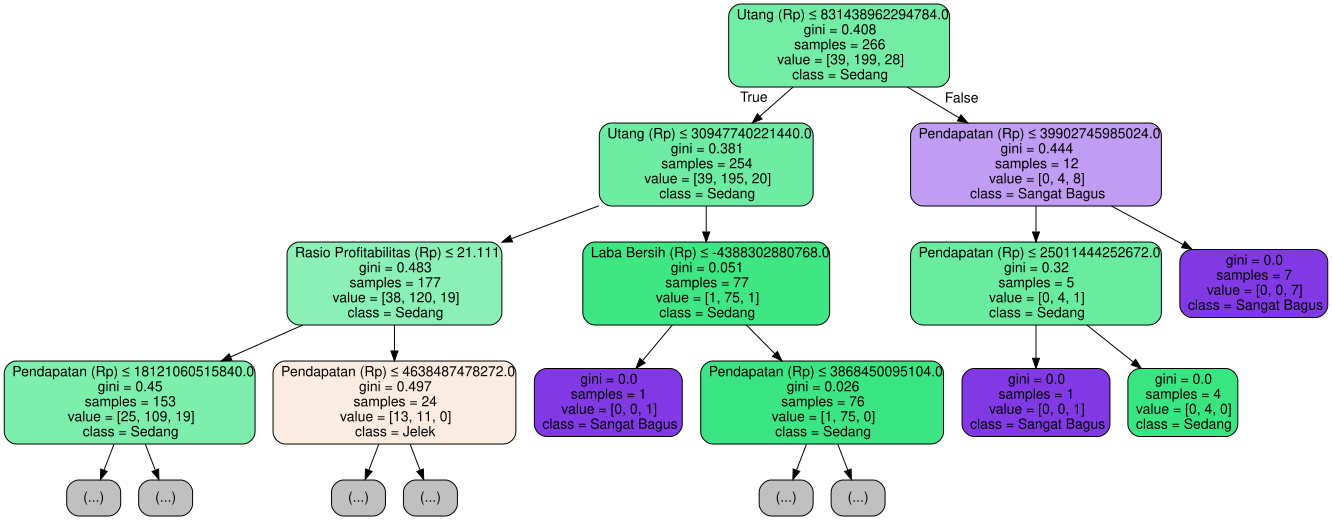

In [ ]:
# Ekspor Decision Tree ke format DOT
dot_data = export_graphviz(dt_classifier, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat objek graphviz dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan tree
graph

### Stacking Classifier

Stacking Classifier:
  - Accuracy: 0.7640
              precision    recall  f1-score   support

       Jelek       0.69      0.33      0.45        27
      Sedang       0.82      0.90      0.86       135
Sangat Bagus       0.35      0.38      0.36        16

    accuracy                           0.76       178
   macro avg       0.62      0.53      0.56       178
weighted avg       0.76      0.76      0.75       178



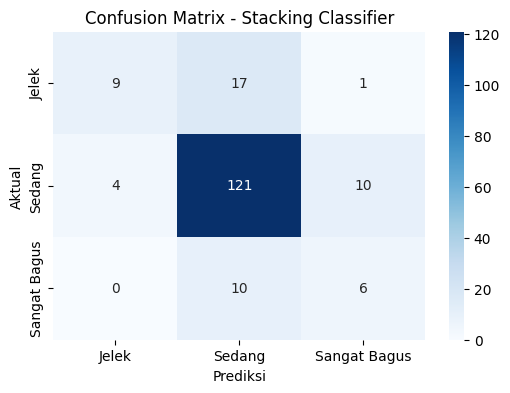

In [ ]:
try:
    # Base models untuk stacking
    estimators = [
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
        ('xgb', XGBClassifier(n_estimators=100, random_state=42)),
        ('gb', GradientBoostingClassifier(n_estimators=100, random_state=42))
    ]
    # Buat dan evaluasi stacking model
    stacking_classifier = StackingClassifier(
        estimators=estimators,
        final_estimator=RandomForestClassifier(n_estimators=100, random_state=42)
    )
    stack_result = evaluate_classification_model(stacking_classifier, X_train, X_test, y_train, y_test, "Stacking Classifier")

except Exception as e:
    print(f"Terjadi kesalahan saat menjalankan model Stacking: {e}")

## 4.4. Kfold 10 lipatan

In [ ]:
def evaluate_classification_model_cv(model, X, y, model_name, classes=class_labels, n_splits=10):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

    fold_accuracies = []

    all_y_true = []
    all_y_pred = []

    fold = 1
    for train_index, test_index in kf.split(X):
        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]

        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        acc = accuracy_score(y_test, y_pred)
        fold_accuracies.append(acc)

        # Simpan semua hasil prediksi dan aktual
        all_y_true.extend(y_test)
        all_y_pred.extend(y_pred)

        fold += 1

    # Hitung akurasi rata-rata
    avg_accuracy = np.mean(fold_accuracies)

    # Evaluasi keseluruhan
    print(f"{model_name} ({n_splits}-Fold CV)")
    print(f"  - Rata-rata Akurasi: {avg_accuracy:.4f}")
    print(classification_report(all_y_true, all_y_pred, target_names=class_labels))

    # Confusion matrix keseluruhan
    plt.figure(figsize=(6, 4))
    cm = confusion_matrix(all_y_true, all_y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_labels,
                yticklabels=class_labels)
    plt.xlabel('Prediksi')
    plt.ylabel('Aktual')
    plt.title(f'Confusion Matrix - {model_name} ({n_splits}-Fold CV)')
    plt.show()

    return model, avg_accuracy

### Random Forest Classifier

Random forest Classifier (10-Fold CV)
  - Rata-rata Akurasi: 0.8243
              precision    recall  f1-score   support

       Jelek       0.72      0.47      0.57        66
      Sedang       0.84      0.96      0.89       334
Sangat Bagus       0.76      0.36      0.49        44

    accuracy                           0.82       444
   macro avg       0.77      0.60      0.65       444
weighted avg       0.81      0.82      0.81       444



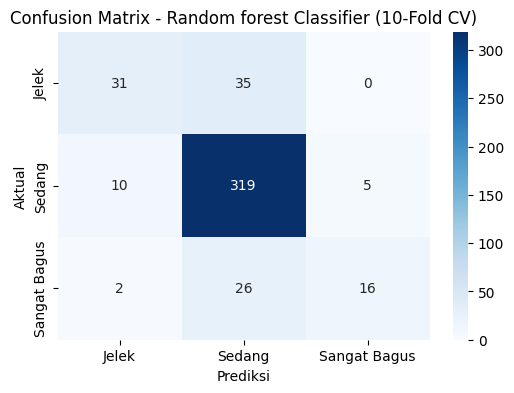

In [ ]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_result = evaluate_classification_model_cv(rf_classifier, X, y, "Random forest Classifier")

### Decision Tree

Decision Tree (10-Fold CV)
  - Rata-rata Akurasi: 0.7591
              precision    recall  f1-score   support

       Jelek       0.44      0.52      0.48        66
      Sedang       0.85      0.83      0.84       334
Sangat Bagus       0.61      0.61      0.61        44

    accuracy                           0.76       444
   macro avg       0.64      0.65      0.64       444
weighted avg       0.77      0.76      0.76       444



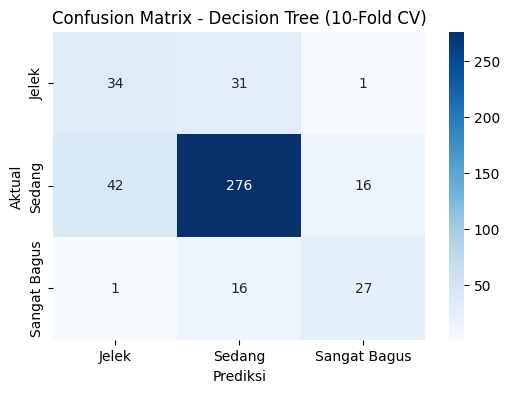

In [ ]:
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_result = evaluate_classification_model_cv(dt_classifier, X, y, "Decision Tree")

### Stacking Classifier

Stacking Classifier (10-Fold CV)
  - Rata-rata Akurasi: 0.8042
              precision    recall  f1-score   support

       Jelek       0.69      0.41      0.51        66
      Sedang       0.84      0.93      0.88       334
Sangat Bagus       0.54      0.43      0.48        44

    accuracy                           0.80       444
   macro avg       0.69      0.59      0.63       444
weighted avg       0.79      0.80      0.79       444



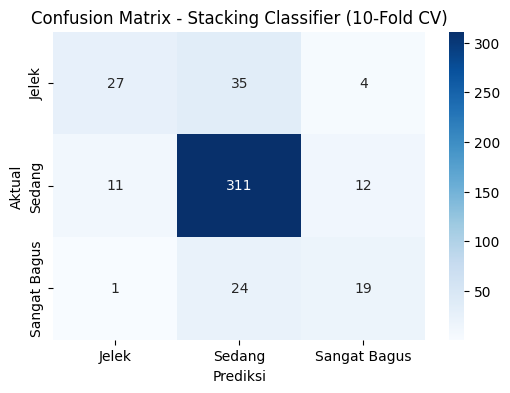

In [ ]:
try:
    # Base models untuk stacking
    estimators = [
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
        ('xgb', XGBClassifier(n_estimators=100, random_state=42)),
        ('gb', GradientBoostingClassifier(n_estimators=100, random_state=42))
    ]
    # Buat dan evaluasi stacking model
    stacking_classifier = StackingClassifier(
        estimators=estimators,
        final_estimator=RandomForestClassifier(n_estimators=100, random_state=42)
    )
    stack_result = evaluate_classification_model_cv(stacking_classifier, X, y, "Stacking Classifier")

except Exception as e:
    print(f"Terjadi kesalahan saat menjalankan model Stacking: {e}")



---


# **Skenario 3:** Independen Atribut Kategorikal + Target Kategorikal

# Data3: Target ESG LSEG [3 Kelas]

In [ ]:
# Membaca file CSV ke dalam DataFrame
df = pd.read_csv('data3_lseg_3kelas_preprocessing.csv')
print("Jumlah Data:", df.shape)
df.head()

Jumlah Data: (444, 7)


,Pendapatan (Rp),Laba Bersih (Rp),Total Aset (Rp),Utang (Rp),Rasio Profitabilitas (Rp),Sentimen Analisis (X),Skor ESG (LSEG)
0,2,2,2,1,0,1,1
1,2,2,2,2,0,1,1
2,2,0,2,0,0,0,2
3,2,2,2,2,0,1,1
4,2,0,0,0,0,1,1


## **4. Pemodelan [Awal]**

In [ ]:
# Definisikan X dan y
X = df.drop('Skor ESG (LSEG)', axis=1)
y = df['Skor ESG (LSEG)']

# Label kelasnya
class_labels = ['Jelek', 'Sedang', 'Sangat Bagus']

Jumlah total sampel awal: 444
Jumlah sampel awal: Counter({1: 334, 0: 66, 2: 44})


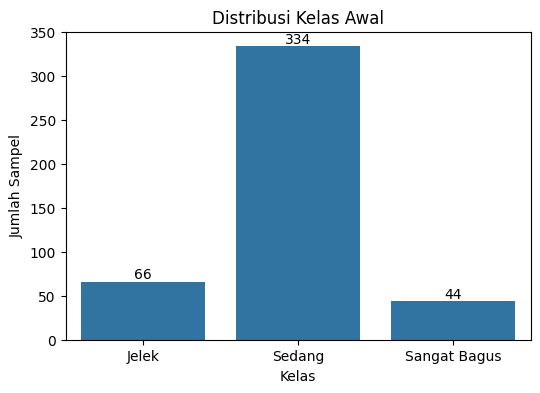

In [ ]:
# Menampilkan jumlah sampel awal
print("Jumlah total sampel awal:", len(y))
print("Jumlah sampel awal:", Counter(y))

# Membuat bar chart distribusi kelas awal
plt.figure(figsize=(6, 4))
sns.countplot(x=y)
plt.title('Distribusi Kelas Awal')
plt.xlabel('Kelas')
plt.xticks(range(len(class_labels)), class_labels)
plt.ylabel('Jumlah Sampel')

# Menambahkan label jumlah data di atas setiap bar
for p in plt.gca().patches:
    plt.gca().annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                       ha='center', va='center', fontsize=10, color='black', xytext=(0, 5),
                       textcoords='offset points')

plt.show()

Jumlah total sampel setelah SMOTE: 1002
Jumlah sampel setelah SMOTE: Counter({1: 334, 2: 334, 0: 334})


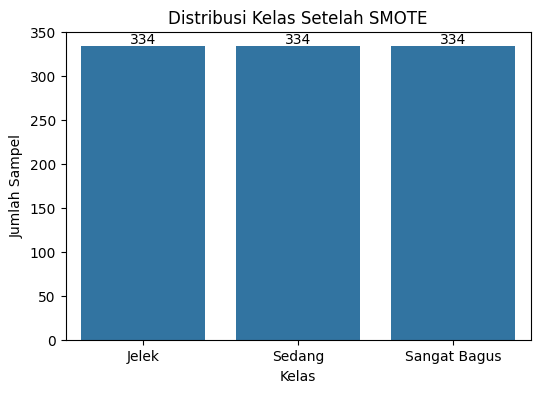

In [ ]:
# Melakukan SMOTE untuk mengatasi ketidakseimbangan kelas
smote = SMOTE(random_state=42)
X, y = smote.fit_resample(X, y)

# Menampilkan jumlah sampel setelah SMOTE
print("Jumlah total sampel setelah SMOTE:", len(y))
print("Jumlah sampel setelah SMOTE:", Counter(y))

# Membuat bar chart distribusi kelas setelah SMOTE
plt.figure(figsize=(6, 4))
sns.countplot(x=y)
plt.title('Distribusi Kelas Setelah SMOTE')
plt.xlabel('Kelas')
plt.xticks(range(len(class_labels)), class_labels)
plt.ylabel('Jumlah Sampel')

# Menambahkan label jumlah data di atas setiap bar
for p in plt.gca().patches:
    plt.gca().annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                       ha='center', va='center', fontsize=10, color='black', xytext=(0, 5),
                       textcoords='offset points')

plt.show()

In [ ]:
# Fungsi untuk evaluasi model klasifikasi (target kategorikal)
def evaluate_classification_model(model, X_train, X_test, y_train, y_test, model_name, classes=class_labels):
    # Latih model
    model.fit(X_train, y_train)

    # Prediksi
    y_pred = model.predict(X_test)

    # Evaluasi
    acc = accuracy_score(y_test, y_pred)

    print(f"{model_name}:")
    print(f"  - Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred, target_names=class_labels))

    # Visualisasi Confusion Matrix
    plt.figure(figsize=(6, 4))
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_labels,
                yticklabels=class_labels
                )
    plt.xlabel('Prediksi')
    plt.ylabel('Aktual')
    plt.title(f'Confusion Matrix - {model_name}')
    plt.show()

    return model, acc

## 4.1. Test size 0.2

In [ ]:
# Bagi dataset menjadi set pelatihan dan pengujian
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Random forest Classifier

Random forest Classifier:
  - Accuracy: 0.7413
              precision    recall  f1-score   support

       Jelek       0.72      0.70      0.71        66
      Sedang       0.79      0.60      0.68        68
Sangat Bagus       0.73      0.93      0.82        67

    accuracy                           0.74       201
   macro avg       0.75      0.74      0.74       201
weighted avg       0.75      0.74      0.74       201



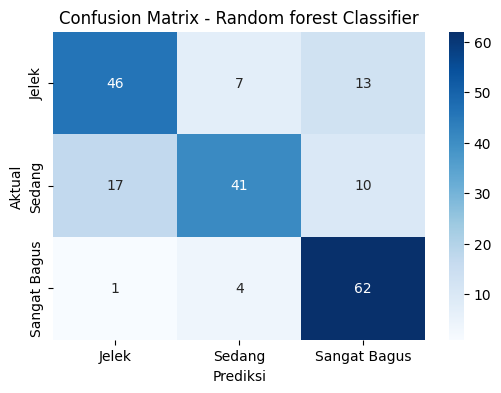

In [ ]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_result = evaluate_classification_model(rf_classifier, X_train, X_test, y_train, y_test, "Random forest Classifier")

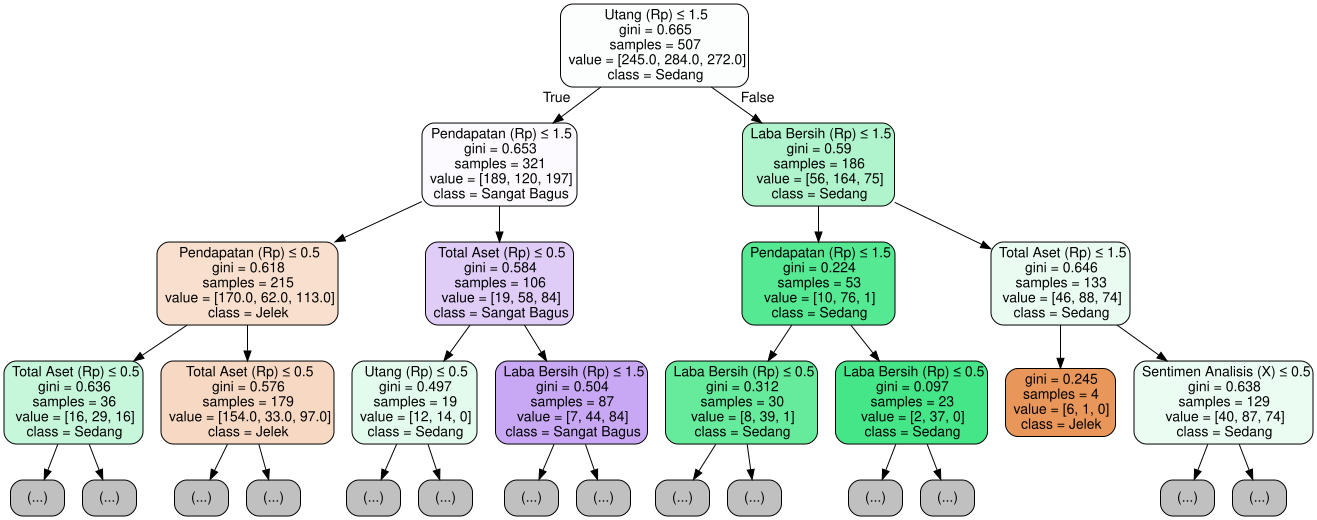

In [ ]:
# Pilih satu pohon dari Random Forest untuk ditampilkan
estimator = rf_classifier.estimators_[0]

# Export pohon ke format DOT
dot_data = export_graphviz(estimator, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat grafik dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan grafik
graph

### Decison Tree

Decision Tree:
  - Accuracy: 0.7413
              precision    recall  f1-score   support

       Jelek       0.72      0.70      0.71        66
      Sedang       0.79      0.60      0.68        68
Sangat Bagus       0.73      0.93      0.82        67

    accuracy                           0.74       201
   macro avg       0.75      0.74      0.74       201
weighted avg       0.75      0.74      0.74       201



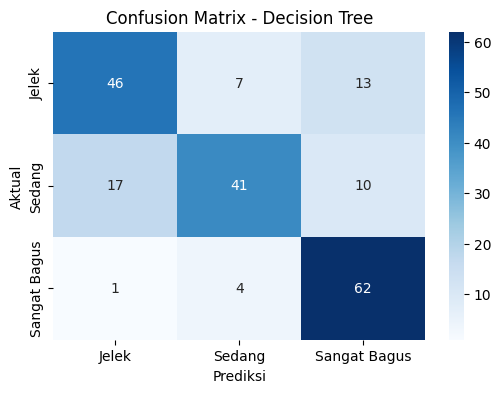

In [ ]:
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_result = evaluate_classification_model(dt_classifier, X_train, X_test, y_train, y_test, "Decision Tree")

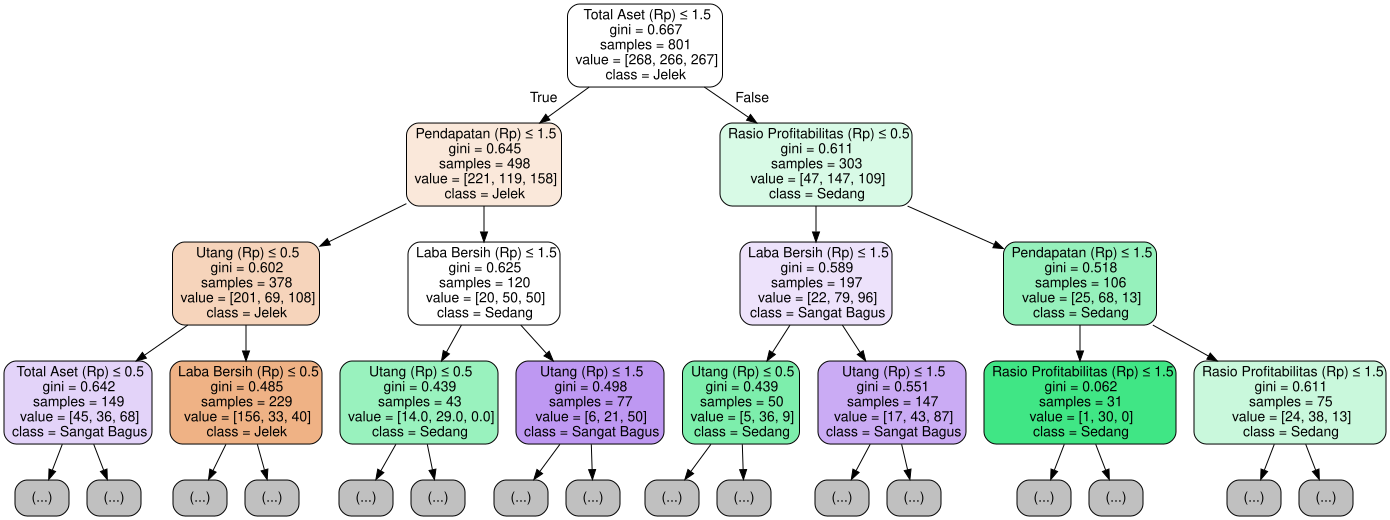

In [ ]:
# Ekspor Decision Tree ke format DOT
dot_data = export_graphviz(dt_classifier, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat objek graphviz dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan tree
graph

### Stacking Classifier

Stacking Classifier:
  - Accuracy: 0.7413
              precision    recall  f1-score   support

       Jelek       0.72      0.70      0.71        66
      Sedang       0.79      0.60      0.68        68
Sangat Bagus       0.73      0.93      0.82        67

    accuracy                           0.74       201
   macro avg       0.75      0.74      0.74       201
weighted avg       0.75      0.74      0.74       201



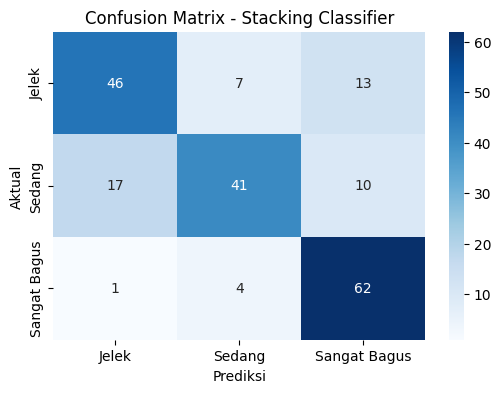

In [ ]:
try:
    # Base models untuk stacking
    estimators = [
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
        ('xgb', XGBClassifier(n_estimators=100, random_state=42)),
        ('gb', GradientBoostingClassifier(n_estimators=100, random_state=42))
    ]

    # Buat dan evaluasi stacking model
    stacking_classifier = StackingClassifier(
        estimators=estimators,
        final_estimator=RandomForestClassifier(n_estimators=100, random_state=42)
    )

    stack_result = evaluate_classification_model(stacking_classifier, X_train, X_test, y_train, y_test, "Stacking Classifier")

except Exception as e:
    print(f"Terjadi kesalahan saat menjalankan model Stacking: {e}")

## 4.2. Test size 0.3

In [ ]:
# Bagi dataset menjadi set pelatihan dan pengujian (Tanpa SMOTE)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

### Random forest Classifier

Random forest Classifier:
  - Accuracy: 0.7508
              precision    recall  f1-score   support

       Jelek       0.77      0.73      0.75        99
      Sedang       0.79      0.61      0.69       102
Sangat Bagus       0.71      0.92      0.80       100

    accuracy                           0.75       301
   macro avg       0.76      0.75      0.75       301
weighted avg       0.76      0.75      0.75       301



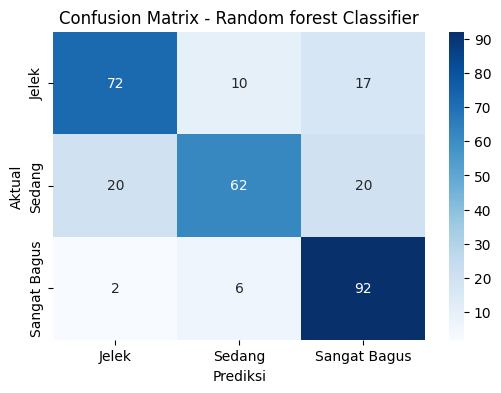

In [ ]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_result = evaluate_classification_model(rf_classifier, X_train, X_test, y_train, y_test, "Random forest Classifier")

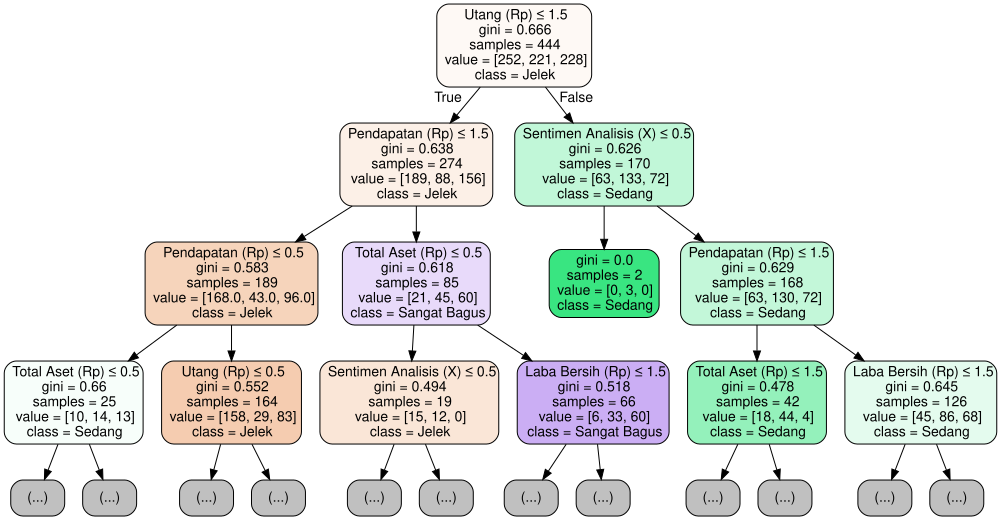

In [ ]:
# Pilih satu pohon dari Random Forest untuk ditampilkan
estimator = rf_classifier.estimators_[0]

# Export pohon ke format DOT
dot_data = export_graphviz(estimator, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat grafik dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan grafik
graph

### Decison Tree

Decision Tree:
  - Accuracy: 0.7508
              precision    recall  f1-score   support

       Jelek       0.77      0.73      0.75        99
      Sedang       0.79      0.61      0.69       102
Sangat Bagus       0.71      0.92      0.80       100

    accuracy                           0.75       301
   macro avg       0.76      0.75      0.75       301
weighted avg       0.76      0.75      0.75       301



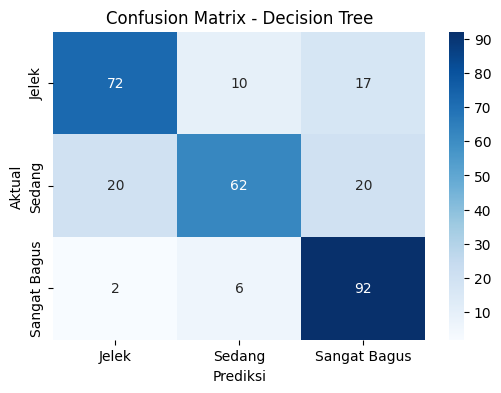

In [ ]:
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_result = evaluate_classification_model(dt_classifier, X_train, X_test, y_train, y_test, "Decision Tree")

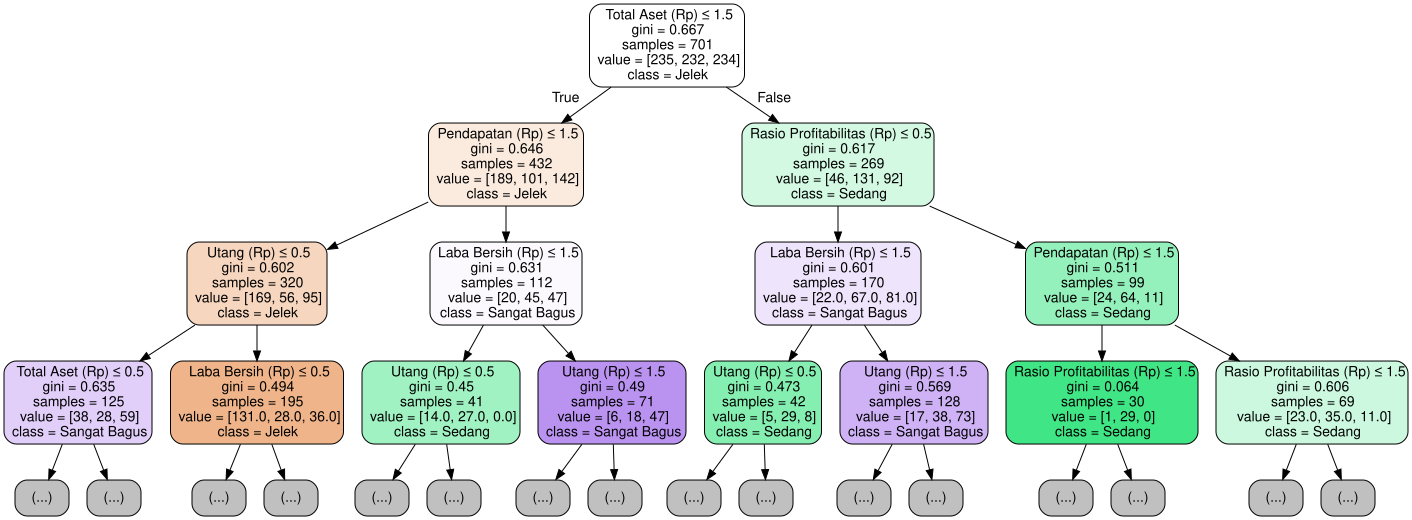

In [ ]:
# Ekspor Decision Tree ke format DOT
dot_data = export_graphviz(dt_classifier, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat objek graphviz dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan tree
graph

### Stacking Classifier

Stacking Classifier:
  - Accuracy: 0.7542
              precision    recall  f1-score   support

       Jelek       0.77      0.73      0.75        99
      Sedang       0.81      0.61      0.69       102
Sangat Bagus       0.71      0.93      0.81       100

    accuracy                           0.75       301
   macro avg       0.76      0.76      0.75       301
weighted avg       0.76      0.75      0.75       301



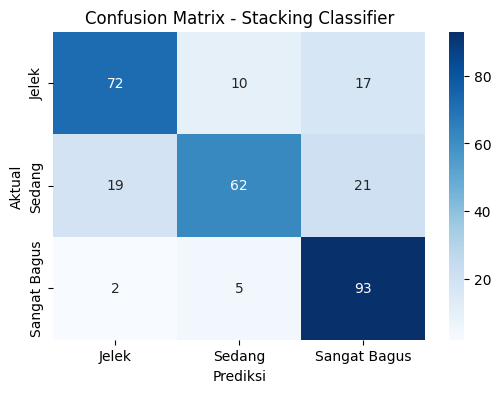

In [ ]:
try:
    # Base models untuk stacking
    estimators = [
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
        ('xgb', XGBClassifier(n_estimators=100, random_state=42)),
        ('gb', GradientBoostingClassifier(n_estimators=100, random_state=42))
    ]

    # Buat dan evaluasi stacking model
    stacking_classifier = StackingClassifier(
        estimators=estimators,
        final_estimator=RandomForestClassifier(n_estimators=100, random_state=42)
    )
    stack_result = evaluate_classification_model(stacking_classifier, X_train, X_test, y_train, y_test, "Stacking Classifier")

except Exception as e:
    print(f"Terjadi kesalahan saat menjalankan model Stacking: {e}")

## 4.3. Test size 0.4

In [ ]:
# Bagi dataset menjadi set pelatihan dan pengujian (Tanpa SMOTE)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

### Random forest Classifier

Random forest Classifier:
  - Accuracy: 0.7282
              precision    recall  f1-score   support

       Jelek       0.73      0.71      0.72       135
      Sedang       0.81      0.57      0.67       144
Sangat Bagus       0.67      0.93      0.78       122

    accuracy                           0.73       401
   macro avg       0.74      0.74      0.72       401
weighted avg       0.74      0.73      0.72       401



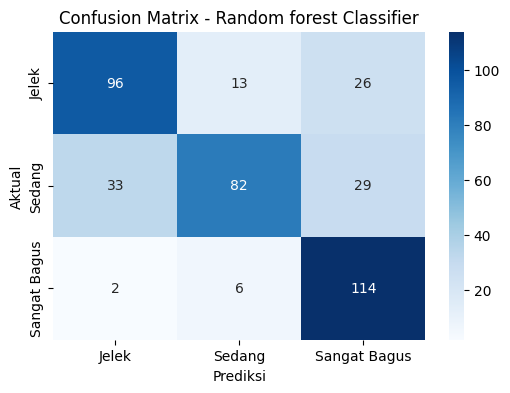

In [ ]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_result = evaluate_classification_model(rf_classifier, X_train, X_test, y_train, y_test, "Random forest Classifier")

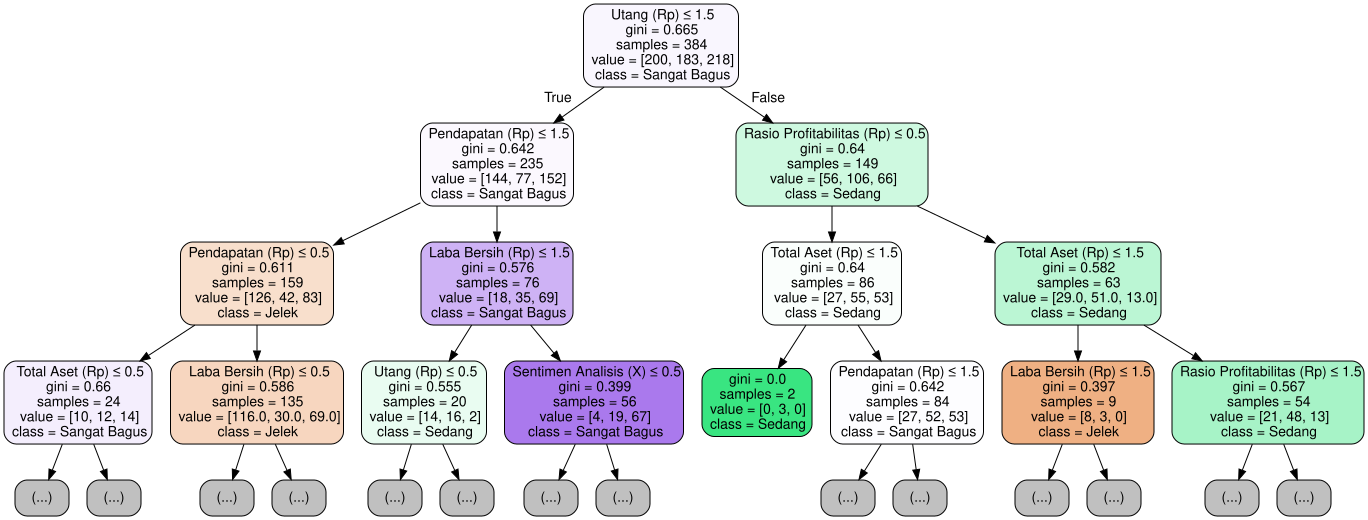

In [ ]:
# Pilih satu pohon dari Random Forest untuk ditampilkan
estimator = rf_classifier.estimators_[0]

# Export pohon ke format DOT
dot_data = export_graphviz(estimator, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat grafik dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan grafik
graph

### Decison Tree

Decision Tree:
  - Accuracy: 0.7257
              precision    recall  f1-score   support

       Jelek       0.72      0.73      0.72       135
      Sedang       0.82      0.58      0.68       144
Sangat Bagus       0.67      0.89      0.77       122

    accuracy                           0.73       401
   macro avg       0.74      0.73      0.72       401
weighted avg       0.74      0.73      0.72       401



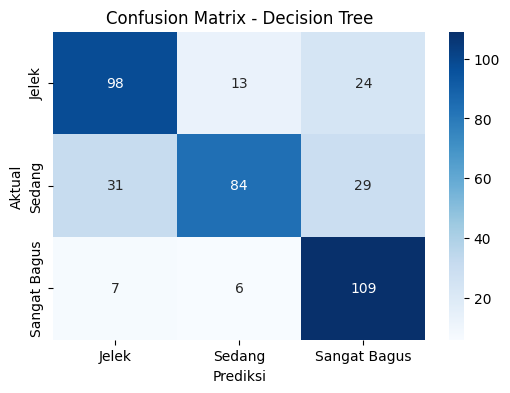

In [ ]:
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_result = evaluate_classification_model(dt_classifier, X_train, X_test, y_train, y_test, "Decision Tree")

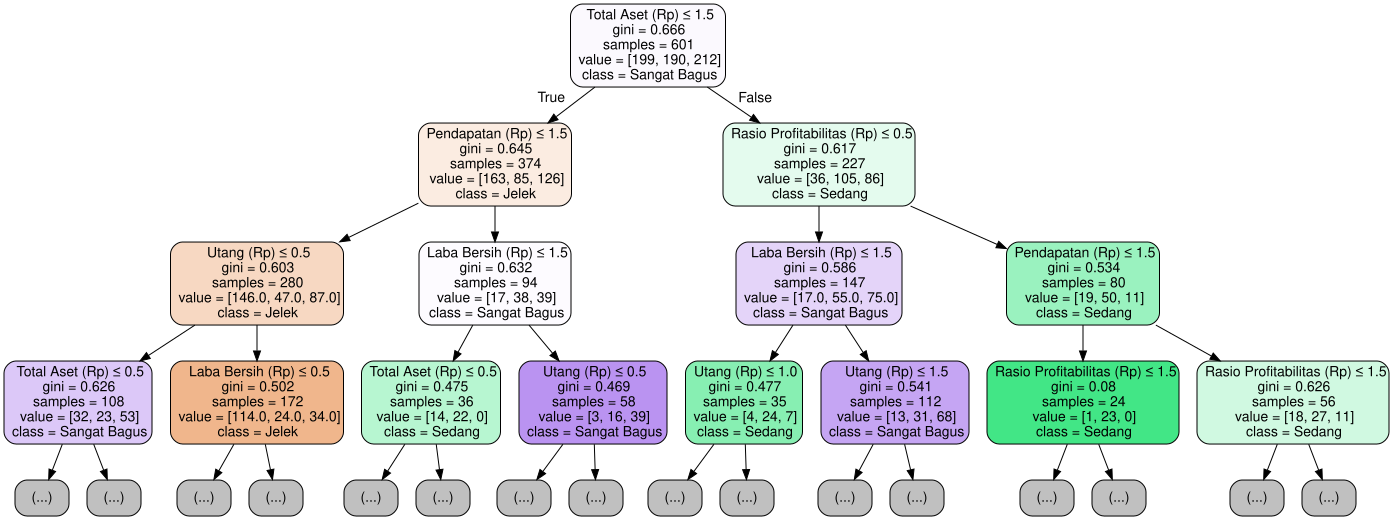

In [ ]:
# Ekspor Decision Tree ke format DOT
dot_data = export_graphviz(dt_classifier, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat objek graphviz dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan tree
graph

### Stacking Classifier

Stacking Classifier:
  - Accuracy: 0.7132
              precision    recall  f1-score   support

       Jelek       0.76      0.71      0.73       135
      Sedang       0.78      0.56      0.65       144
Sangat Bagus       0.64      0.90      0.75       122

    accuracy                           0.71       401
   macro avg       0.73      0.72      0.71       401
weighted avg       0.73      0.71      0.71       401



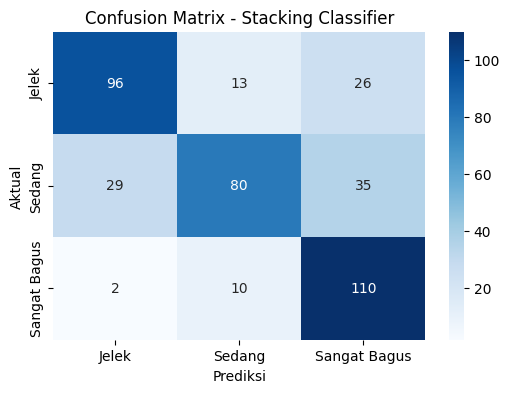

In [ ]:
try:
    # Base models untuk stacking
    estimators = [
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
        ('xgb', XGBClassifier(n_estimators=100, random_state=42)),
        ('gb', GradientBoostingClassifier(n_estimators=100, random_state=42))
    ]
    # Buat dan evaluasi stacking model
    stacking_classifier = StackingClassifier(
        estimators=estimators,
        final_estimator=RandomForestClassifier(n_estimators=100, random_state=42)
    )
    stack_result = evaluate_classification_model(stacking_classifier, X_train, X_test, y_train, y_test, "Stacking Classifier")

except Exception as e:
    print(f"Terjadi kesalahan saat menjalankan model Stacking: {e}")

## 4.4. Kfold 10 lipatan

In [ ]:
def evaluate_classification_model_cv(model, X, y, model_name, classes=class_labels, n_splits=10):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

    fold_accuracies = []

    all_y_true = []
    all_y_pred = []

    fold = 1
    for train_index, test_index in kf.split(X):
        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]

        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        acc = accuracy_score(y_test, y_pred)
        fold_accuracies.append(acc)

        # Simpan semua hasil prediksi dan aktual
        all_y_true.extend(y_test)
        all_y_pred.extend(y_pred)

        fold += 1

    # Hitung akurasi rata-rata
    avg_accuracy = np.mean(fold_accuracies)

    # Evaluasi keseluruhan
    print(f"{model_name} ({n_splits}-Fold CV)")
    print(f"  - Rata-rata Akurasi: {avg_accuracy:.4f}")
    print(classification_report(all_y_true, all_y_pred, target_names=class_labels))

    # Confusion matrix keseluruhan
    plt.figure(figsize=(6, 4))
    cm = confusion_matrix(all_y_true, all_y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_labels,
                yticklabels=class_labels)
    plt.xlabel('Prediksi')
    plt.ylabel('Aktual')
    plt.title(f'Confusion Matrix - {model_name} ({n_splits}-Fold CV)')
    plt.show()

    return model, avg_accuracy

### Random Forest Classifier

Random forest Classifier (10-Fold CV)
  - Rata-rata Akurasi: 0.7415
              precision    recall  f1-score   support

       Jelek       0.79      0.74      0.76       334
      Sedang       0.77      0.61      0.68       334
Sangat Bagus       0.69      0.87      0.77       334

    accuracy                           0.74      1002
   macro avg       0.75      0.74      0.74      1002
weighted avg       0.75      0.74      0.74      1002



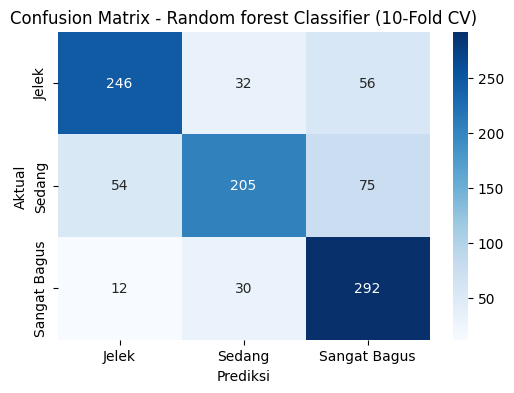

In [ ]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_result = evaluate_classification_model_cv(rf_classifier, X, y, "Random forest Classifier")

### Decision Tree

Decision Tree (10-Fold CV)
  - Rata-rata Akurasi: 0.7385
              precision    recall  f1-score   support

       Jelek       0.78      0.74      0.76       334
      Sedang       0.77      0.61      0.68       334
Sangat Bagus       0.69      0.86      0.77       334

    accuracy                           0.74      1002
   macro avg       0.75      0.74      0.74      1002
weighted avg       0.75      0.74      0.74      1002



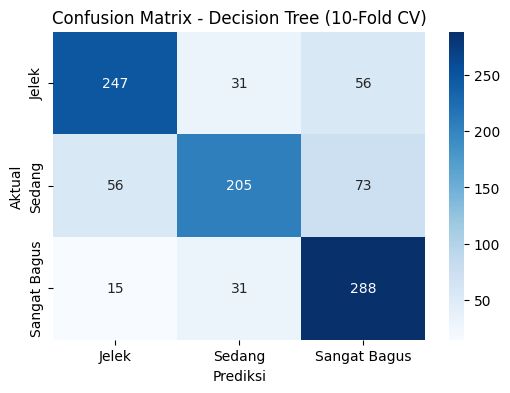

In [ ]:
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_result = evaluate_classification_model_cv(dt_classifier, X, y, "Decision Tree")

### Stacking Classifier

Stacking Classifier (10-Fold CV)
  - Rata-rata Akurasi: 0.7125
              precision    recall  f1-score   support

       Jelek       0.72      0.76      0.74       334
      Sedang       0.80      0.51      0.63       334
Sangat Bagus       0.66      0.87      0.75       334

    accuracy                           0.71      1002
   macro avg       0.73      0.71      0.71      1002
weighted avg       0.73      0.71      0.71      1002



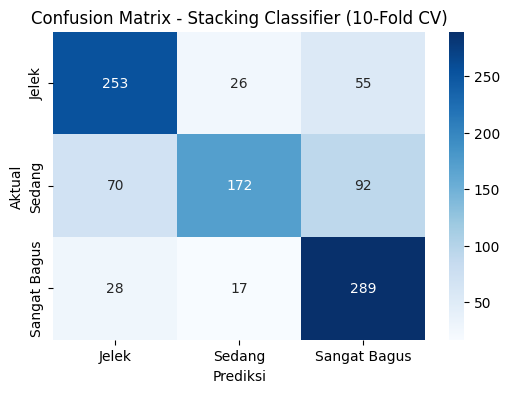

In [ ]:
try:
    # Base models untuk stacking
    estimators = [
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
        ('xgb', XGBClassifier(n_estimators=100, random_state=42)),
        ('gb', GradientBoostingClassifier(n_estimators=100, random_state=42))
    ]
    # Buat dan evaluasi stacking model
    stacking_classifier = StackingClassifier(
        estimators=estimators,
        final_estimator=RandomForestClassifier(n_estimators=100, random_state=42)
    )
    stack_result = evaluate_classification_model_cv(stacking_classifier, X, y, "Stacking Classifier")

except Exception as e:
    print(f"Terjadi kesalahan saat menjalankan model Stacking: {e}")

# Data3: Target ESG LSEG [4 Kelas]

In [ ]:
# Membaca file CSV ke dalam DataFrame
df = pd.read_csv('data3_lseg_4kelas_preprocessing.csv')
print("Jumlah Data:", df.shape)
df.head()

Jumlah Data: (444, 7)


,Pendapatan (Rp),Laba Bersih (Rp),Total Aset (Rp),Utang (Rp),Rasio Profitabilitas (Rp),Sentimen Analisis (X),Skor ESG (LSEG)
0,2,2,2,2,1,1,1
1,3,3,3,3,1,1,2
2,3,0,2,1,0,0,3
3,3,2,3,2,0,1,2
4,2,0,1,0,0,1,2


## **4. Pemodelan [Awal]**

In [ ]:
# Definisikan X dan y
X = df.drop('Skor ESG (LSEG)', axis=1)
y = df['Skor ESG (LSEG)']

# Label kelasnya
class_labels = ['Jelek', 'Sedang', 'Bagus', 'Sangat Bagus']

Jumlah total sampel awal: 444
Jumlah sampel awal: Counter({1: 183, 2: 151, 0: 66, 3: 44})


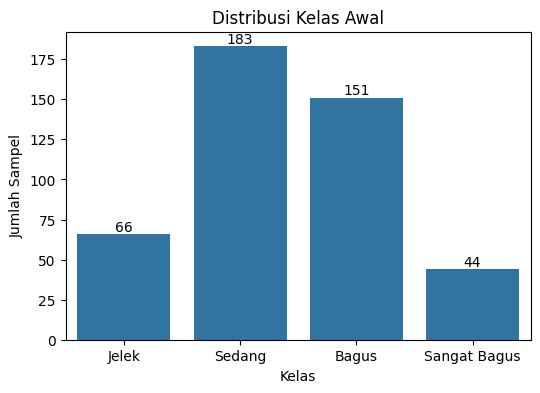

In [ ]:
# Menampilkan jumlah sampel awal
print("Jumlah total sampel awal:", len(y))
print("Jumlah sampel awal:", Counter(y))

# Membuat bar chart distribusi kelas awal
plt.figure(figsize=(6, 4))
sns.countplot(x=y)
plt.title('Distribusi Kelas Awal')
plt.xlabel('Kelas')
plt.xticks(range(len(class_labels)), class_labels)
plt.ylabel('Jumlah Sampel')

# Menambahkan label jumlah data di atas setiap bar
for p in plt.gca().patches:
    plt.gca().annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                       ha='center', va='center', fontsize=10, color='black', xytext=(0, 5),
                       textcoords='offset points')

plt.show()

Jumlah total sampel setelah SMOTE: 732
Jumlah sampel setelah SMOTE: Counter({1: 183, 2: 183, 3: 183, 0: 183})


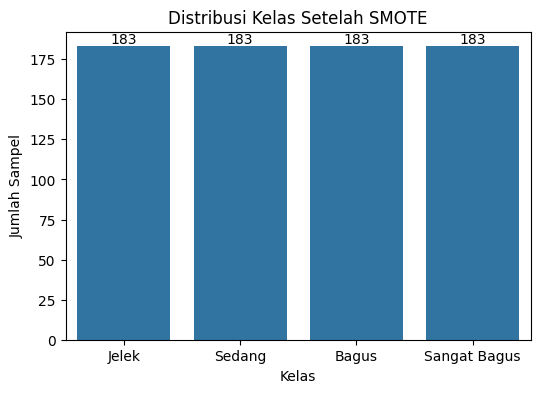

In [ ]:
# Melakukan SMOTE untuk mengatasi ketidakseimbangan kelas
smote = SMOTE(random_state=42)
X, y = smote.fit_resample(X, y)

# Menampilkan jumlah sampel setelah SMOTE
print("Jumlah total sampel setelah SMOTE:", len(y))
print("Jumlah sampel setelah SMOTE:", Counter(y))

# Membuat bar chart distribusi kelas setelah SMOTE
plt.figure(figsize=(6, 4))
sns.countplot(x=y)
plt.title('Distribusi Kelas Setelah SMOTE')
plt.xlabel('Kelas')
plt.xticks(range(len(class_labels)), class_labels)
plt.ylabel('Jumlah Sampel')

# Menambahkan label jumlah data di atas setiap bar
for p in plt.gca().patches:
    plt.gca().annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                       ha='center', va='center', fontsize=10, color='black', xytext=(0, 5),
                       textcoords='offset points')

plt.show()

In [ ]:
# Fungsi untuk evaluasi model klasifikasi (target kategorikal)
def evaluate_classification_model(model, X_train, X_test, y_train, y_test, model_name, classes=class_labels):
    # Latih model
    model.fit(X_train, y_train)

    # Prediksi
    y_pred = model.predict(X_test)

    # Evaluasi
    acc = accuracy_score(y_test, y_pred)

    print(f"{model_name}:")
    print(f"  - Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred, target_names=class_labels))

    # Visualisasi Confusion Matrix
    plt.figure(figsize=(6, 4))
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_labels,
                yticklabels=class_labels
                )
    plt.xlabel('Prediksi')
    plt.ylabel('Aktual')
    plt.title(f'Confusion Matrix - {model_name}')
    plt.show()

    return model, acc

## 4.1. Test size 0.2

In [ ]:
# Bagi dataset menjadi set pelatihan dan pengujian
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Random forest Classifier

Random forest Classifier:
  - Accuracy: 0.6871
              precision    recall  f1-score   support

       Jelek       0.79      0.73      0.76        37
      Sedang       0.59      0.50      0.54        34
       Bagus       0.68      0.63      0.65        43
Sangat Bagus       0.68      0.91      0.78        33

    accuracy                           0.69       147
   macro avg       0.68      0.69      0.68       147
weighted avg       0.69      0.69      0.68       147



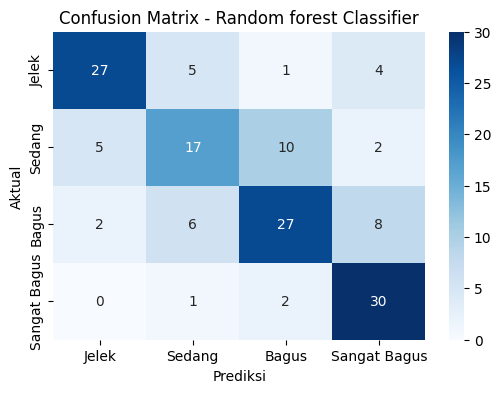

In [ ]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_result = evaluate_classification_model(rf_classifier, X_train, X_test, y_train, y_test, "Random forest Classifier")

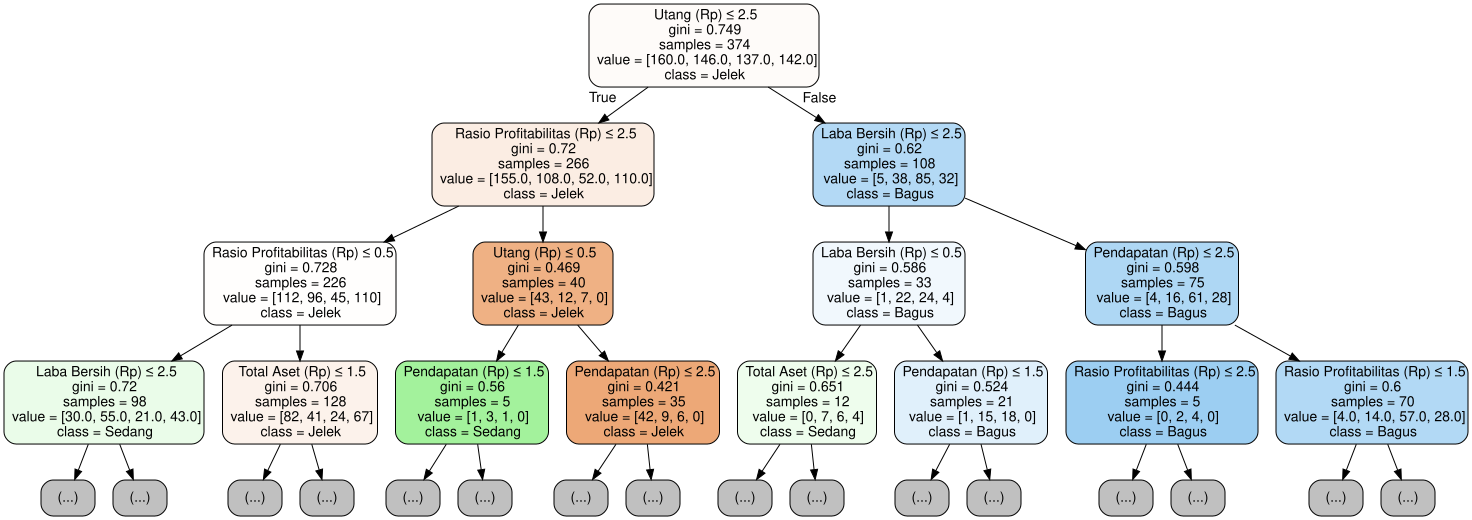

In [ ]:
# Pilih satu pohon dari Random Forest untuk ditampilkan
estimator = rf_classifier.estimators_[0]

# Export pohon ke format DOT
dot_data = export_graphviz(estimator, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat grafik dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan grafik
graph

### Decison Tree

Decision Tree:
  - Accuracy: 0.6803
              precision    recall  f1-score   support

       Jelek       0.74      0.78      0.76        37
      Sedang       0.58      0.44      0.50        34
       Bagus       0.68      0.65      0.67        43
Sangat Bagus       0.68      0.85      0.76        33

    accuracy                           0.68       147
   macro avg       0.67      0.68      0.67       147
weighted avg       0.67      0.68      0.67       147



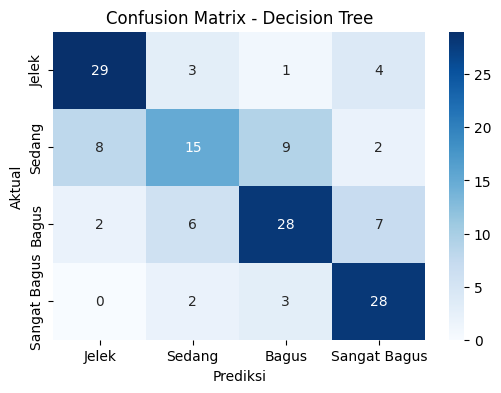

In [ ]:
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_result = evaluate_classification_model(dt_classifier, X_train, X_test, y_train, y_test, "Decision Tree")

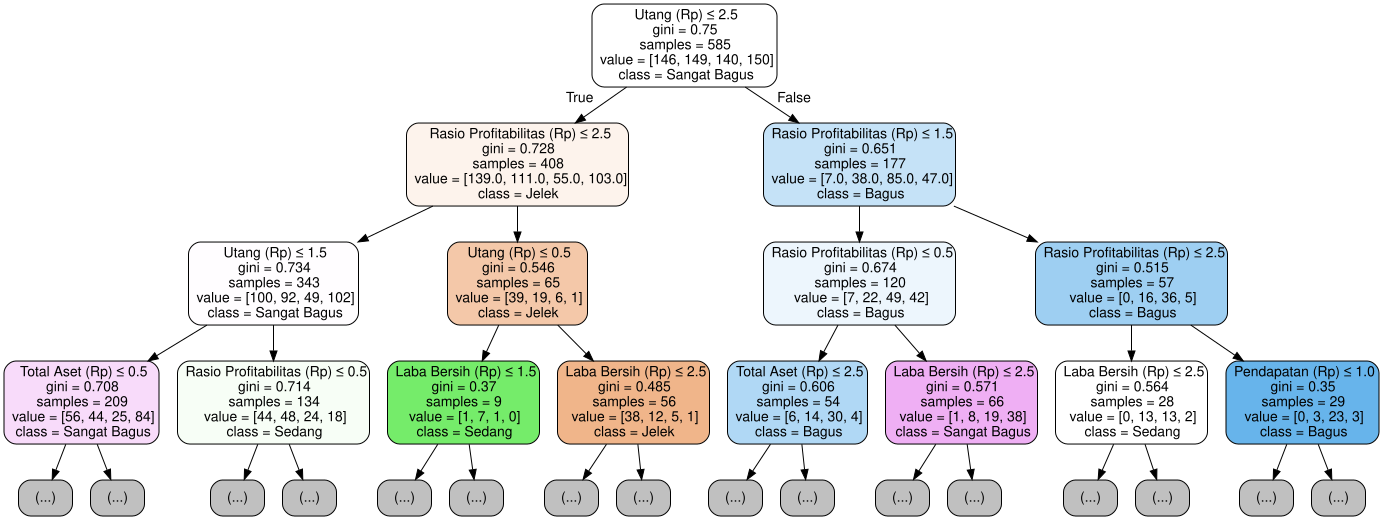

In [ ]:
# Ekspor Decision Tree ke format DOT
dot_data = export_graphviz(dt_classifier, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat objek graphviz dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan tree
graph

### Stacking Classifier

Stacking Classifier:
  - Accuracy: 0.6531
              precision    recall  f1-score   support

       Jelek       0.80      0.76      0.78        37
      Sedang       0.48      0.32      0.39        34
       Bagus       0.67      0.60      0.63        43
Sangat Bagus       0.62      0.94      0.75        33

    accuracy                           0.65       147
   macro avg       0.64      0.66      0.64       147
weighted avg       0.65      0.65      0.64       147



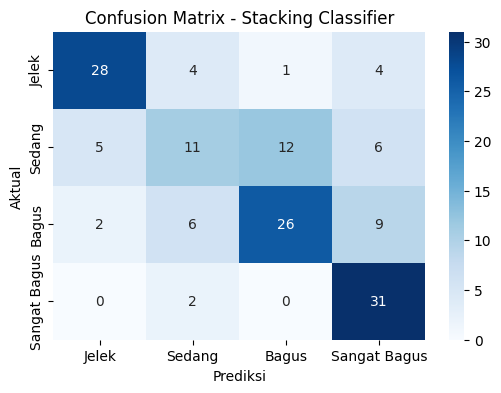

In [ ]:
try:
    # Base models untuk stacking
    estimators = [
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
        ('xgb', XGBClassifier(n_estimators=100, random_state=42)),
        ('gb', GradientBoostingClassifier(n_estimators=100, random_state=42))
    ]

    # Buat dan evaluasi stacking model
    stacking_classifier = StackingClassifier(
        estimators=estimators,
        final_estimator=RandomForestClassifier(n_estimators=100, random_state=42)
    )

    stack_result = evaluate_classification_model(stacking_classifier, X_train, X_test, y_train, y_test, "Stacking Classifier")

except Exception as e:
    print(f"Terjadi kesalahan saat menjalankan model Stacking: {e}")

## 4.2. Test size 0.3

In [ ]:
# Bagi dataset menjadi set pelatihan dan pengujian (Tanpa SMOTE)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

### Random forest Classifier

Random forest Classifier:
  - Accuracy: 0.6636
              precision    recall  f1-score   support

       Jelek       0.75      0.78      0.77        59
      Sedang       0.56      0.51      0.53        49
       Bagus       0.68      0.58      0.63        65
Sangat Bagus       0.64      0.79      0.70        47

    accuracy                           0.66       220
   macro avg       0.66      0.67      0.66       220
weighted avg       0.66      0.66      0.66       220



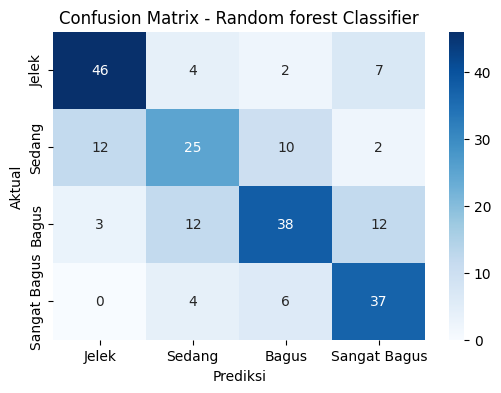

In [ ]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_result = evaluate_classification_model(rf_classifier, X_train, X_test, y_train, y_test, "Random forest Classifier")

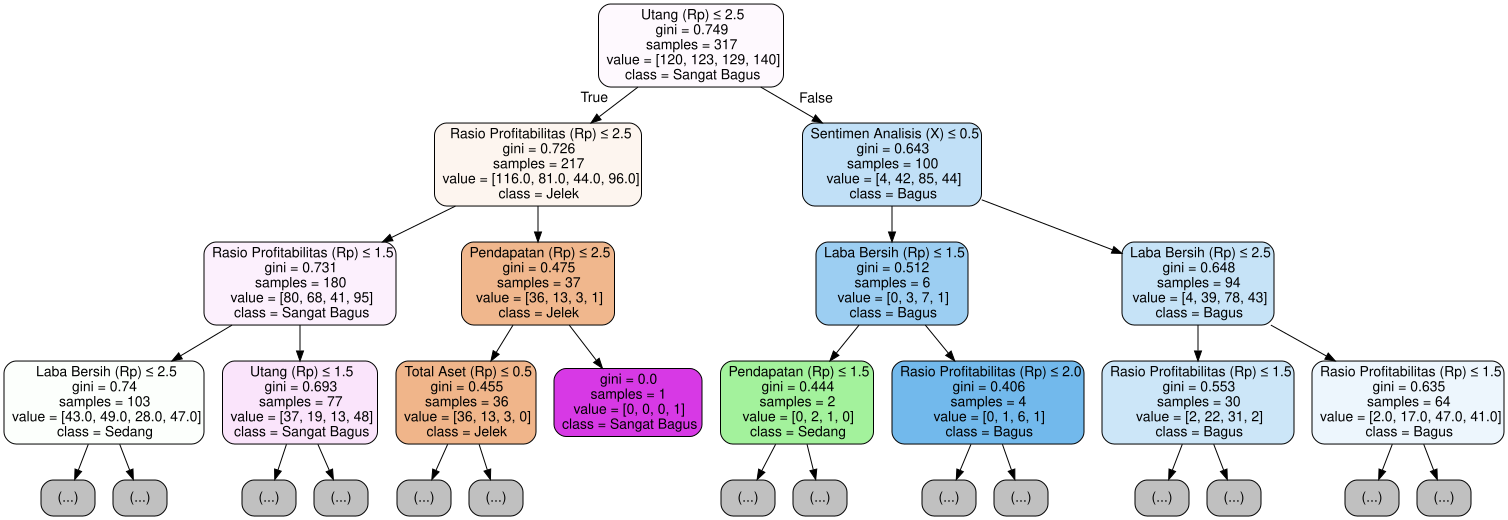

In [ ]:
# Pilih satu pohon dari Random Forest untuk ditampilkan
estimator = rf_classifier.estimators_[0]

# Export pohon ke format DOT
dot_data = export_graphviz(estimator, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat grafik dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan grafik
graph

### Decison Tree

Decision Tree:
  - Accuracy: 0.6727
              precision    recall  f1-score   support

       Jelek       0.75      0.80      0.77        59
      Sedang       0.51      0.49      0.50        49
       Bagus       0.73      0.63      0.68        65
Sangat Bagus       0.67      0.77      0.71        47

    accuracy                           0.67       220
   macro avg       0.66      0.67      0.67       220
weighted avg       0.67      0.67      0.67       220



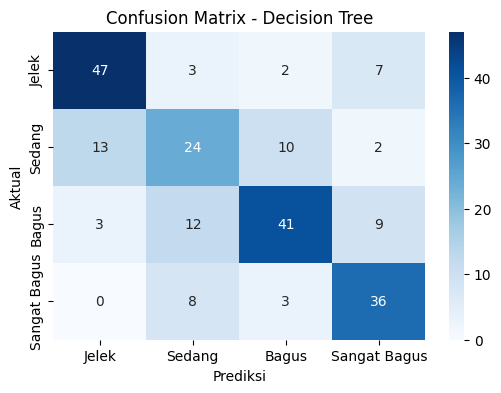

In [ ]:
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_result = evaluate_classification_model(dt_classifier, X_train, X_test, y_train, y_test, "Decision Tree")

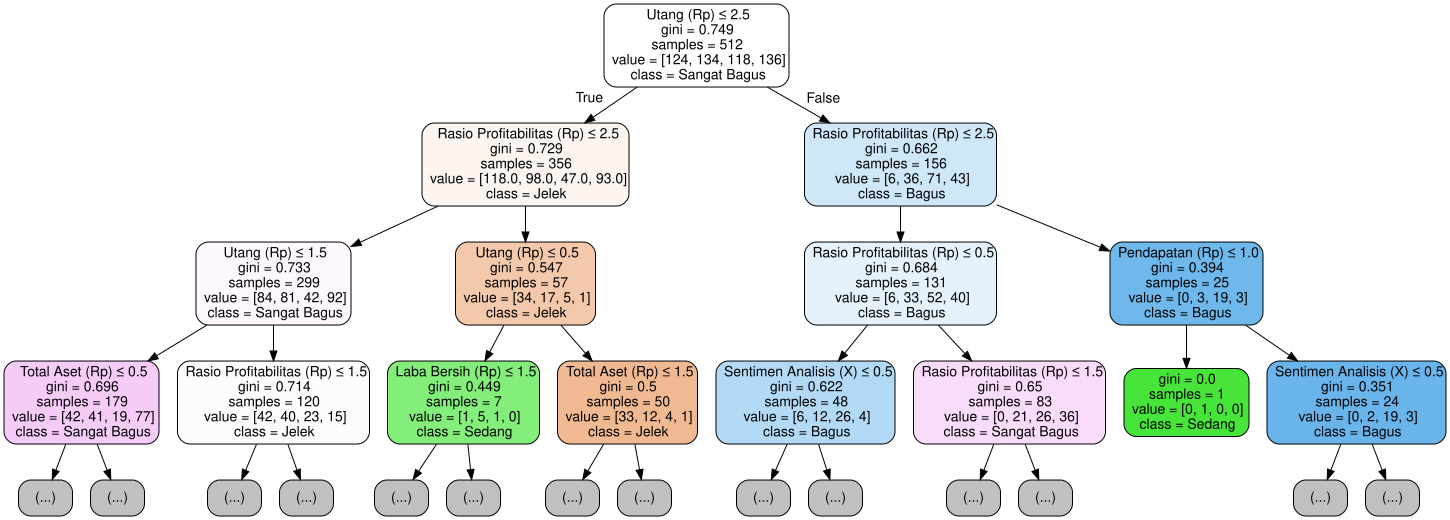

In [ ]:
# Ekspor Decision Tree ke format DOT
dot_data = export_graphviz(dt_classifier, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat objek graphviz dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan tree
graph

### Stacking Classifier

Stacking Classifier:
  - Accuracy: 0.6500
              precision    recall  f1-score   support

       Jelek       0.79      0.71      0.75        59
      Sedang       0.47      0.53      0.50        49
       Bagus       0.71      0.57      0.63        65
Sangat Bagus       0.63      0.81      0.71        47

    accuracy                           0.65       220
   macro avg       0.65      0.66      0.65       220
weighted avg       0.66      0.65      0.65       220



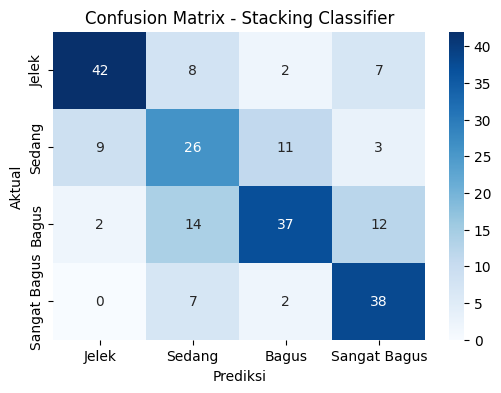

In [ ]:
try:
    # Base models untuk stacking
    estimators = [
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
        ('xgb', XGBClassifier(n_estimators=100, random_state=42)),
        ('gb', GradientBoostingClassifier(n_estimators=100, random_state=42))
    ]

    # Buat dan evaluasi stacking model
    stacking_classifier = StackingClassifier(
        estimators=estimators,
        final_estimator=RandomForestClassifier(n_estimators=100, random_state=42)
    )
    stack_result = evaluate_classification_model(stacking_classifier, X_train, X_test, y_train, y_test, "Stacking Classifier")

except Exception as e:
    print(f"Terjadi kesalahan saat menjalankan model Stacking: {e}")

## 4.3. Test size 0.4

In [ ]:
# Bagi dataset menjadi set pelatihan dan pengujian (Tanpa SMOTE)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

### Random forest Classifier

Random forest Classifier:
  - Accuracy: 0.6416
              precision    recall  f1-score   support

       Jelek       0.72      0.75      0.74        67
      Sedang       0.44      0.47      0.45        64
       Bagus       0.71      0.61      0.65        92
Sangat Bagus       0.68      0.74      0.71        70

    accuracy                           0.64       293
   macro avg       0.64      0.64      0.64       293
weighted avg       0.65      0.64      0.64       293



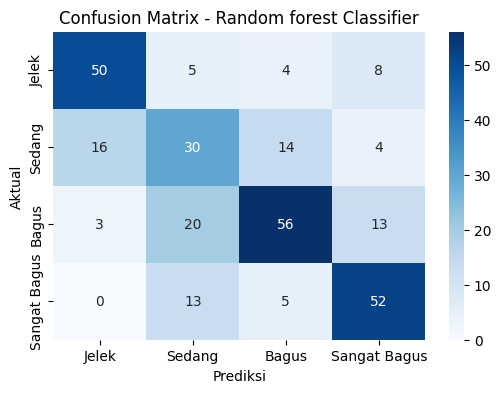

In [ ]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_result = evaluate_classification_model(rf_classifier, X_train, X_test, y_train, y_test, "Random forest Classifier")

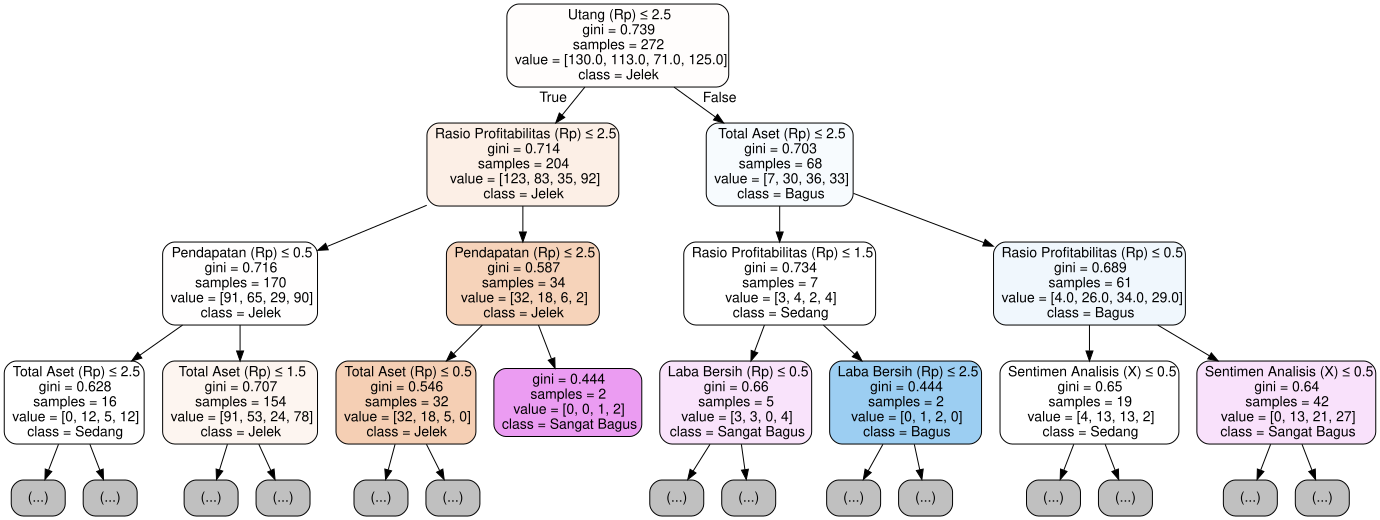

In [ ]:
# Pilih satu pohon dari Random Forest untuk ditampilkan
estimator = rf_classifier.estimators_[0]

# Export pohon ke format DOT
dot_data = export_graphviz(estimator, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat grafik dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan grafik
graph

### Decison Tree

Decision Tree:
  - Accuracy: 0.6416
              precision    recall  f1-score   support

       Jelek       0.68      0.78      0.73        67
      Sedang       0.47      0.42      0.44        64
       Bagus       0.68      0.60      0.64        92
Sangat Bagus       0.69      0.77      0.73        70

    accuracy                           0.64       293
   macro avg       0.63      0.64      0.63       293
weighted avg       0.64      0.64      0.64       293



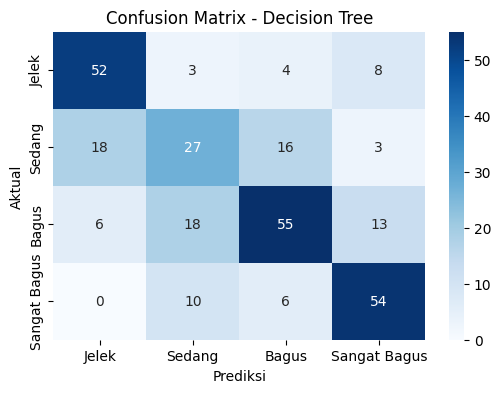

In [ ]:
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_result = evaluate_classification_model(dt_classifier, X_train, X_test, y_train, y_test, "Decision Tree")

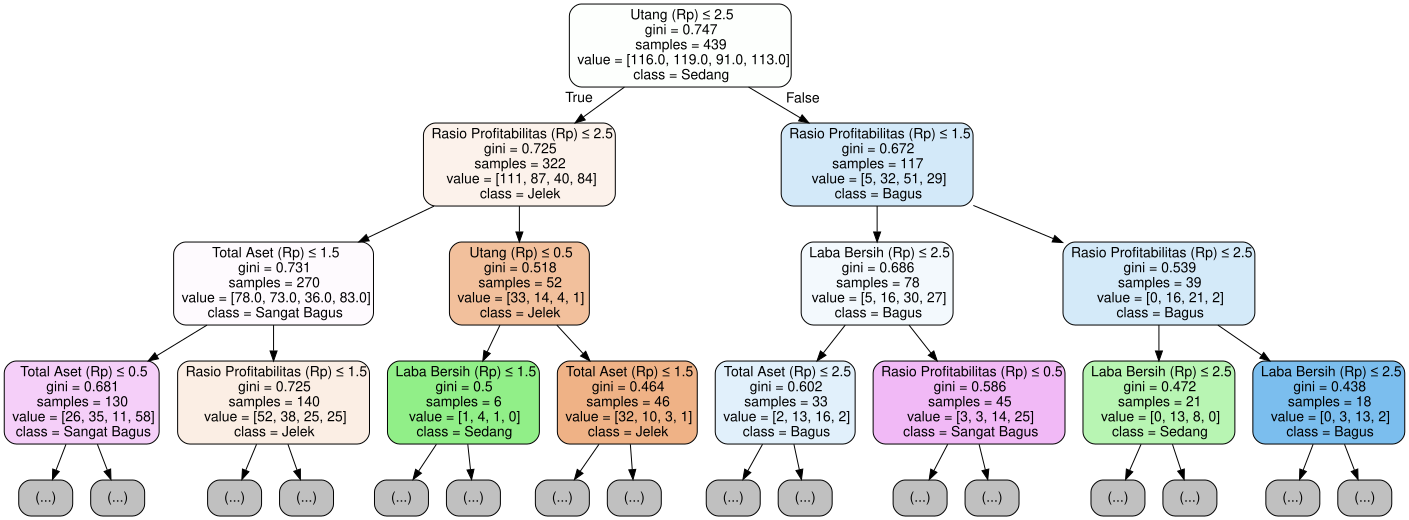

In [ ]:
# Ekspor Decision Tree ke format DOT
dot_data = export_graphviz(dt_classifier, out_file=None,
                           feature_names=X.columns,
                           class_names=class_labels,
                           filled=True, rounded=True,
                           special_characters=True,
                           max_depth=3,
                           )

# Buat objek graphviz dari data DOT
graph = graphviz.Source(dot_data)

# Tampilkan tree
graph

### Stacking Classifier

Stacking Classifier:
  - Accuracy: 0.5734
              precision    recall  f1-score   support

       Jelek       0.66      0.67      0.67        67
      Sedang       0.33      0.42      0.37        64
       Bagus       0.69      0.48      0.56        92
Sangat Bagus       0.65      0.74      0.69        70

    accuracy                           0.57       293
   macro avg       0.58      0.58      0.57       293
weighted avg       0.60      0.57      0.58       293



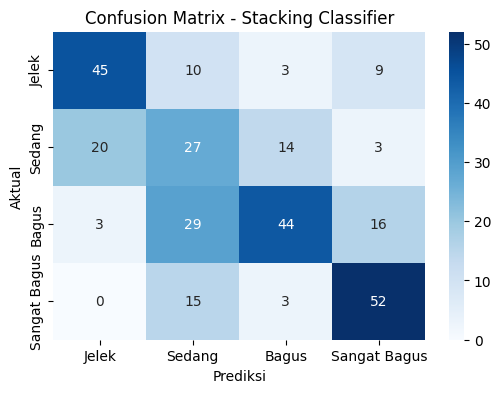

In [ ]:
try:
    # Base models untuk stacking
    estimators = [
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
        ('xgb', XGBClassifier(n_estimators=100, random_state=42)),
        ('gb', GradientBoostingClassifier(n_estimators=100, random_state=42))
    ]
    # Buat dan evaluasi stacking model
    stacking_classifier = StackingClassifier(
        estimators=estimators,
        final_estimator=RandomForestClassifier(n_estimators=100, random_state=42)
    )
    stack_result = evaluate_classification_model(stacking_classifier, X_train, X_test, y_train, y_test, "Stacking Classifier")

except Exception as e:
    print(f"Terjadi kesalahan saat menjalankan model Stacking: {e}")

## 4.4. Kfold 10 lipatan

In [ ]:
def evaluate_classification_model_cv(model, X, y, model_name, classes=class_labels, n_splits=10):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

    fold_accuracies = []

    all_y_true = []
    all_y_pred = []

    fold = 1
    for train_index, test_index in kf.split(X):
        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]

        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        acc = accuracy_score(y_test, y_pred)
        fold_accuracies.append(acc)

        # Simpan semua hasil prediksi dan aktual
        all_y_true.extend(y_test)
        all_y_pred.extend(y_pred)

        fold += 1

    # Hitung akurasi rata-rata
    avg_accuracy = np.mean(fold_accuracies)

    # Evaluasi keseluruhan
    print(f"{model_name} ({n_splits}-Fold CV)")
    print(f"  - Rata-rata Akurasi: {avg_accuracy:.4f}")
    print(classification_report(all_y_true, all_y_pred, target_names=class_labels))

    # Confusion matrix keseluruhan
    plt.figure(figsize=(6, 4))
    cm = confusion_matrix(all_y_true, all_y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_labels,
                yticklabels=class_labels)
    plt.xlabel('Prediksi')
    plt.ylabel('Aktual')
    plt.title(f'Confusion Matrix - {model_name} ({n_splits}-Fold CV)')
    plt.show()

    return model, avg_accuracy

### Random Forest Classifier

Random forest Classifier (10-Fold CV)
  - Rata-rata Akurasi: 0.6461
              precision    recall  f1-score   support

       Jelek       0.73      0.74      0.74       183
      Sedang       0.51      0.45      0.48       183
       Bagus       0.58      0.55      0.56       183
Sangat Bagus       0.73      0.85      0.78       183

    accuracy                           0.65       732
   macro avg       0.64      0.65      0.64       732
weighted avg       0.64      0.65      0.64       732



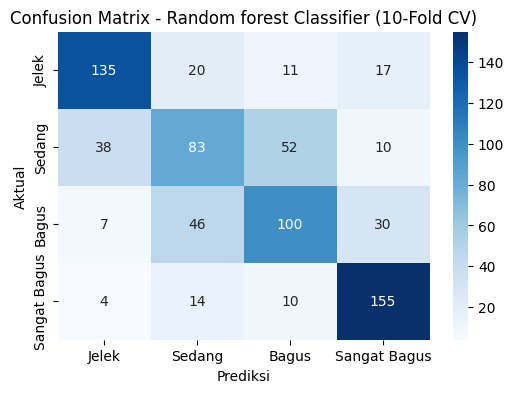

In [ ]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_result = evaluate_classification_model_cv(rf_classifier, X, y, "Random forest Classifier")

### Decision Tree

Decision Tree (10-Fold CV)
  - Rata-rata Akurasi: 0.6503
              precision    recall  f1-score   support

       Jelek       0.70      0.78      0.74       183
      Sedang       0.55      0.50      0.52       183
       Bagus       0.60      0.50      0.54       183
Sangat Bagus       0.72      0.83      0.77       183

    accuracy                           0.65       732
   macro avg       0.64      0.65      0.64       732
weighted avg       0.64      0.65      0.64       732



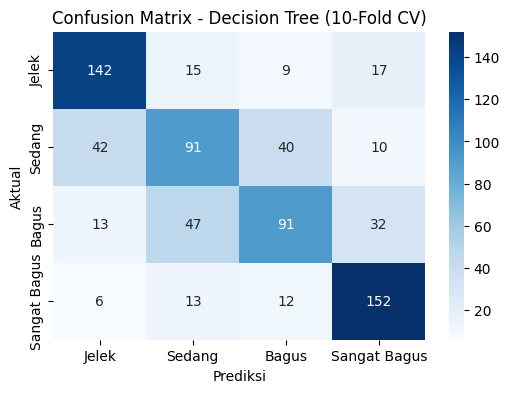

In [ ]:
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_result = evaluate_classification_model_cv(dt_classifier, X, y, "Decision Tree")

### Stacking Classifier

Stacking Classifier (10-Fold CV)
  - Rata-rata Akurasi: 0.6229
              precision    recall  f1-score   support

       Jelek       0.72      0.72      0.72       183
      Sedang       0.46      0.35      0.40       183
       Bagus       0.55      0.55      0.55       183
Sangat Bagus       0.71      0.87      0.78       183

    accuracy                           0.62       732
   macro avg       0.61      0.62      0.61       732
weighted avg       0.61      0.62      0.61       732



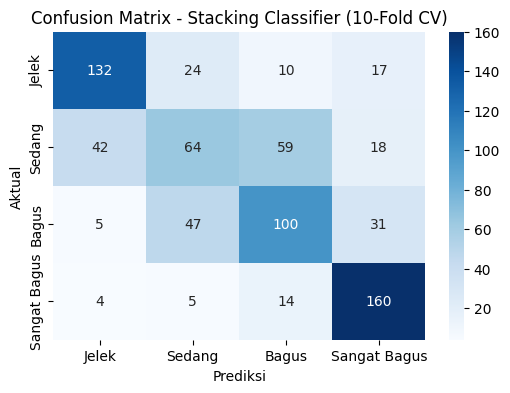

In [ ]:
try:
    # Base models untuk stacking
    estimators = [
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
        ('xgb', XGBClassifier(n_estimators=100, random_state=42)),
        ('gb', GradientBoostingClassifier(n_estimators=100, random_state=42))
    ]
    # Buat dan evaluasi stacking model
    stacking_classifier = StackingClassifier(
        estimators=estimators,
        final_estimator=RandomForestClassifier(n_estimators=100, random_state=42)
    )
    stack_result = evaluate_classification_model_cv(stacking_classifier, X, y, "Stacking Classifier")

except Exception as e:
    print(f"Terjadi kesalahan saat menjalankan model Stacking: {e}")